# Etapa 11c · O cenário B com o professor novo até o fim do caminho, e o comparativo atualizado

| | |
|---|---|
| **Pergunta** | As receitas de poda e de quantização já escolhidas valem para os alunos do professor novo, e onde o cenário B fica na tabela final com ele? |
| **Entrada** | `entregas/11b_alunos_do_professor_maior/` (os alunos do Qwen3-14B); `entregas/07_poda/`, `entregas/08_quantizacao/`, `entregas/10b_encoder_poda/` e `entregas/10c_encoder_quantizacao/` (as receitas); `entregas/11a_professor_aberto_maior/` (os professores abertos); `entregas/10d_comparativo_dos_caminhos/` e as entregas que ela leu (o comparativo anterior); e as 33 execuções desta etapa, gravadas por `especialista/experimentos/etapa11c.py` em `data/execucoes/11c_cenario_b_ate_o_fim/`. |
| **Entrega** | `entregas/11c_cenario_b_ate_o_fim/`: se cada receita passou na sua conferência (`conferencias.csv`, `decisao.json`), os modelos podados e em 8 bits dos alunos novos, e o comparativo atualizado (`comparativo/`), com os sistemas declarados em `sistemas.json`. |
| **Pronto quando** | as regras estão gravadas antes da cadeia e as do comparativo antes das contas; as 33 execuções leram o professor novo com as receitas das etapas de origem; cada receita tem a sua conferência calculada em `dev` e relatada, passe ou não; o ONNX de 32 bits repete o PyTorch; a latência foi medida com a máquina quieta; toda comparação da lista fechada está calculada em `dev` e no teste; o que a Etapa 10d entregou sai igual aqui; nada das outras etapas mudou. |

Este notebook não treina, não poda e não quantiza. A cadeia rodou sozinha (`etapa11c cadeia`), as contas da compressão foram gravadas por `etapa11c fechar` e as do comparativo por `etapa11c calcular`. Aqui só se lê o que ficou gravado.

**Nenhuma decisão é tomada nesta etapa.** As receitas são as que as Etapas 7, 8, 10b e 10c escolheram com os alunos antigos. As regras delas são reaplicadas só como conferência: se uma receita não passa com um aluno novo, isso é dito, e não se procura outra.

**Artigos de apoio.** São os das etapas de origem; cada referência foi conferida na API do arXiv pela Etapa 10d (`entregas/10d_comparativo_dos_caminhos/artigos.csv`), e a seção 12 confere que continuam marcadas como conferidas.

- Han et al., *Learning both Weights and Connections for Efficient Neural Networks*, [arXiv 1506.02626](https://arxiv.org/abs/1506.02626): treinar, podar e treinar de novo.
- Zafrir et al., *Prune Once for All*, [arXiv 2111.05754](https://arxiv.org/abs/2111.05754): o reajuste depois da poda, com o sinal do professor.
- Yang, Cui & Chen, *TextPruner*, [arXiv 2203.15996](https://arxiv.org/abs/2203.15996): o corte do vocabulário de um encoder pré-treinado.
- Abdaoui, Pradel & Sigel, *Load What You Need*, [arXiv 2010.05609](https://arxiv.org/abs/2010.05609): num modelo multilíngue, a maior parte dos parâmetros está na tabela de entrada.
- Jacob et al., *Quantization and Training of Neural Networks for Efficient Integer-Arithmetic-Only Inference*, [arXiv 1712.05877](https://arxiv.org/abs/1712.05877): inteiros de 8 bits.
- Zafrir et al., *Q8BERT*, [arXiv 1910.06188](https://arxiv.org/abs/1910.06188): o que quantizar num Transformer.
- Hinton, Vinyals & Dean, *Distilling the Knowledge in a Neural Network*, [arXiv 1503.02531](https://arxiv.org/abs/1503.02531): rótulos e logits do professor.
- Reddi et al., *MLPerf Inference Benchmark*, [arXiv 1911.02549](https://arxiv.org/abs/1911.02549): latência de uma consulta por vez.
- Dehghani et al., *The Efficiency Misnomer*, [arXiv 2110.12894](https://arxiv.org/abs/2110.12894): custo em mais de uma medida, com a condição de cada uma.

**Seções**

1. O que foi fixado antes de rodar
2. A cadeia de execuções
3. As receitas passam na conferência?
4. Cada linha dos alunos novos: qualidade, tamanho e latência
5. O comparativo: regras, registro e conferência
6. As cadeias do cenário B, novas ao lado das antigas
7. A distância entre os cenários A e B, antes e depois da troca de professor
8. A troca de professor, ponto a ponto
9. Os professores lado a lado
10. A tabela final e a fronteira
11. Onde `dev` e teste discordam
12. Entrega
13. Resposta

In [1]:
import json
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from especialista import visual
from especialista.avaliacao.previsao import carregar_previsoes
from especialista.caminhos import ENTREGAS, RAIZ
from especialista.dados import massive
from especialista.experimentos import etapa10d, etapa11a, etapa11b, etapa11c

visual.aplicar_estilo()
pd.set_option("display.max_colwidth", 200)

PROFESSOR = etapa11c.PROFESSOR
BASE = etapa11c.pasta_da_etapa()                       # data/execucoes/11c_cenario_b_ate_o_fim
PASTA = ENTREGAS / etapa11c.ETAPA
regras = etapa11c.exigir_regras()
contas = etapa11c.carregar_contas()                    # gravado por `python -m especialista.experimentos.etapa11c fechar`
conf, res, comp1, efi, rea = (contas[k] for k in ("conferencias", "resultados", "comparacoes", "eficiencia", "reajustes"))
calc = etapa11c.carregar_calculo()                     # gravado por `python -m especialista.experimentos.etapa11c calcular`
T, PP, CAD, FRONT, CF, calculo = (calc[k] for k in ("tabela_final", "comparacoes", "cadeias", "fronteira", "conferencia", "calculo"))
regras_cmp, arquivo_das_regras = etapa11c.carregar_regras_do_comparativo()
v3 = json.loads((BASE / "comparativo" / "regras_v3.json").read_text(encoding="utf-8"))
cadeia = json.loads(sorted((BASE / "cadeias").glob("cadeia_*.json"))[-1].read_text(encoding="utf-8"))
ALUNOS, R = etapa11c.alunos(), etapa11c.receitas()
CAMINHOS = {"zero": "Rede do zero", "xlmr": "XLM-R"}
P = {c: etapa10d.CAMINHOS[c]["prefixo"] for c in CAMINHOS}
NOVO = regras["professor"]["nome"]                     # o professor aberto dos alunos novos
ANTIGO, FECHADO = "Qwen3-8B em 4 bits", "Claude Haiku 5.5"
A = {c: P[c] + "aluno_a" for c in CAMINHOS}                                   # as chaves do registro
B2_ANTIGO = {c: P[c] + "aluno_b2" for c in CAMINHOS}
B2_NOVO = {c: f"{P[c]}aluno_b2@{PROFESSOR}" for c in CAMINHOS}
REPRESENTA = {a["caminho"]: a["chave"] for a in ALUNOS.values() if a["representa"]}
SIGLA_DO_REPRESENTANTE = {a["caminho"]: a["sigla"] for a in ALUNOS.values() if a["representa"]}
TRES = ("intent_acc", "slot_f1", "exact_match")
CURTA = {"intent_acc": "Intenção", "slot_f1": "Entidades (F1)", "exact_match": "Exact match"}
NOME_DA_PARTICAO = {"dev": "dev", "test": "teste"}
SEM_PODA = etapa11c.SEM_PODA


def n(x):
    return f"{int(x):,}".replace(",", ".")


def num(x, casas=1):
    return f"{x:.{casas}f}".replace(".", ",")


def pts(x, casas=1):
    return num(100 * x, casas)


def dif(x, casas=1):
    return f"{100 * x:+.{casas}f}".replace(".", ",").replace("-", "−")


def ci(linha):
    return f"{dif(linha['diferenca'])} ({dif(linha['ic_min'])} a {dif(linha['ic_max'])})"


def leitura(linha):
    """O que o intervalo permite dizer de uma diferença B − A."""
    return "acima" if linha["ic_min"] > 0 else "abaixo" if linha["ic_max"] < 0 else "sem diferença distinguível"


def trio(linha):
    return (100 * linha["diferenca"], 100 * linha["ic_min"], 100 * linha["ic_max"])


def par(b, a, particao="test", metrica="exact_match"):
    """Uma comparação pareada B − A da lista fechada do comparativo."""
    return PP[(PP["chave_b"] == b) & (PP["chave_a"] == a) & (PP["particao"] == particao) & (PP["metrica"] == metrica)].iloc[0]


def q(chave, metrica="exact_match", particao="test"):
    antes = "" if particao == "test" else "dev_"
    return tuple(T.loc[chave, f"{antes}{metrica}{sufixo}"] for sufixo in ("", "_ic_min", "_ic_max"))


def qci(chave, metrica="exact_match", particao="test"):
    valor, minimo, maximo = q(chave, metrica, particao)
    return f"{pts(valor)} ({pts(minimo)} a {pts(maximo)})"


def megas(chave):
    return "não medido" if pd.isna(T.loc[chave, "bytes"]) else num(T.loc[chave, "bytes"] / 1e6, 1 if T.loc[chave, "bytes"] >= 1e7 else 2)


def ms(chave):
    return "não medida" if pd.isna(T.loc[chave, "latencia_p50_ms"]) else num(T.loc[chave, "latencia_p50_ms"], 1 if T.loc[chave, "latencia_p50_ms"] >= 10 else 2)


def em_markdown(tabela):
    """Uma tabela pequena em Markdown, para o resumo."""
    linhas = ["| " + " | ".join(str(c) for c in tabela.columns) + " |", "|" + "---|" * len(tabela.columns)]
    return "\n".join(linhas + ["| " + " | ".join(str(v) for v in linha) + " |" for linha in tabela.itertuples(index=False)])


def lista(itens):
    itens = list(itens)
    return itens[0] if len(itens) == 1 else ", ".join(itens[:-1]) + " e " + itens[-1]


nome_do_aluno = lambda a: f"aluno {a['sigla']} {'da rede do zero' if a['caminho'] == 'zero' else 'do XLM-R'}"
print(etapa11c.situacao())

qwen3_14b__fp16__colab_a100: 33 de 33 execuções prontas (poda 9 de 9, quantizar 18 de 18, latencia 6 de 6)


## 1. O que foi fixado antes de rodar

As regras foram gravadas antes do teste de fumaça e da cadeia (`regras.json`). Elas dizem quem é comprimido, com que receita, o que é conferido e como o custo é medido. O quadro abaixo é lido delas.

In [2]:
quadro_dos_alunos = pd.DataFrame([{
    "Aluno": a["curto"], "Caminho": CAMINHOS[a["caminho"]], "Papel": a["papel"], "Poda (de onde)": f"{R[a['caminho']]['nome_da_poda']} ({R[a['caminho']]['de']['poda'].split('/')[1]})",
    "Reajuste": f"{R[a['caminho']]['reajuste']['epocas']} épocas, com o sinal do {NOVO}", "8 bits (de onde)": f"{R[a['caminho']]['nome_da_forma']} ({R[a['caminho']]['de']['forma'].split('/')[1]})",
} for a in ALUNOS.values()])
inicio_da_cadeia = cadeia["iniciada_em"]
texto_das_regras = (
    f"As regras foram gravadas em {regras['escritas_em'][:16]}; a cadeia começou em {inicio_da_cadeia[:16]}. São {len(ALUNOS)} alunos: em cada caminho, o que a regra de \"quem segue\" aponta como "
    f"representante do cenário B com o {NOVO} ({'; '.join(f'{CAMINHOS[c]}: {SIGLA_DO_REPRESENTANTE[c]}' for c in CAMINHOS)}) e, no XLM-R, também o B2, porque a cadeia antiga do cenário B é de B2. "
    f"A grade tem {regras['execucoes']['total']} execuções: {regras['execucoes']['poda']} podas com reajuste, {regras['execucoes']['quantizar']} exportações com quantização "
    f"(o modelo podado e, como referência, o mesmo aluno sem poda) e {regras['execucoes']['latencia']} medidas de latência."
)
display(Markdown(texto_das_regras))
display(quadro_dos_alunos)
display(Markdown("**Conferências fixadas.** " + " ".join(f"**{nome.capitalize()}:** {c['regra_de_origem']}." for nome, c in regras["conferencias"].items() if isinstance(c, dict))
                 + f" **Se não passar:** {regras['conferencias']['se_nao_passar']}."))

As regras foram gravadas em 2026-11-19 00:40; a cadeia começou em 2026-11-19 00:45. São 3 alunos: em cada caminho, o que a regra de "quem segue" aponta como representante do cenário B com o Qwen3-14B (Rede do zero: B2; XLM-R: B1) e, no XLM-R, também o B2, porque a cadeia antiga do cenário B é de B2. A grade tem 33 execuções: 9 podas com reajuste, 18 exportações com quantização (o modelo podado e, como referência, o mesmo aluno sem poda) e 6 medidas de latência.

,Aluno,Caminho,Papel,Poda (de onde),Reajuste,8 bits (de onde)
0,Aluno B2 · Qwen3-14B,Rede do zero,representa o cenário B neste caminho,Sem 90% das linhas da tabela de features (07_poda),"30 épocas, com o sinal do Qwen3-14B","INT8, quantização dinâmica (08_quantizacao)"
1,Aluno B1 · Qwen3-14B,XLM-R,representa o cenário B neste caminho,Vocabulário do treino (10b_encoder_poda),"10 épocas, com o sinal do Qwen3-14B","INT8, quantização dinâmica (10c_encoder_quantizacao)"
2,Aluno B2 · Qwen3-14B,XLM-R,"entra para a cadeia ficar comparável com a antiga, que é de B2",Vocabulário do treino (10b_encoder_poda),"10 épocas, com o sinal do Qwen3-14B","INT8, quantização dinâmica (10c_encoder_quantizacao)"


**Conferências fixadas.** **Poda:** a das Etapas 7 e 10b (`etapa7.quem_segue`, passo 1): passa a poda cujo exact match em dev, depois do reajuste, não é distinguivelmente menor que o do modelo sem poda (o intervalo de 95% da diferença pareada, na média de 3 sementes, não fica todo abaixo de zero). **Quantizacao:** a das Etapas 8 e 10c (`etapa8.escolher_forma`, passo 1; PLANO.md): passa a forma cuja queda de F1 de entidades é de no máximo 1 ponto em dev, contra o mesmo modelo em 32 bits no PyTorch (diferença pareada, média de 3 sementes). **Se não passar:** a receita que não passar com um aluno novo é relatada como está; não se procura outra poda, outra forma, outro orçamento de reajuste nem treino ciente de quantização.

## 2. A cadeia de execuções

A cadeia rodou desacoplada, numa ordem só: poda e reajuste, depois exportação e quantização, e a latência por último, um modelo por vez. O código que poda e quantiza é o das etapas de origem, sem mudança; dentro de um bloco (`etapa11c.emprestar`), o modelo de partida, o professor e a pasta de gravação são os desta etapa.

In [3]:
conferido = cadeia["conferido"]
onnx = conferido["onnx_de_32_bits"]
reajustes = rea.assign(quem=rea["nome"] + " (" + rea["caminho"].map(CAMINHOS) + ")").groupby("quem", sort=False).agg(
    sementes=("semente", "count"), epocas=("epocas", "first"), epoca_escolhida=("melhor_epoca", lambda e: ", ".join(str(int(x)) for x in e)), segundos=("segundos", "mean"),
    antes=("exact_match_no_dev_do_professor_antes", "mean"), depois=("exact_match_no_dev_do_professor_depois", "mean"), parametros_antes=("parametros_de_partida", "first"), parametros=("parametros", "first"))
quadro_dos_reajustes = pd.DataFrame({
    "Épocas do reajuste": reajustes["epocas"], "Época escolhida (3 sementes)": reajustes["epoca_escolhida"], "Segundos por execução": reajustes["segundos"].map(lambda s: num(s, 0)),
    "Exact match no dev do professor, antes do reajuste": reajustes["antes"].map(pts), "depois": reajustes["depois"].map(pts),
    "Parâmetros (de → para)": [f"{n(a)} → {n(d)}" for a, d in zip(reajustes["parametros_antes"], reajustes["parametros"])],
})
texto_da_cadeia = (
    f"A cadeia rodou de {cadeia['iniciada_em'][11:16]} a {cadeia['terminada_em'][11:16]} ({num(cadeia['minutos'], 0)} minutos): {cadeia['prontas']} de {len(cadeia['previstas'])} execuções prontas, "
    f"{len(cadeia['erros'])} com erro. O código do pacote {'não mudou' if cadeia['codigo_igual_do_inicio_ao_fim'] else 'MUDOU'} durante a cadeia. "
    f"Toda poda leu os rótulos (e, no B2, os logits) da pasta do {NOVO} e partiu da entrega da Etapa 11b: {'sim' if not conferido['podas_que_nao_leram_do_professor'] else 'NÃO'}. "
    f"O ONNX de 32 bits deu a mesma resposta do PyTorch em {n(onnx['iguais_ao_pytorch'])} de {n(onnx['pedidos'])} respostas. "
    f"Durante as medidas de latência, os outros processos ocuparam no máximo {num(efi['nucleos_de_outros_processos'].max(), 2)} núcleo de CPU (o limite é {num(etapa11c.LIMITE_DE_OUTROS, 2)}); "
    + ("nenhuma medida foi recusada." if efi["medidas_recusadas"].sum() == 0 else "houve medidas recusadas e refeitas.")
)
display(Markdown(texto_da_cadeia))
quadro_dos_reajustes

A cadeia rodou de 00:45 a 02:01 (76 minutos): 33 de 33 execuções prontas, 0 com erro. O código do pacote não mudou durante a cadeia. Toda poda leu os rótulos (e, no B2, os logits) da pasta do Qwen3-14B e partiu da entrega da Etapa 11b: sim. O ONNX de 32 bits deu a mesma resposta do PyTorch em 90.126 de 90.126 respostas. Durante as medidas de latência, os outros processos ocuparam no máximo 0,03 núcleo de CPU (o limite é 0,25); nenhuma medida foi recusada.

,Épocas do reajuste,Época escolhida (3 sementes),Segundos por execução,"Exact match no dev do professor, antes do reajuste",depois,Parâmetros (de → para)
quem,,,,,,
Aluno B2 · Qwen3-14B (Rede do zero),30,"25, 30, 30",129,"41,0","53,5",4.895.834 → 1.992.538
Aluno B1 · Qwen3-14B (XLM-R),10,"10, 10, 10",115,"60,0","60,5",277.584.555 → 89.573.547
Aluno B2 · Qwen3-14B (XLM-R),10,"9, 0, 5",115,"60,3","61,0",277.584.555 → 89.573.547


O "dev do professor" da tabela é o conjunto que escolhe a época de parada: os pedidos de `dev` com os rótulos do Qwen3-14B. Não é a régua da etapa. A régua, com rótulos humanos, vem a seguir.

## 3. As receitas passam na conferência?

Cada receita é conferida com a regra da etapa que a escolheu, em `dev`, com os rótulos humanos, na média de 3 sementes:

- **poda**: o exact match do modelo podado e reajustado não pode ficar distinguivelmente abaixo do aluno sem poda (o intervalo de 95% da diferença pareada não fica todo abaixo de zero);
- **8 bits**: o F1 de entidades cai no máximo 1 ponto em relação ao mesmo modelo em 32 bits;
- **ONNX de 32 bits**: todas as respostas iguais às do PyTorch.

**7 de 9 conferências passam.** Poda: 1 de 3. 8 bits: 3 de 3. ONNX de 32 bits: 3 de 3. **Não passa:** a poda "vocabulário do treino" com o aluno B1 do XLM-R: exact match em dev de 50,4 para 49,4, −1,0 (−1,8 a −0,3); a poda "vocabulário do treino" com o aluno B2 do XLM-R: exact match em dev de 50,8 para 49,9, −0,9 (−1,7 a −0,2).

,Aluno,Caminho,Conferência,Receita,Sem a receita,Com a receita,Diferença (IC de 95%),Critério,Passa?
0,Aluno B2 · Qwen3-14B,Rede do zero,poda: exact match em dev,Sem 90% das linhas da tabela de features,"48,5","48,0","−0,4 (−1,5 a +0,7)",o intervalo de 95% da diferença não fica todo abaixo de zero,sim
1,Aluno B2 · Qwen3-14B,Rede do zero,8 bits: F1 de entidades em dev,"INT8, quantização dinâmica","62,0","61,9","−0,1 (−0,2 a +0,1)",a queda é de no máximo 1 ponto,sim
2,Aluno B2 · Qwen3-14B,Rede do zero,ONNX de 32 bits = PyTorch,exportação,15.021 respostas,15.021 iguais,0,"todas as respostas iguais, nas 3 sementes",sim
3,Aluno B1 · Qwen3-14B,XLM-R,poda: exact match em dev,Vocabulário do treino,"50,4","49,4","−1,0 (−1,8 a −0,3)",o intervalo de 95% da diferença não fica todo abaixo de zero,NÃO
4,Aluno B1 · Qwen3-14B,XLM-R,8 bits: F1 de entidades em dev,"INT8, quantização dinâmica","62,8","62,8","−0,0 (−0,5 a +0,5)",a queda é de no máximo 1 ponto,sim
5,Aluno B1 · Qwen3-14B,XLM-R,ONNX de 32 bits = PyTorch,exportação,15.021 respostas,15.021 iguais,0,"todas as respostas iguais, nas 3 sementes",sim
6,Aluno B2 · Qwen3-14B,XLM-R,poda: exact match em dev,Vocabulário do treino,"50,8","49,9","−0,9 (−1,7 a −0,2)",o intervalo de 95% da diferença não fica todo abaixo de zero,NÃO
7,Aluno B2 · Qwen3-14B,XLM-R,8 bits: F1 de entidades em dev,"INT8, quantização dinâmica","62,9","62,6","−0,3 (−0,9 a +0,2)",a queda é de no máximo 1 ponto,sim
8,Aluno B2 · Qwen3-14B,XLM-R,ONNX de 32 bits = PyTorch,exportação,15.021 respostas,15.021 iguais,0,"todas as respostas iguais, nas 3 sementes",sim


PosixPath('/home/danie/project/residencia/entregas/11c_cenario_b_ate_o_fim/figuras/conferencia_dos_8_bits.png')

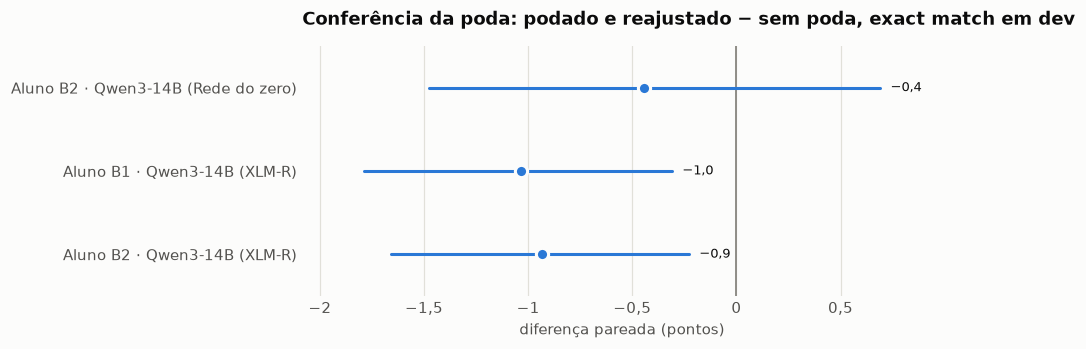

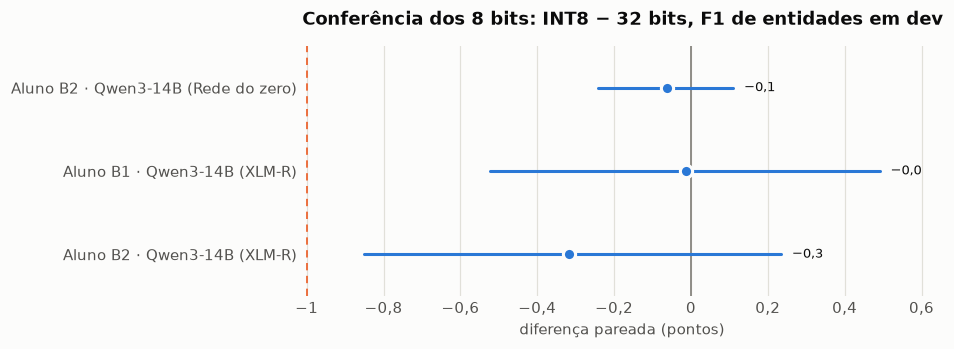

In [4]:
principais = conf[conf["conta_para_a_resposta"]].copy()
EM_MINUSCULA = {"exact_match": "exact match", "slot_f1": "F1 de entidades", "intent_acc": "acurácia de intenção"}
nome_da_receita = lambda l: R[l["caminho"]]["nome_da_poda"] if l["conferencia"] == "poda" else R[l["caminho"]]["nome_da_forma"]


def linha_da_conferencia(l):
    if l["conferencia"] == "ONNX de 32 bits":
        return {"Aluno": l["nome"], "Caminho": CAMINHOS[l["caminho"]], "Conferência": "ONNX de 32 bits = PyTorch", "Receita": "exportação", "Sem a receita": n(l["referencia"]) + " respostas",
                "Com a receita": n(l["com_a_receita"]) + " iguais", "Diferença (IC de 95%)": n(l["diferenca"]), "Critério": l["criterio"], "Passa?": "sim" if l["passa"] else "NÃO"}
    return {"Aluno": l["nome"], "Caminho": CAMINHOS[l["caminho"]], "Conferência": f"{l['conferencia']}: {EM_MINUSCULA[l['metrica']]} em dev", "Receita": nome_da_receita(l), "Sem a receita": pts(l["referencia"]),
            "Com a receita": pts(l["com_a_receita"]), "Diferença (IC de 95%)": ci(l), "Critério": l["criterio"], "Passa?": "sim" if l["passa"] else "NÃO"}


quadro_das_conferencias = pd.DataFrame([linha_da_conferencia(l) for _, l in principais.iterrows()])
nao_passam = principais[~principais["passa"]]
aluno_de = {nome: a for nome, a in ALUNOS.items()}
frase_do_que_nao_passa = "; ".join(
    f"a poda \"{R[l['caminho']]['nome_da_poda'].lower()}\" com o {nome_do_aluno(aluno_de[l['aluno']])}: {EM_MINUSCULA[l['metrica']]} em dev de {pts(l['referencia'])} para {pts(l['com_a_receita'])}, {ci(l)}"
    if l["conferencia"] == "poda" else f"{l['conferencia']} com o {nome_do_aluno(aluno_de[l['aluno']])}: {ci(l)}" for _, l in nao_passam.iterrows())
passam_por_tipo = {tipo: (int(g["passa"].sum()), len(g)) for tipo, g in principais.groupby("conferencia", sort=False)}
texto_das_conferencias = (
    f"**{int(principais['passa'].sum())} de {len(principais)} conferências passam.** "
    + " ".join(f"{tipo[0].upper() + tipo[1:]}: {p} de {t}." for tipo, (p, t) in passam_por_tipo.items())
    + (f" **Não passa:** {frase_do_que_nao_passa}." if len(nao_passam) else " Todas as receitas passam com os alunos novos.")
)
display(Markdown(texto_das_conferencias))
display(quadro_das_conferencias)

dados = {f"{l['nome']} ({CAMINHOS[l['caminho']]})": trio(l) for _, l in principais[principais["conferencia"] == "poda"].iterrows()}
fig, ax = visual.diferencas_com_intervalo(dados, "Conferência da poda: podado e reajustado − sem poda, exact match em dev", "diferença pareada (pontos)")
visual.salvar(fig, PASTA, "conferencia_da_poda")
dados = {f"{l['nome']} ({CAMINHOS[l['caminho']]})": trio(l) for _, l in principais[principais["conferencia"] == "8 bits"].iterrows()}
fig, ax = visual.diferencas_com_intervalo(dados, "Conferência dos 8 bits: INT8 − 32 bits, F1 de entidades em dev", "diferença pareada (pontos)")
ax.axvline(-1, color=visual.LARANJA, linewidth=1.2, linestyle=(0, (4, 3)), zorder=0.6)
visual.salvar(fig, PASTA, "conferencia_dos_8_bits")

Na figura dos 8 bits, a linha tracejada é o limite de 1 ponto. As mesmas diferenças no teste, e os dois passos da poda (o corte antes do reajuste, e o reajuste), ficam como registro: nenhuma regra os lê.

In [5]:
def do_registro(nome, variante, rotulo, particao, metrica="exact_match"):
    return comp1[(comp1["modelo"] == nome) & (comp1["variante"] == variante) & (comp1["comparacao"] == rotulo) & (comp1["particao"] == particao) & (comp1["metrica"] == metrica)].iloc[0]


linhas = []
for nome, a in ALUNOS.items():
    poda, forma = R[a["caminho"]]["poda"], R[a["caminho"]]["forma"]
    for rotulo, variante, comparacao in (("corte, antes do reajuste − sem poda", poda, "antes − sem poda"), ("reajuste: depois − antes", poda, "depois − antes"),
                                         ("podado e reajustado − sem poda", poda, "depois − sem poda"), ("INT8 − 32 bits, no modelo podado", poda, f"{forma} − pytorch"),
                                         ("INT8 − 32 bits, no modelo sem poda", SEM_PODA, f"{forma} − pytorch")):
        linhas.append({"Aluno": a["curto"], "Caminho": CAMINHOS[a["caminho"]], "Diferença": rotulo,
                       **{f"{CURTA[m]} ({NOME_DA_PARTICAO[p]})": ci(do_registro(nome, variante, comparacao, p, m)) for m in ("exact_match", "slot_f1") for p in ("dev", "test")}})
registro_da_compressao = pd.DataFrame(linhas)
cpu_igual_a_placa = comp1[comp1["comparacao"] == "pytorch − respostas de origem"]
texto_do_registro = (f"As respostas de cada rede na CPU (a referência dos 8 bits) são as mesmas que a etapa que a treinou gravou: "
                     f"{n(cpu_igual_a_placa.drop_duplicates(['modelo', 'variante', 'particao'])['respostas_iguais'].sum())} de {n(cpu_igual_a_placa.drop_duplicates(['modelo', 'variante', 'particao'])['respostas'].sum())} respostas iguais.")
display(Markdown(texto_do_registro))
registro_da_compressao

As respostas de cada rede na CPU (a referência dos 8 bits) são as mesmas que a etapa que a treinou gravou: 90.126 de 90.126 respostas iguais.

,Aluno,Caminho,Diferença,Exact match (dev),Exact match (teste),Entidades (F1) (dev),Entidades (F1) (teste)
0,Aluno B2 · Qwen3-14B,Rede do zero,"corte, antes do reajuste − sem poda","−10,8 (−12,3 a −9,3)","−10,3 (−11,6 a −9,2)","−13,1 (−14,6 a −11,6)","−11,5 (−12,7 a −10,3)"
1,Aluno B2 · Qwen3-14B,Rede do zero,reajuste: depois − antes,"+10,3 (+9,0 a +11,7)","+10,2 (+9,1 a +11,2)","+12,9 (+11,6 a +14,4)","+11,4 (+10,3 a +12,5)"
2,Aluno B2 · Qwen3-14B,Rede do zero,podado e reajustado − sem poda,"−0,4 (−1,5 a +0,7)","−0,2 (−1,0 a +0,7)","−0,2 (−1,2 a +0,8)","−0,1 (−1,0 a +0,7)"
3,Aluno B2 · Qwen3-14B,Rede do zero,"INT8 − 32 bits, no modelo podado","−0,0 (−0,2 a +0,1)","+0,1 (−0,0 a +0,2)","−0,1 (−0,2 a +0,1)","−0,0 (−0,1 a +0,1)"
4,Aluno B2 · Qwen3-14B,Rede do zero,"INT8 − 32 bits, no modelo sem poda","+0,1 (−0,0 a +0,2)","+0,1 (+0,0 a +0,2)","+0,1 (−0,0 a +0,2)","+0,2 (+0,1 a +0,3)"
5,Aluno B1 · Qwen3-14B,XLM-R,"corte, antes do reajuste − sem poda","−0,6 (−0,9 a −0,2)","+0,1 (−0,1 a +0,4)","−0,4 (−0,8 a −0,0)","−0,2 (−0,5 a +0,1)"
6,Aluno B1 · Qwen3-14B,XLM-R,reajuste: depois − antes,"−0,5 (−1,1 a +0,2)","−0,9 (−1,5 a −0,4)","−0,1 (−0,7 a +0,5)","−0,6 (−1,1 a −0,1)"
7,Aluno B1 · Qwen3-14B,XLM-R,podado e reajustado − sem poda,"−1,0 (−1,8 a −0,3)","−0,8 (−1,4 a −0,1)","−0,5 (−1,2 a +0,2)","−0,8 (−1,4 a −0,2)"
8,Aluno B1 · Qwen3-14B,XLM-R,"INT8 − 32 bits, no modelo podado","−0,1 (−0,6 a +0,4)","+0,3 (−0,1 a +0,7)","−0,0 (−0,5 a +0,5)","+0,0 (−0,4 a +0,4)"
9,Aluno B1 · Qwen3-14B,XLM-R,"INT8 − 32 bits, no modelo sem poda","−0,2 (−0,7 a +0,4)","+0,2 (−0,3 a +0,7)","−0,3 (−0,9 a +0,2)","+0,2 (−0,3 a +0,7)"


## 4. Cada linha dos alunos novos: qualidade, tamanho e latência

Cada aluno, linha por linha, como nas Etapas 8 e 10c: sem poda, podado e reajustado, exportado para ONNX em 32 bits, e em inteiros de 8 bits (com e sem a poda). Qualidade em % contra os rótulos humanos, média de 3 sementes; tamanho dos arquivos gravados; latência p50 de uma consulta, 1 thread, semente 0.

In [6]:
def linha_do_aluno(nome, rotulo, variante, forma):
    de = lambda p: res[(res["modelo"] == nome) & (res["variante"] == variante) & (res["forma"] == forma) & (res["particao"] == p)].iloc[0]
    custo = efi[(efi["modelo"] == nome) & (efi["variante"] == variante) & (efi["forma"] == forma)]
    teste, em_dev = de("test"), de("dev")
    com_ic = lambda l, m: f"{pts(l[m])} ({pts(l[m + '_ic_min'])} a {pts(l[m + '_ic_max'])})"
    return {"Aluno": ALUNOS[nome]["curto"], "Caminho": CAMINHOS[ALUNOS[nome]["caminho"]], "Linha": rotulo, "Exact match (dev)": com_ic(em_dev, "exact_match"), "Intenção (teste)": pts(teste["intent_acc"]),
            "Entidades, F1 (teste)": pts(teste["slot_f1"]), "Exact match (teste)": com_ic(teste, "exact_match"), "Parâmetros": n(teste["parametros"]),
            "Tamanho (MB)": num(teste["bytes"] / 1e6, 1 if teste["bytes"] >= 1e7 else 2), "Latência p50 (ms)": num(custo["latencia_p50_ms"].iloc[0], 1 if custo["latencia_p50_ms"].iloc[0] >= 10 else 2) if len(custo) else "–"}


linhas = []
for nome, a in ALUNOS.items():
    poda, forma = R[a["caminho"]]["poda"], R[a["caminho"]]["forma"]
    linhas += [linha_do_aluno(nome, rotulo, v, f) for rotulo, v, f in (
        ("Sem poda, PyTorch", SEM_PODA, "pytorch"), ("Podado, antes do reajuste", poda, "poda_antes_do_reajuste"), ("Podado e reajustado, PyTorch", poda, "pytorch"),
        ("ONNX, 32 bits", poda, "fp32"), ("INT8", poda, forma), ("INT8, sem poda", SEM_PODA, forma))]
tabela_dos_alunos = pd.DataFrame(linhas)
custo = lambda nome, variante, forma, coluna: efi[(efi["modelo"] == nome) & (efi["variante"] == variante) & (efi["forma"] == forma)][coluna].iloc[0]
vezes = {nome: {"tamanho": custo(nome, SEM_PODA, "pytorch", "bytes") / custo(nome, R[a["caminho"]]["poda"], R[a["caminho"]]["forma"], "bytes"),
                "latencia": custo(nome, SEM_PODA, "pytorch", "latencia_p50_ms") / custo(nome, R[a["caminho"]]["poda"], R[a["caminho"]]["forma"], "latencia_p50_ms")} for nome, a in ALUNOS.items()}
texto_do_custo = "Do aluno sem poda em PyTorch ao INT8 podado: " + "; ".join(
    f"{a['curto']} ({CAMINHOS[a['caminho']]}): {num(vezes[nome]['tamanho'], 1)} vezes menor e {num(vezes[nome]['latencia'], 1)} vezes mais rápido" for nome, a in ALUNOS.items()) + "."
display(Markdown(texto_do_custo))
tabela_dos_alunos

Do aluno sem poda em PyTorch ao INT8 podado: Aluno B2 · Qwen3-14B (Rede do zero): 9,4 vezes menor e 4,4 vezes mais rápido; Aluno B1 · Qwen3-14B (XLM-R): 12,4 vezes menor e 4,5 vezes mais rápido; Aluno B2 · Qwen3-14B (XLM-R): 12,4 vezes menor e 4,8 vezes mais rápido.

,Aluno,Caminho,Linha,Exact match (dev),Intenção (teste),"Entidades, F1 (teste)",Exact match (teste),Parâmetros,Tamanho (MB),Latência p50 (ms)
0,Aluno B2 · Qwen3-14B,Rede do zero,"Sem poda, PyTorch","48,5 (46,4 a 50,5)","78,6","60,4","48,8 (46,9 a 50,4)",4.895.834,"19,9","1,10"
1,Aluno B2 · Qwen3-14B,Rede do zero,"Podado, antes do reajuste","37,7 (35,9 a 39,5)","71,5","49,0","38,4 (36,9 a 40,0)",1.992.538,"8,06",–
2,Aluno B2 · Qwen3-14B,Rede do zero,"Podado e reajustado, PyTorch","48,0 (46,0 a 50,1)","79,1","60,3","48,6 (46,8 a 50,2)",1.992.538,"8,06","1,07"
3,Aluno B2 · Qwen3-14B,Rede do zero,"ONNX, 32 bits","48,0 (46,0 a 50,1)","79,1","60,3","48,6 (46,8 a 50,2)",1.992.538,"7,98","0,41"
4,Aluno B2 · Qwen3-14B,Rede do zero,INT8,"48,0 (45,9 a 50,1)","79,2","60,3","48,7 (46,9 a 50,4)",1.992.538,"2,11","0,25"
5,Aluno B2 · Qwen3-14B,Rede do zero,"INT8, sem poda","48,5 (46,5 a 50,6)","78,7","60,6","48,9 (47,1 a 50,5)",4.895.834,"5,26","0,26"
6,Aluno B1 · Qwen3-14B,XLM-R,"Sem poda, PyTorch","50,4 (48,4 a 52,5)","79,8","61,7","49,7 (48,0 a 51,4)",277.584.555,"1127,5","34,4"
7,Aluno B1 · Qwen3-14B,XLM-R,"Podado, antes do reajuste","49,9 (47,9 a 51,9)","79,8","61,5","49,9 (48,1 a 51,5)",89.573.547,"359,0",–
8,Aluno B1 · Qwen3-14B,XLM-R,"Podado e reajustado, PyTorch","49,4 (47,4 a 51,4)","79,4","60,9","49,0 (47,2 a 50,6)",89.573.547,"359,0","34,4"
9,Aluno B1 · Qwen3-14B,XLM-R,"ONNX, 32 bits","49,4 (47,4 a 51,4)","79,4","60,9","49,0 (47,2 a 50,6)",89.573.547,"358,9","23,6"


## 5. O comparativo: regras, registro e conferência

O comparativo é o da Etapa 10d, com duas diferenças: o registro de sistemas lê também as entregas da Etapa 11 (os professores abertos da 11a, os alunos da 11b e as formas comprimidas desta etapa), e a lista de comparações ganha quatro famílias, geradas por regra das marcas do registro. As regras são uma versão nova da linhagem da 10d; as dela não foram tocadas.

A Etapa 10d passou a ler só as entregas da sua lista (`etapa10d.ENTREGAS_QUE_VALEM`), e por isso continua reproduzindo o que entregou. A prova está em `fumaca/prova_da_10d/` e é repetida abaixo: as 44 linhas e as 43 comparações da 10d saem iguais dentro deste comparativo.

In [7]:
familias = pd.Series([f for c in regras_cmp["comparacoes"] for f in c["familias"]]).value_counts(sort=False)
da_10d = {(c["b"], c["a"]) for c in json.loads((ENTREGAS / etapa10d.ETAPA / "regras_v2.json").read_text(encoding="utf-8"))["comparacoes"]}
novas_na_v4 = [(c["b"], c["a"]) for c in regras_cmp["comparacoes"] if (c["b"], c["a"]) not in {(x["b"], x["a"]) for x in v3["comparacoes"]}]
contas_em = contas["contas"]["calculado_em"]
nomes_das_novas = "; ".join(T.loc[b, "curto"] + " − " + T.loc[a, "curto"] for b, a in novas_na_v4)
texto_das_regras_do_comparativo = (
    f"A versão 3 das regras foi gravada em {v3['gravado_em'].replace('T', ' ')[:16]}, antes da cadeia, com {len(v3['sistemas_no_registro'])} sistemas e {len(v3['comparacoes'])} comparações. "
    f"A versão {regras_cmp['versao']} foi gravada em {regras_cmp['gravado_em'].replace('T', ' ')[:16]}, depois que a Etapa 11a entregou o Qwen3-32B e antes de qualquer conta "
    f"(as da compressão são de {contas_em[11:16]}; as do comparativo, de {calculo['calculado_em'][11:16]}): {len(regras_cmp['sistemas_no_registro'])} sistemas, {len(regras_cmp['comparacoes'])} comparações "
    f"e {len(regras_cmp['cadeias'])} cadeias. Da versão 3 para a {regras_cmp['versao']} entrou só o que a regra gera com o professor a mais: {len(novas_na_v4)} comparações "
    f"({nomes_das_novas}). "
    f"Das {len(regras_cmp['comparacoes'])} comparações, {len(da_10d)} são as da Etapa 10d e {len(regras_cmp['comparacoes']) - len(da_10d)} são novas."
)
display(Markdown(texto_das_regras_do_comparativo))
display(pd.DataFrame({"comparações": familias, "o que é": [regras_cmp["familias"][f] for f in familias.index]}))

conferencia = CF.groupby(["o_que", "gravado_em"], sort=False).agg(leituras=("confere", "size"), gravadas=("gravado", "sum"), fecham=("confere", lambda c: int((c == True).sum()))).reset_index()   # noqa: E712
nao_fecham = CF[(CF["gravado"] == True) & (CF["confere"] != True)]   # noqa: E712
texto_da_conferencia = (
    f"Cada número que outra etapa já tinha gravado foi refeito aqui das respostas: {int((CF['confere'] == True).sum())} de {int((CF['gravado'] == True).sum())} leituras fecham "   # noqa: E712
    f"(tolerância de {etapa10d.TOLERANCIA:g}). " + ("Nenhuma discorda." if not len(nao_fecham) else f"**Não fecham {len(nao_fecham)}** (listadas abaixo).")
    + f" Entre elas, as {int((CF['o_que'] == 'linha da tabela final da Etapa 10d').sum())} linhas da tabela final da 10d e as {int((CF['o_que'] == 'comparação da Etapa 10d').sum())} leituras das comparações dela "
      f"(43 comparações em dev e no teste)."
)
display(Markdown(texto_da_conferencia))
display(conferencia)
if len(nao_fecham):
    display(nao_fecham)

A versão 3 das regras foi gravada em 2026-11-19 00:40, antes da cadeia, com 62 sistemas e 84 comparações. A versão 4 foi gravada em 2026-11-19 02:46, depois que a Etapa 11a entregou o Qwen3-32B e antes de qualquer conta (as da compressão são de 02:53; as do comparativo, de 02:56): 63 sistemas, 86 comparações e 9 cadeias. Da versão 3 para a 4 entrou só o que a regra gera com o professor a mais: 2 comparações (Qwen3-32B, float16 − Claude Haiku 5.5; Qwen3-32B, float16 − Qwen3-8B). Das 86 comparações, 43 são as da Etapa 10d e 43 são novas.

,comparações,o que é
entre_caminhos,15,"o mesmo modelo no mesmo ponto da cadeia (sem_compressao, piso, destilado, podado, int8), outro caminho menos rede do zero. O ONNX de 32 bits fica de fora: nos dois caminhos ele dá as mesmas respos..."
finais,1,modelo final de cada caminho menos o modelo final da rede do zero
aluno_professor,17,"cada aluno (destilado, int8) menos o professor que rotulou o treino dele, nos dois caminhos"
ponta_a_ponta,20,"as dez comparações de ponta a ponta fixadas na Etapa 9, repetidas com as chaves de cada caminho"
compressao_inteira,9,"cada modelo em INT8 menos o mesmo modelo como saiu do treino: o custo de toda a compressão (para os sistemas antigos, são as comparações b, d e e2 da Etapa 9)"
cenario_a_menos_b,13,"em cada caminho, o aluno A menos cada aluno do cenário B (com o professor antigo e com o novo), como saiu da destilação e na forma final de 8 bits: é a distância entre os cenários, antes e depois ..."
poda_nos_8_bits,9,"em cada caminho, o modelo podado em INT8 menos o mesmo modelo em INT8 sem poda (os dois estão na fronteira; esta comparação diz se eles se distinguem)"
troca_de_professor,8,"o mesmo aluno, no mesmo caminho e no mesmo ponto da cadeia (destilado, podado, int8), com o professor novo menos com o antigo. Cada B2 está na temperatura que a regra escolheu em dev com o seu pro..."
entre_professores,7,"cada professor aberto menos o professor fechado, e cada professor aberto da Etapa 11a menos o aberto antigo"


Cada número que outra etapa já tinha gravado foi refeito aqui das respostas: 420 de 420 leituras fecham (tolerância de 1e-09). Nenhuma discorda. Entre elas, as 44 linhas da tabela final da 10d e as 86 leituras das comparações dela (43 comparações em dev e no teste).

,o_que,gravado_em,leituras,gravadas,fecham
0,qualidade de um sistema,entregas/05a_professor_fechado/resultados.csv,4,4,4
1,qualidade de um sistema,entregas/02_avaliacao/resultados.csv,2,2,2
2,qualidade de um sistema,entregas/05b_professor_aberto/resultados.csv,2,2,2
3,qualidade de um sistema,entregas/04b_intencao/resultados.csv,2,2,2
4,qualidade de um sistema,entregas/06_destilacao/resultados.csv,8,8,8
5,qualidade de um sistema,entregas/08_quantizacao/resultados.csv,30,30,30
6,qualidade de um sistema,entregas/07_poda/resultados.csv,6,6,6
7,qualidade de um sistema,entregas/10a_encoder/resultados.csv,10,10,10
8,qualidade de um sistema,entregas/10c_encoder_quantizacao/resultados.csv,36,36,36
9,qualidade de um sistema,entregas/10b_encoder_poda/resultados.csv,6,6,6


## 6. As cadeias do cenário B, novas ao lado das antigas

Cada cadeia vai do professor ao modelo em 8 bits: professor, aluno destilado, podado e reajustado, ONNX de 32 bits, INT8. A cadeia antiga do cenário B é a do aluno B2 do Qwen3-8B, nos dois caminhos. As novas são as dos alunos do Qwen3-14B. Em cada degrau: o exact match no teste e a diferença pareada para o degrau anterior.

**Rede do zero, no teste**

,Degrau,"Antiga (B2, Qwen3-8B): exact match","Antiga (B2, Qwen3-8B): − degrau anterior","Nova (B2, Qwen3-14B): exact match","Nova (B2, Qwen3-14B): − degrau anterior"
0,Professor (LLM),"43,2 (41,5 a 45,0)",,"49,0 (46,9 a 50,7)",
1,Aluno destilado,"46,0 (44,2 a 47,6)","+2,7 (+1,2 a +4,3)","48,8 (46,9 a 50,4)","−0,2 (−1,5 a +1,2)"
2,Podado e reajustado,"46,2 (44,5 a 47,9)","+0,2 (−0,7 a +1,2)","48,6 (46,8 a 50,2)","−0,2 (−1,0 a +0,7)"
3,"ONNX, 32 bits","46,2 (44,5 a 47,9)","+0,0 (+0,0 a +0,0)","48,6 (46,8 a 50,2)","+0,0 (+0,0 a +0,0)"
4,INT8,"46,2 (44,5 a 47,9)","+0,0 (−0,1 a +0,2)","48,7 (46,9 a 50,4)","+0,1 (−0,0 a +0,2)"


**Rede do zero, tamanho e latência de cada degrau** (o professor roda em placa de vídeo, em outra condição; o tamanho dele é o dos pesos baixados, quando medido)

,Degrau,"Antiga (B2, Qwen3-8B): MB","Antiga (B2, Qwen3-8B): ms","Nova (B2, Qwen3-14B): MB","Nova (B2, Qwen3-14B): ms"
0,Professor (LLM),"16397,4",outra condição,não medido,outra condição
1,Aluno destilado,"19,9","1,11","19,9","1,10"
2,Podado e reajustado,"8,06","1,10","8,06","1,07"
3,"ONNX, 32 bits","7,98","0,42","7,98","0,41"
4,INT8,"2,11","0,26","2,11","0,25"


**XLM-R, no teste**

,Degrau,"Antiga (B2, Qwen3-8B): exact match","Antiga (B2, Qwen3-8B): − degrau anterior","Nova (B1, Qwen3-14B): exact match","Nova (B1, Qwen3-14B): − degrau anterior","Nova (B2, Qwen3-14B): exact match","Nova (B2, Qwen3-14B): − degrau anterior"
0,Professor (LLM),"43,2 (41,5 a 45,0)",,"49,0 (46,9 a 50,7)",,"49,0 (46,9 a 50,7)",
1,Aluno destilado,"46,3 (44,6 a 48,0)","+3,0 (+1,7 a +4,3)","49,7 (48,0 a 51,4)","+0,8 (−0,4 a +2,0)","50,5 (48,9 a 52,2)","+1,6 (+0,3 a +2,9)"
2,Podado e reajustado,"45,2 (43,5 a 47,0)","−1,0 (−1,4 a −0,6)","49,0 (47,2 a 50,6)","−0,8 (−1,4 a −0,1)","49,1 (47,4 a 50,8)","−1,4 (−2,0 a −0,8)"
3,"ONNX, 32 bits","45,2 (43,5 a 47,0)","+0,0 (+0,0 a +0,0)","49,0 (47,2 a 50,6)","+0,0 (+0,0 a +0,0)","49,1 (47,4 a 50,8)","+0,0 (+0,0 a +0,0)"
4,INT8,"45,2 (43,5 a 46,9)","−0,0 (−0,5 a +0,4)","49,3 (47,5 a 50,9)","+0,3 (−0,1 a +0,7)","49,2 (47,4 a 50,9)","+0,1 (−0,4 a +0,6)"


**XLM-R, tamanho e latência de cada degrau** (o professor roda em placa de vídeo, em outra condição; o tamanho dele é o dos pesos baixados, quando medido)

,Degrau,"Antiga (B2, Qwen3-8B): MB","Antiga (B2, Qwen3-8B): ms","Nova (B1, Qwen3-14B): MB","Nova (B1, Qwen3-14B): ms","Nova (B2, Qwen3-14B): MB","Nova (B2, Qwen3-14B): ms"
0,Professor (LLM),"16397,4",outra condição,não medido,outra condição,não medido,outra condição
1,Aluno destilado,"1127,5","37,6","1127,5","34,4","1127,5","36,8"
2,Podado e reajustado,"359,0","36,8","359,0","34,4","359,0","34,5"
3,"ONNX, 32 bits","358,9","24,3","358,9","23,6","358,9","23,7"
4,INT8,"90,7","7,94","90,7","7,69","90,7","7,65"


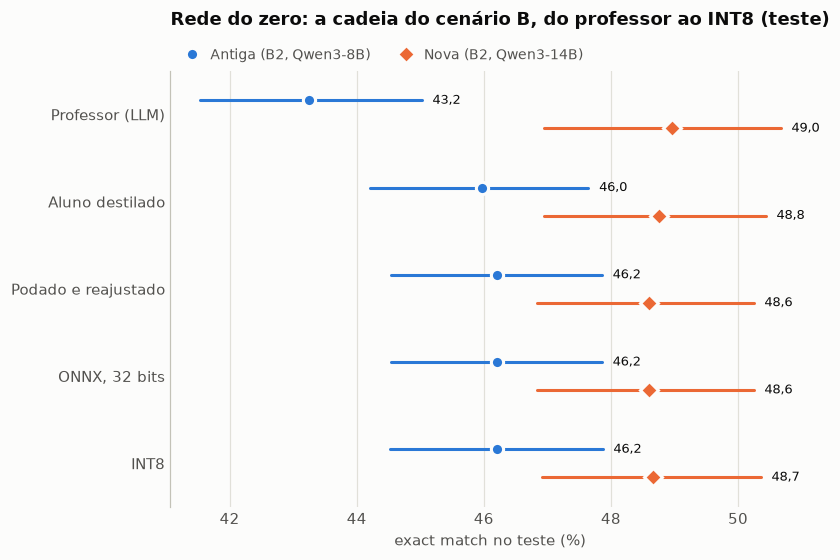

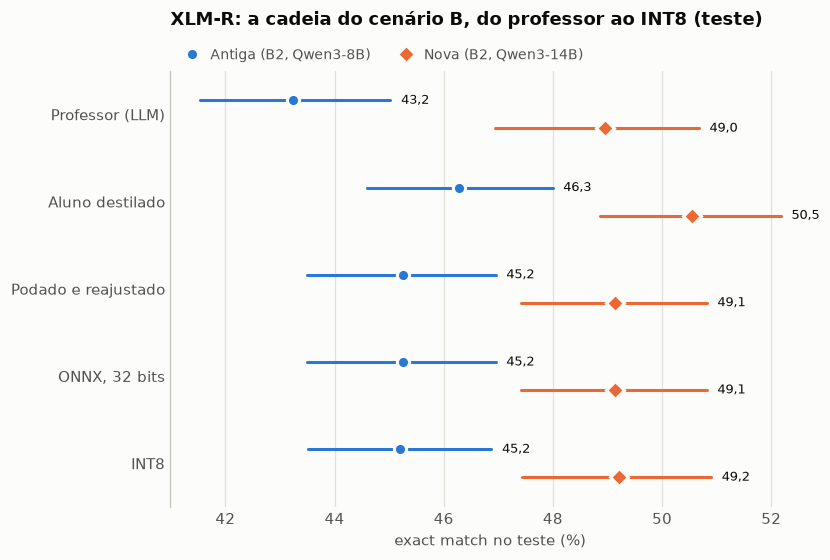

In [8]:
def degraus(cadeia_, particao="test"):
    return CAD[(CAD["cadeia"] == cadeia_) & (CAD["particao"] == particao)].sort_values("ordem")


def rotulo_da_cadeia(cadeia_):
    if "@" not in cadeia_:
        return f"Antiga (B2, {ANTIGO.split(' em ')[0]})"
    return f"Nova ({cadeia_.split('/')[1].split('@')[0]}, {NOVO})"


def lado_a_lado(caminho, particao="test"):
    """As cadeias do cenário B de um caminho, degrau a degrau: o exact match e a diferença para o degrau anterior."""
    nomes = [f"{caminho}/B"] + [f"{caminho}/{a['sigla']}@{PROFESSOR}" for a in ALUNOS.values() if a["caminho"] == caminho]
    tabela = pd.DataFrame({"Degrau": list(degraus(nomes[0], particao)["degrau"])})
    for nome in nomes:
        d = degraus(nome, particao)
        tabela[f"{rotulo_da_cadeia(nome)}: exact match"] = [f"{pts(l['exact_match'])} ({pts(l['exact_match_ic_min'])} a {pts(l['exact_match_ic_max'])})" for _, l in d.iterrows()]
        tabela[f"{rotulo_da_cadeia(nome)}: − degrau anterior"] = ["" if pd.isna(l["exact_match_diferenca"]) else
                                                                 f"{dif(l['exact_match_diferenca'])} ({dif(l['exact_match_dif_ic_min'])} a {dif(l['exact_match_dif_ic_max'])})" for _, l in d.iterrows()]
    return tabela


def custo_lado_a_lado(caminho):
    nomes = [f"{caminho}/B"] + [f"{caminho}/{a['sigla']}@{PROFESSOR}" for a in ALUNOS.values() if a["caminho"] == caminho]
    tabela = pd.DataFrame({"Degrau": list(degraus(nomes[0])["degrau"])})
    for nome in nomes:
        chaves = list(degraus(nome)["chave"])
        tabela[f"{rotulo_da_cadeia(nome)}: MB"] = [megas(c) for c in chaves]
        tabela[f"{rotulo_da_cadeia(nome)}: ms"] = [ms(c) if T.loc[c, "ponto"] != "professor" else "outra condição" for c in chaves]
    return tabela


cadeias_lado_a_lado = {c: lado_a_lado(c) for c in CAMINHOS}
cadeias_em_dev = {c: lado_a_lado(c, "dev") for c in CAMINHOS}
custos_lado_a_lado = {c: custo_lado_a_lado(c) for c in CAMINHOS}
for c in CAMINHOS:
    display(Markdown(f"**{CAMINHOS[c]}, no teste**"))
    display(cadeias_lado_a_lado[c])
    display(Markdown(f"**{CAMINHOS[c]}, tamanho e latência de cada degrau** (o professor roda em placa de vídeo, em outra condição; o tamanho dele é o dos pesos baixados, quando medido)"))
    display(custos_lado_a_lado[c])
    antiga, nova = degraus(f"{c}/B"), degraus(f"{c}/B2@{PROFESSOR}")
    series = {rotulo_da_cadeia(f"{c}/B"): {l["degrau"]: (100 * l["exact_match"], 100 * l["exact_match_ic_min"], 100 * l["exact_match_ic_max"]) for _, l in antiga.iterrows()},
              rotulo_da_cadeia(f"{c}/B2@{PROFESSOR}"): {l["degrau"]: (100 * l["exact_match"], 100 * l["exact_match_ic_min"], 100 * l["exact_match_ic_max"]) for _, l in nova.iterrows()}}
    fig, ax = visual.pontos_com_intervalo(series, f"{CAMINHOS[c]}: a cadeia do cenário B, do professor ao INT8 (teste)", "exact match no teste (%)")
    visual.salvar(fig, PASTA, f"cadeia_{c}")

In [9]:
def frase_da_cadeia(cadeia_):
    """Onde a cadeia perde: os degraus cuja diferença para o anterior é distinguível, e a ponta contra o professor."""
    d = degraus(cadeia_).iloc[1:]
    perde = [f"{l['degrau'].lower()} ({dif(l['exact_match_diferenca'])}, de {dif(l['exact_match_dif_ic_min'])} a {dif(l['exact_match_dif_ic_max'])})" for _, l in d.iterrows() if l["exact_match_dif_ic_max"] < 0]
    ganha = [f"{l['degrau'].lower()} ({dif(l['exact_match_diferenca'])}, de {dif(l['exact_match_dif_ic_min'])} a {dif(l['exact_match_dif_ic_max'])})" for _, l in d.iterrows() if l["exact_match_dif_ic_min"] > 0]
    chaves = list(degraus(cadeia_)["chave"])
    ponta = par(chaves[-1], chaves[0])
    return (f"{rotulo_da_cadeia(cadeia_)}: do professor ({pts(degraus(cadeia_).iloc[0]['exact_match'])}) ao INT8 ({pts(degraus(cadeia_).iloc[-1]['exact_match'])}), {ci(ponta)} ({leitura(ponta)}). "
            + (f"Degraus que perdem de forma distinguível: {lista(perde)}. " if perde else "Nenhum degrau perde de forma distinguível. ")
            + (f"Degraus que ganham: {lista(ganha)}." if ganha else ""))


frases_das_cadeias = {c: [frase_da_cadeia(nome) for nome in [f"{c}/B"] + [f"{c}/{a['sigla']}@{PROFESSOR}" for a in ALUNOS.values() if a["caminho"] == c]] for c in CAMINHOS}
display(Markdown("\n".join(f"**{CAMINHOS[c]}.**\n\n" + "\n".join(f"- {f}" for f in frases_das_cadeias[c]) + "\n" for c in CAMINHOS)))

**Rede do zero.**

- Antiga (B2, Qwen3-8B): do professor (43,2) ao INT8 (46,2), +3,0 (+1,5 a +4,4) (acima). Nenhum degrau perde de forma distinguível. Degraus que ganham: aluno destilado (+2,7, de +1,2 a +4,3).
- Nova (B2, Qwen3-14B): do professor (49,0) ao INT8 (48,7), −0,3 (−1,7 a +1,1) (sem diferença distinguível). Nenhum degrau perde de forma distinguível. 

**XLM-R.**

- Antiga (B2, Qwen3-8B): do professor (43,2) ao INT8 (45,2), +2,0 (+0,6 a +3,3) (acima). Degraus que perdem de forma distinguível: podado e reajustado (−1,0, de −1,4 a −0,6). Degraus que ganham: aluno destilado (+3,0, de +1,7 a +4,3).
- Nova (B1, Qwen3-14B): do professor (49,0) ao INT8 (49,3), +0,3 (−1,0 a +1,5) (sem diferença distinguível). Degraus que perdem de forma distinguível: podado e reajustado (−0,8, de −1,4 a −0,1). 
- Nova (B2, Qwen3-14B): do professor (49,0) ao INT8 (49,2), +0,3 (−1,1 a +1,6) (sem diferença distinguível). Degraus que perdem de forma distinguível: podado e reajustado (−1,4, de −2,0 a −0,8). Degraus que ganham: aluno destilado (+1,6, de +0,3 a +2,9).


## 7. A distância entre os cenários A e B, antes e depois da troca de professor

O cenário A é o do professor fechado (aluno A); o B, o do professor aberto. A diferença é aluno A − aluno B, no mesmo caminho e no mesmo ponto da cadeia: como os alunos saíram da destilação e na forma final de 8 bits. "Antes" é com o aluno B2 do Qwen3-8B; "depois", com os alunos do Qwen3-14B. As **leituras principais** da etapa, fixadas nas regras, são as do INT8 com o representante do cenário B, no teste.

**Leituras principais (INT8, teste, exact match).** Rede do zero: o aluno A fica +2,6 (+1,3 a +3,8) do aluno B2 do Qwen3-14B; com o B2 do Qwen3-8B a distância era de +5,0 (+3,8 a +6,3). XLM-R: o aluno A fica +4,2 (+3,0 a +5,4) do aluno B1 do Qwen3-14B; com o B2 do Qwen3-8B a distância era de +8,3 (+7,0 a +9,6). Nos dois caminhos o intervalo continua acima de zero: o cenário B continua distinguivelmente abaixo do A.

,Caminho,Ponto,Aluno B,Aluno A (teste),Aluno B (teste),"A − B, exact match (teste)","A − B, exact match (dev)"
0,Rede do zero,aluno destilado,B2 do Qwen3-8B (antes),"51,2","46,0","+5,2 (+3,9 a +6,6)","+5,1 (+3,7 a +6,7)"
1,Rede do zero,aluno destilado,B2 do Qwen3-14B (representa),"51,2","48,8","+2,5 (+1,2 a +3,7)","+3,6 (+2,2 a +5,2)"
2,Rede do zero,INT8,B2 do Qwen3-8B (antes),"51,2","46,2","+5,0 (+3,8 a +6,3)","+4,7 (+3,1 a +6,2)"
3,Rede do zero,INT8,B2 do Qwen3-14B (representa),"51,2","48,7","+2,6 (+1,3 a +3,8)","+3,8 (+2,3 a +5,2)"
4,XLM-R,aluno destilado,B2 do Qwen3-8B (antes),"53,8","46,3","+7,5 (+6,2 a +8,8)","+7,1 (+5,6 a +8,6)"
5,XLM-R,aluno destilado,B1 do Qwen3-14B (representa),"53,8","49,7","+4,1 (+2,9 a +5,3)","+4,0 (+2,5 a +5,4)"
6,XLM-R,aluno destilado,B2 do Qwen3-14B,"53,8","50,5","+3,3 (+2,1 a +4,5)","+3,5 (+2,1 a +5,0)"
7,XLM-R,INT8,B2 do Qwen3-8B (antes),"53,5","45,2","+8,3 (+7,0 a +9,6)","+7,3 (+5,7 a +8,8)"
8,XLM-R,INT8,B1 do Qwen3-14B (representa),"53,5","49,3","+4,2 (+3,0 a +5,4)","+4,7 (+3,3 a +6,2)"
9,XLM-R,INT8,B2 do Qwen3-14B,"53,5","49,2","+4,3 (+3,1 a +5,5)","+4,3 (+2,8 a +5,7)"


,Caminho,Comparação (INT8),Intenção (teste),Intenção (dev),Entidades (F1) (teste),Entidades (F1) (dev),Exact match (teste),Exact match (dev)
0,Rede do zero,aluno A − aluno B2 do Qwen3-14B,"+1,0 (+0,1 a +1,9)","+1,9 (+0,9 a +2,9)","+4,6 (+3,6 a +5,7)","+4,9 (+3,6 a +6,3)","+2,6 (+1,3 a +3,8)","+3,8 (+2,3 a +5,2)"
1,XLM-R,aluno A − aluno B1 do Qwen3-14B,"+3,4 (+2,4 a +4,3)","+2,8 (+1,8 a +3,7)","+4,2 (+3,2 a +5,3)","+5,0 (+3,6 a +6,4)","+4,2 (+3,0 a +5,4)","+4,7 (+3,3 a +6,2)"


PosixPath('/home/danie/project/residencia/entregas/11c_cenario_b_ate_o_fim/figuras/a_menos_b.png')

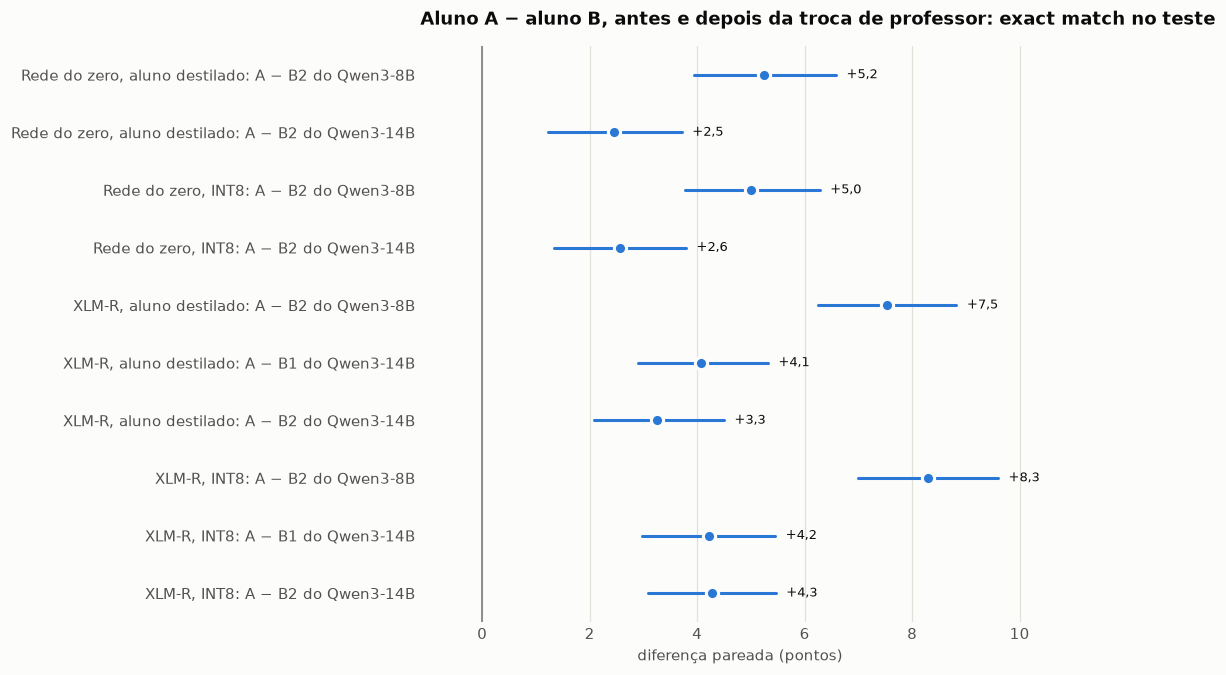

In [10]:
PONTOS = (("", "aluno destilado"), ("/int8", "INT8"))


def a_menos_b(caminho, sufixo, chave_b, particao="test", metrica="exact_match"):
    return par(A[caminho] + sufixo, chave_b + sufixo, particao, metrica)


linhas, dados_da_figura = [], {}
for c in CAMINHOS:
    outros = [(f"{ALUNOS[nome]['sigla']} do {NOVO}" + (" (representa)" if a["representa"] else ""), a["chave"]) for nome, a in ALUNOS.items() if a["caminho"] == c]
    for sufixo, ponto in PONTOS:
        for quem, chave in [(f"B2 do {ANTIGO.split(' em ')[0]} (antes)", B2_ANTIGO[c]), *outros]:
            teste, em_dev = a_menos_b(c, sufixo, chave), a_menos_b(c, sufixo, chave, "dev")
            linhas.append({"Caminho": CAMINHOS[c], "Ponto": ponto, "Aluno B": quem, "Aluno A (teste)": pts(teste["valor_b"]), "Aluno B (teste)": pts(teste["valor_a"]),
                           "A − B, exact match (teste)": ci(teste), "A − B, exact match (dev)": ci(em_dev)})
            dados_da_figura[f"{CAMINHOS[c]}, {ponto}: A − {quem.replace(' (antes)', '').replace(' (representa)', '')}"] = trio(teste)
distancia = pd.DataFrame(linhas)
principais_do_comparativo = {c: {m: {p: par(A[c] + "/int8", REPRESENTA[c] + "/int8", p, m) for p in ("dev", "test")} for m in TRES} for c in CAMINHOS}
antes_do_comparativo = {c: {m: {p: par(A[c] + "/int8", B2_ANTIGO[c] + "/int8", p, m) for p in ("dev", "test")} for m in TRES} for c in CAMINHOS}
tabela_das_principais = pd.DataFrame([{"Caminho": CAMINHOS[c], "Comparação (INT8)": f"aluno A − aluno {SIGLA_DO_REPRESENTANTE[c]} do {NOVO}",
                                       **{f"{CURTA[m]} ({NOME_DA_PARTICAO[p]})": ci(principais_do_comparativo[c][m][p]) for m in TRES for p in ("test", "dev")}} for c in CAMINHOS])
ainda_abaixo = all(principais_do_comparativo[c]["exact_match"]["test"]["ic_min"] > 0 for c in CAMINHOS)
texto_da_distancia = (
    "**Leituras principais (INT8, teste, exact match).** " + " ".join(
        f"{CAMINHOS[c]}: o aluno A fica {ci(principais_do_comparativo[c]['exact_match']['test'])} do aluno {SIGLA_DO_REPRESENTANTE[c]} do {NOVO}; com o B2 do {ANTIGO.split(' em ')[0]} a distância era de "
        f"{ci(antes_do_comparativo[c]['exact_match']['test'])}." for c in CAMINHOS)
    + (" Nos dois caminhos o intervalo continua acima de zero: o cenário B continua distinguivelmente abaixo do A." if ainda_abaixo else " A distância já não é distinguível em todo caminho.")
)
display(Markdown(texto_da_distancia))
display(distancia)
display(tabela_das_principais)
fig, ax = visual.diferencas_com_intervalo(dados_da_figura, "Aluno A − aluno B, antes e depois da troca de professor: exact match no teste", "diferença pareada (pontos)")
visual.salvar(fig, PASTA, "a_menos_b")

## 8. A troca de professor, ponto a ponto

A mesma comparação vista do outro lado: o aluno do Qwen3-14B menos o mesmo aluno do Qwen3-8B, no mesmo caminho e no mesmo ponto. Cada B2 está na temperatura que a regra escolheu em `dev` com o seu professor (no XLM-R, T = 2 com o antigo e T = 8 com o novo). O ganho que a Etapa 11b mediu no aluno destilado chega ao modelo comprimido?

Rede do zero: o ganho do B2 com o professor novo é de +2,8 (+1,6 a +3,9) no aluno destilado e de +2,5 (+1,4 a +3,5) no INT8 (acima). XLM-R: o ganho do B2 com o professor novo é de +4,3 (+3,1 a +5,5) no aluno destilado e de +4,0 (+2,8 a +5,2) no INT8 (acima).

,Caminho,Aluno,Ponto,Com o antigo (teste),Com o novo (teste),"Novo − antigo, exact match (teste)","Novo − antigo, exact match (dev)",Leitura (teste)
0,Rede do zero,B2,aluno destilado,"46,0","48,8","+2,8 (+1,6 a +3,9)","+1,6 (+0,2 a +2,8)",acima
1,Rede do zero,B2,podado e reajustado,"46,2","48,6","+2,4 (+1,4 a +3,4)","+1,1 (−0,2 a +2,4)",acima
2,Rede do zero,B2,INT8,"46,2","48,7","+2,5 (+1,4 a +3,5)","+0,9 (−0,4 a +2,2)",acima
3,XLM-R,B2,aluno destilado,"46,3","50,5","+4,3 (+3,1 a +5,5)","+3,5 (+2,2 a +5,0)",acima
4,XLM-R,B2,podado e reajustado,"45,2","49,1","+3,9 (+2,8 a +5,0)","+3,0 (+1,7 a +4,4)",acima
5,XLM-R,B2,INT8,"45,2","49,2","+4,0 (+2,8 a +5,2)","+3,0 (+1,6 a +4,4)",acima


PosixPath('/home/danie/project/residencia/entregas/11c_cenario_b_ate_o_fim/figuras/troca_de_professor.png')

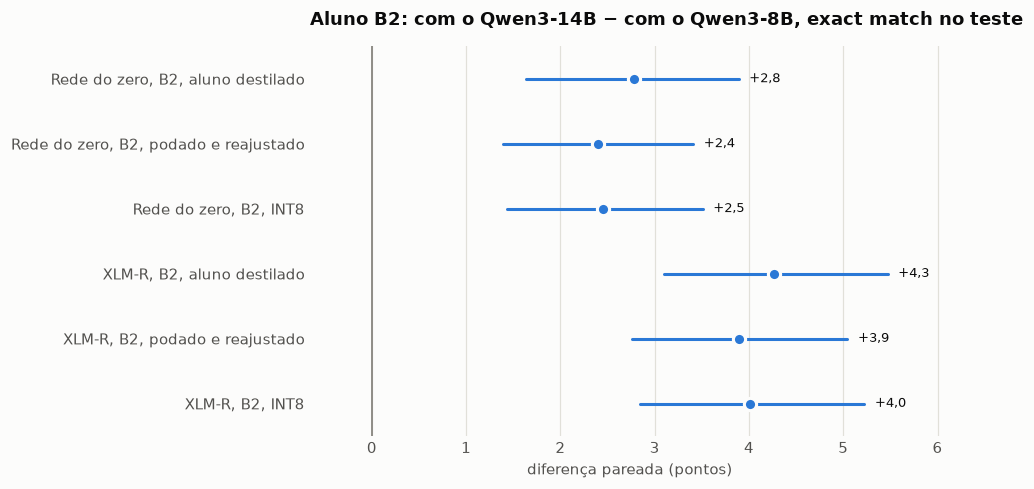

In [11]:
linhas, dados_da_figura = [], {}
for c in CAMINHOS:
    for sufixo, ponto in (("", "aluno destilado"), ("/podado", "podado e reajustado"), ("/int8", "INT8")):
        teste, em_dev = par(B2_NOVO[c] + sufixo, B2_ANTIGO[c] + sufixo), par(B2_NOVO[c] + sufixo, B2_ANTIGO[c] + sufixo, "dev")
        linhas.append({"Caminho": CAMINHOS[c], "Aluno": "B2", "Ponto": ponto, "Com o antigo (teste)": pts(teste["valor_a"]), "Com o novo (teste)": pts(teste["valor_b"]),
                       "Novo − antigo, exact match (teste)": ci(teste), "Novo − antigo, exact match (dev)": ci(em_dev), "Leitura (teste)": leitura(teste)})
        dados_da_figura[f"{CAMINHOS[c]}, B2, {ponto}"] = trio(teste)
troca = pd.DataFrame(linhas)
ganho = {c: {s: par(B2_NOVO[c] + s, B2_ANTIGO[c] + s) for s in ("", "/podado", "/int8")} for c in CAMINHOS}
texto_da_troca = " ".join(
    f"{CAMINHOS[c]}: o ganho do B2 com o professor novo é de {ci(ganho[c][''])} no aluno destilado e de {ci(ganho[c]['/int8'])} no INT8 ({leitura(ganho[c]['/int8'])})." for c in CAMINHOS)
display(Markdown(texto_da_troca))
display(troca)
fig, ax = visual.diferencas_com_intervalo(dados_da_figura, f"Aluno B2: com o {NOVO} − com o {ANTIGO.split(' em ')[0]}, exact match no teste", "diferença pareada (pontos)")
visual.salvar(fig, PASTA, "troca_de_professor")

## 9. Os professores lado a lado

Os quatro professores abertos do registro (o Qwen3-8B em 4 bits da Etapa 5b e os três da Etapa 11a) e o professor fechado, com o mesmo prompt e os mesmos 299 rótulos humanos. O Qwen3-32B entrou como **extensão** da escada da Etapa 11a, decidida depois de ver o resultado dos três primeiros degraus; ele não tomou o lugar do 14B e não tem alunos.

Do Qwen3-8B em 4 bits para o Qwen3-14B, o exact match sobe +5,7 (+4,2 a +7,3) no teste e +6,0 (+4,2 a +7,7) em `dev`. Do Qwen3-14B para o Qwen3-32B, a diferença é de −0,0 (−1,6 a +1,7) em `dev` e de +1,0 (−0,3 a +2,5) no teste (lido de `entregas/11a_professor_aberto_maior/comparacoes.csv`; a comparação é da Etapa 11a e não faz parte da lista desta etapa): nas duas partições o intervalo contém zero. Com estes dados não dá para afirmar que o professor aberto melhorou do 14B para o 32B; também não dá para afirmar que não melhorou: no teste o intervalo vai até +2,5 pontos. O professor fechado continua acima de todos: o Qwen3-32B fica −4,0 (−5,6 a −2,5) dele no teste, e o Qwen3-14B, −5,1 (−6,7 a −3,5).

,Professor,Intenção (dev),Entidades (F1) (dev),Exact match (dev),Intenção (teste),Entidades (F1) (teste),Exact match (teste),Menos o fechado: exact match (teste)
0,Claude Haiku 5.5 (professor fechado),"84,1 (82,6 a 85,6)","68,5 (66,5 a 70,5)","54,7 (52,6 a 57,0)","83,5 (82,1 a 84,7)","66,1 (64,5 a 67,7)","54,0 (52,3 a 55,7)",
1,Qwen3-8B em 4 bits (professor aberto),"77,4 (75,7 a 79,2)","58,0 (55,9 a 60,1)","43,2 (41,0 a 45,3)","77,6 (76,1 a 79,1)","55,7 (53,9 a 57,4)","43,2 (41,5 a 45,0)","−10,8 (−12,4 a −9,1)"
2,"Qwen3-8B sem os 4 bits (professor aberto sem compressão, Etapa 11a)","77,9 (76,2 a 79,7)","57,8 (55,7 a 60,0)","43,2 (41,0 a 45,5)","77,9 (76,5 a 79,4)","56,5 (54,8 a 58,2)","43,4 (41,6 a 45,2)","−10,6 (−12,2 a −9,0)"
3,"Qwen3-14B sem os 4 bits (professor aberto maior, Etapa 11a)","80,6 (79,0 a 82,3)","62,4 (60,4 a 64,6)","49,1 (47,0 a 51,5)","80,0 (78,6 a 81,4)","61,4 (59,6 a 63,1)","49,0 (46,9 a 50,7)","−5,1 (−6,7 a −3,5)"
4,"Qwen3-32B sem os 4 bits (professor aberto da extensão, Etapa 11a)","81,0 (79,4 a 82,7)","63,3 (61,3 a 65,4)","49,1 (47,0 a 51,4)","80,9 (79,4 a 82,3)","62,5 (60,8 a 64,3)","50,0 (48,2 a 51,8)","−4,0 (−5,6 a −2,5)"


PosixPath('/home/danie/project/residencia/entregas/11c_cenario_b_ate_o_fim/figuras/professores.png')

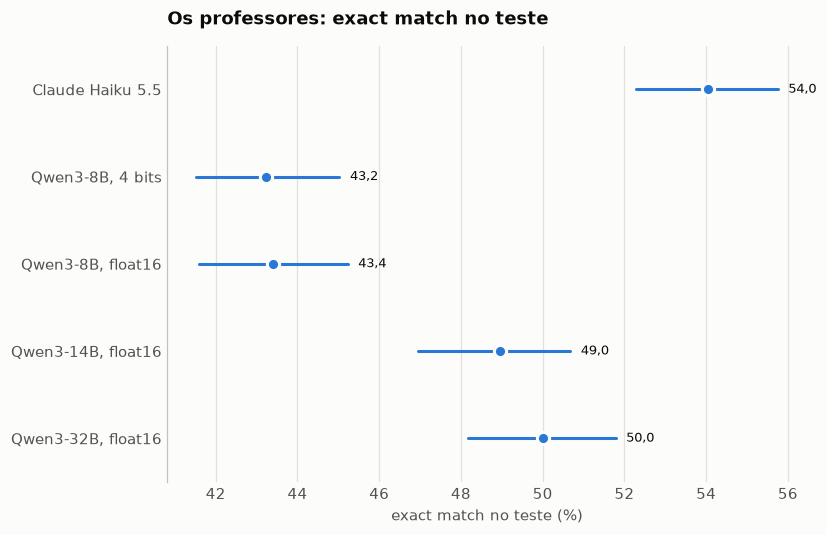

In [12]:
PROFESSORES = ["claude", "qwen"] + [c for c in T.index if T.loc[c, "ponto"] == "professor" and c not in ("claude", "qwen")]
EXTENSAO = etapa11a.EXTENSAO
tabela_dos_professores = pd.DataFrame([{
    "Professor": T.loc[p, "sistema"], **{f"{CURTA[m]} ({NOME_DA_PARTICAO[particao]})": qci(p, m, particao) for particao in ("dev", "test") for m in TRES},
    "Menos o fechado: exact match (teste)": "" if p == "claude" else ci(par(p, "claude")),
} for p in PROFESSORES])
da_11a = pd.read_csv(ENTREGAS / etapa11a.ETAPA / "comparacoes.csv")
do_32b = lambda particao, metrica="exact_match": da_11a[(da_11a["b"] == EXTENSAO) & (da_11a["a"] == PROFESSOR) & (da_11a["particao"] == particao) & (da_11a["metrica"] == metrica)].iloc[0]
do_14b = {p: par(PROFESSOR, "qwen", p) for p in ("dev", "test")}
escolha_da_extensao = json.loads((ENTREGAS / etapa11a.ETAPA / "escolha_extensao_32b.json").read_text(encoding="utf-8"))
texto_dos_professores = (
    f"Do {ANTIGO} para o {NOVO}, o exact match sobe {ci(do_14b['test'])} no teste e {ci(do_14b['dev'])} em `dev`. Do {NOVO} para o Qwen3-32B, a diferença é de {ci(do_32b('dev'))} em `dev` "
    f"e de {ci(do_32b('test'))} no teste (lido de `entregas/{etapa11a.ETAPA}/comparacoes.csv`; a comparação é da Etapa 11a e não faz parte da lista desta etapa): "
    f"{'nas duas partições o intervalo contém zero' if do_32b('dev')['ic_min'] <= 0 <= do_32b('dev')['ic_max'] and do_32b('test')['ic_min'] <= 0 <= do_32b('test')['ic_max'] else 'os intervalos não contêm zero nas duas partições'}. "
    f"Com estes dados não dá para afirmar que o professor aberto melhorou do 14B para o 32B; também não dá para afirmar que não melhorou: no teste o intervalo vai até {dif(do_32b('test')['ic_max'])} pontos. "
    f"O professor fechado continua acima de todos: o Qwen3-32B fica {ci(par(EXTENSAO, 'claude'))} dele no teste, e o {NOVO}, {ci(par(PROFESSOR, 'claude'))}."
)
display(Markdown(texto_dos_professores))
display(tabela_dos_professores)
serie = {(ANTIGO.replace(" em 4 bits", ", 4 bits") if p == "qwen" else T.loc[p, "curto"]): tuple(100 * v for v in q(p)) for p in PROFESSORES}
fig, ax = visual.pontos_com_intervalo({"exact match no teste": serie}, "Os professores: exact match no teste", "exact match no teste (%)")
visual.salvar(fig, PASTA, "professores")

## 10. A tabela final e a fronteira

A tabela final tem uma linha por sistema do registro. A fronteira é a da Etapa 10d, com a mesma definição: entre os sistemas que usam só os 299 rótulos humanos, um sistema é dominado quando outro tem custo menor ou igual e exact match maior ou igual no teste, e é melhor em pelo menos um dos dois. Os custos são a latência p50 (com a folga da 10d) e o tamanho do arquivo como é entregue.

In [13]:
front = lambda custo: FRONT[FRONT["custo"] == custo].set_index("chave")
na_fronteira = {custo: list(front(custo)[front(custo)["na_fronteira"]].sort_values("valor_do_custo").index) for custo in ("latencia", "tamanho")}
da_10d_f = pd.read_csv(ENTREGAS / etapa10d.ETAPA / "fronteira.csv")
fronteira_da_10d = {custo: set(da_10d_f[(da_10d_f["custo"] == custo) & (da_10d_f["latencia_usada"] == "etapas de origem") & da_10d_f["na_fronteira"]]["chave"]) for custo in ("latencia", "tamanho")}
do_cenario_b = lambda chave: isinstance(T.loc[chave, "professor"], str) and T.loc[chave, "professor"] != "claude"
b_na_fronteira = {custo: [c for c in na_fronteira[custo] if do_cenario_b(c)] for custo in na_fronteira}
mesma_fronteira = {custo: set(na_fronteira[custo]) == fronteira_da_10d[custo] for custo in na_fronteira}
NOME_DO_CUSTO = {"latencia": "latência", "tamanho": "tamanho"}
quadro_da_fronteira = pd.DataFrame([{"Custo": NOME_DO_CUSTO[custo], "Sistema": T.loc[c, "sistema"], "Caminho": CAMINHOS.get(T.loc[c, "caminho"], "os dois"),
                                     "Valor do custo": num(front(custo).loc[c, "valor_do_custo"], 2) + (" ms" if custo == "latencia" else " MB"), "Exact match (teste)": pts(T.loc[c, "exact_match"]),
                                     "Cenário": "B" if do_cenario_b(c) else "A"} for custo in na_fronteira for c in na_fronteira[custo]])
novos_comprimidos = [f"{a['chave']}/{ponto}" for a in ALUNOS.values() for ponto in ("int8", "int8_sem_poda")]
quem_domina = pd.DataFrame([{"Sistema novo": T.loc[c, "sistema"], "Caminho": CAMINHOS[T.loc[c, "caminho"]], "Exact match (teste)": pts(T.loc[c, "exact_match"]), "Latência p50 (ms)": ms(c), "Tamanho (MB)": megas(c),
                             **{f"Dominado por, em {NOME_DO_CUSTO[custo]}": f"{int(front(custo).loc[c, 'quantos_o_dominam'])} sistema(s)" + (
                                 ", entre eles " + lista(T.loc[x, "curto"] + (" (XLM-R)" if T.loc[x, "caminho"] == "xlmr" else "") for x in front(custo).loc[c, "dominado_por"].split("; ")[:2])
                                 if front(custo).loc[c, "quantos_o_dominam"] else "") for custo in na_fronteira}} for c in novos_comprimidos])
so_do_a = all(T.loc[c, "modelo"] == "aluno_a" for chaves in na_fronteira.values() for c in chaves)
dominados_pelo_a = all(any(x and not do_cenario_b(x) for x in front(custo).loc[c, "dominado_por"].split("; ")) for custo in na_fronteira for c in novos_comprimidos)
texto_da_fronteira = (
    ("**Nenhum sistema do cenário B entra na fronteira**, em latência ou em tamanho. " if not any(b_na_fronteira.values()) else
     "**Entram na fronteira, do cenário B:** " + "; ".join(f"em {NOME_DO_CUSTO[custo]}, {lista(T.loc[c, 'sistema'] for c in chaves)}" for custo, chaves in b_na_fronteira.items() if chaves) + ". ")
    + ("A fronteira é a mesma da Etapa 10d nos dois custos: " if all(mesma_fronteira.values()) else "A fronteira mudou em relação à Etapa 10d: ")
    + "; ".join(f"em {NOME_DO_CUSTO[custo]}, {lista(T.loc[c, 'curto'] + (' (XLM-R)' if T.loc[c, 'caminho'] == 'xlmr' else ' (do zero)') for c in na_fronteira[custo])}" for custo in na_fronteira)
    + (". Todos os pontos da fronteira são do aluno A." if so_do_a else ".")
    + (" Cada sistema novo em 8 bits é dominado, nos dois custos, por pelo menos um sistema do cenário A (tabela abaixo)." if dominados_pelo_a
       else " Nem todo sistema novo em 8 bits é dominado por um sistema do cenário A (tabela abaixo).")
)
display(Markdown(texto_da_fronteira))
display(quadro_da_fronteira)
display(quem_domina)

**Nenhum sistema do cenário B entra na fronteira**, em latência ou em tamanho. A fronteira é a mesma da Etapa 10d nos dois custos: em latência, Aluno A, INT8 sem poda (do zero) e Aluno A, INT8 sem poda (XLM-R); em tamanho, Aluno A, pesos soltos, INT8 com zip (do zero), Aluno A, INT8 (do zero), Aluno A, INT8 sem poda (do zero), Aluno A, INT8 (XLM-R) e Aluno A, INT8 sem poda (XLM-R). Todos os pontos da fronteira são do aluno A. Cada sistema novo em 8 bits é dominado, nos dois custos, por pelo menos um sistema do cenário A (tabela abaixo).

,Custo,Sistema,Caminho,Valor do custo,Exact match (teste),Cenário
0,latência,"Aluno A, sem poda, INT8, quantização dinâmica",Rede do zero,"0,26 ms","51,3",A
1,latência,"Aluno A, sem poda, INT8, quantização dinâmica",XLM-R,"8,33 ms","54,5",A
2,tamanho,"Aluno A, magnitude, 95% de uma vez, INT8, quantização dinâmica, arquivo compactado",Rede do zero,"0,92 MB","50,3",A
3,tamanho,"Aluno A, sem 90% das linhas da tabela de features, INT8, quantização dinâmica",Rede do zero,"2,11 MB","51,2",A
4,tamanho,"Aluno A, sem poda, INT8, quantização dinâmica",Rede do zero,"5,26 MB","51,3",A
5,tamanho,"Aluno A, vocabulário do treino, INT8, quantização dinâmica",XLM-R,"90,67 MB","53,5",A
6,tamanho,"Aluno A, sem poda, INT8, quantização dinâmica",XLM-R,"287,28 MB","54,5",A


,Sistema novo,Caminho,Exact match (teste),Latência p50 (ms),Tamanho (MB),"Dominado por, em latência","Dominado por, em tamanho"
0,"Aluno B2 · Qwen3-14B, sem 90% das linhas da tabela de features, INT8, quantização dinâmica",Rede do zero,"48,7","0,25","2,11","4 sistema(s), entre eles Aluno A, INT8 e Aluno A, pesos soltos, INT8 com zip","1 sistema(s), entre eles Aluno A, pesos soltos, INT8 com zip"
1,"Aluno B2 · Qwen3-14B, sem poda, INT8, quantização dinâmica",Rede do zero,"48,9","0,26","5,26","3 sistema(s), entre eles Aluno A, INT8 e Aluno A, pesos soltos, INT8 com zip","3 sistema(s), entre eles Aluno A, INT8 e Aluno A, pesos soltos, INT8 com zip"
2,"Aluno B1 · Qwen3-14B, vocabulário do treino, INT8, quantização dinâmica",XLM-R,"49,3","7,69","90,7","11 sistema(s), entre eles Aluno A e Aluno A, podado","7 sistema(s), entre eles Aluno A e Aluno A, podado"
3,"Aluno B1 · Qwen3-14B, sem poda, INT8, quantização dinâmica",XLM-R,"50,0","7,68","287,3","10 sistema(s), entre eles Aluno A e Aluno A, podado","9 sistema(s), entre eles Aluno A e Aluno A, podado"
4,"Aluno B2 · Qwen3-14B, vocabulário do treino, INT8, quantização dinâmica",XLM-R,"49,2","7,65","90,7","12 sistema(s), entre eles Aluno A e Aluno A, podado","8 sistema(s), entre eles Aluno A e Aluno A, podado"
5,"Aluno B2 · Qwen3-14B, sem poda, INT8, quantização dinâmica",XLM-R,"50,6","7,69","287,3","8 sistema(s), entre eles Aluno A e Aluno A, podado","8 sistema(s), entre eles Aluno A e Aluno A, podado"


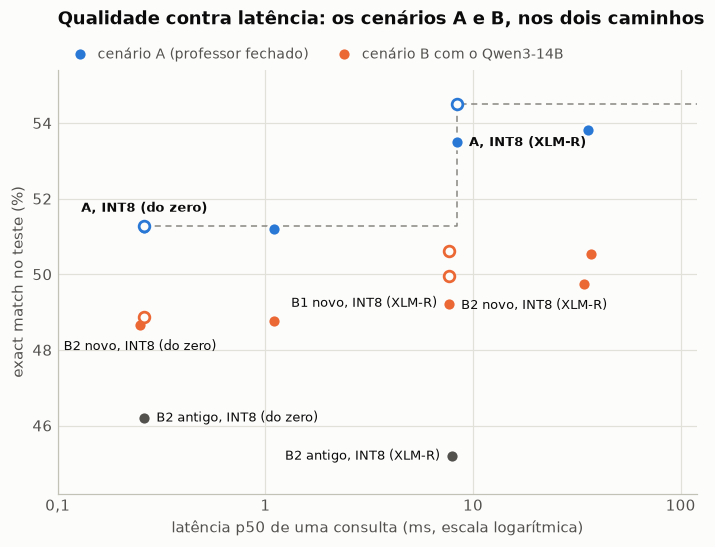

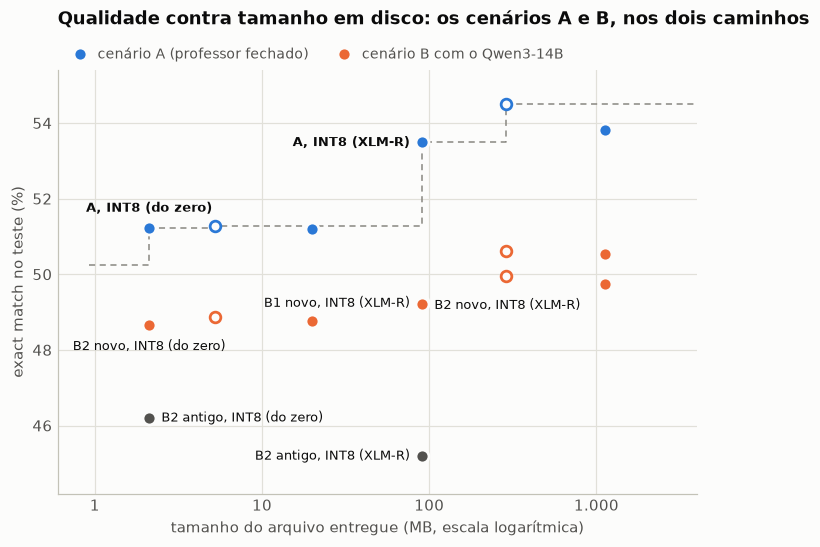

Nas duas figuras: o tracejado é a fronteira; os pontos vazados são os modelos em INT8 sem poda; os pontos sem rótulo são os alunos sem compressão, em PyTorch; em cinza, o B2 do Qwen3-8B em INT8. Em tamanho, o ponto mais à esquerda da fronteira (o aluno A da rede do zero com pesos soltos, compactado) não tem marcador.

In [14]:
import matplotlib.pyplot as plt

em_pontos = lambda chave: 100 * T.loc[chave, "exact_match"]
lat = lambda chave: T.loc[chave, "latencia_p50_ms"]
megas_entregues = etapa10d.megas_entregues(T)          # o arquivo como é entregue: o compactado, quando o sistema vai compactado
tam = lambda chave: megas_entregues.loc[chave]
LADO = {("zero", "A"): "cima", ("xlmr", "A"): "direita", ("zero", "antigo"): "direita", ("xlmr", "antigo"): "esquerda", ("zero", "B2"): "baixo", ("xlmr", "B1"): "esquerda", ("xlmr", "B2"): "direita"}


def figura_da_fronteira(custo, medida, titulo, eixo_x, limites, lado_do_a_no_xlmr="direita"):
    """O cenário A (série 0) e o cenário B com o professor novo (série 1), em INT8 e sem compressão; em cinza, o B2 antigo em INT8."""
    pontos = []
    for c in CAMINHOS:
        onde = "do zero" if c == "zero" else "XLM-R"
        pontos += [{"x": medida(A[c]), "y": em_pontos(A[c]), "rotulo": None, "serie": 0},
                   {"x": medida(A[c] + "/int8"), "y": em_pontos(A[c] + "/int8"), "rotulo": f"A, INT8 ({onde})", "serie": 0, "lado": lado_do_a_no_xlmr if c == "xlmr" else LADO[(c, "A")], "forte": True},
                   {"x": medida(A[c] + "/int8_sem_poda"), "y": em_pontos(A[c] + "/int8_sem_poda"), "rotulo": None, "serie": 0, "vazado": True},
                   {"x": medida(B2_ANTIGO[c] + "/int8"), "y": em_pontos(B2_ANTIGO[c] + "/int8"), "rotulo": f"B2 antigo, INT8 ({onde})", "serie": None, "lado": LADO[(c, "antigo")]}]
        for a in (x for x in ALUNOS.values() if x["caminho"] == c):
            pontos += [{"x": medida(a["chave"]), "y": em_pontos(a["chave"]), "rotulo": None, "serie": 1},
                       {"x": medida(a["chave"] + "/int8"), "y": em_pontos(a["chave"] + "/int8"), "rotulo": f"{a['sigla']} novo, INT8 ({onde})", "serie": 1, "lado": LADO[(c, a["sigla"])]},
                       {"x": medida(a["chave"] + "/int8_sem_poda"), "y": em_pontos(a["chave"] + "/int8_sem_poda"), "rotulo": None, "serie": 1, "vazado": True}]
    escada = [(medida(k), em_pontos(k)) for k in na_fronteira[custo]] + [(limites[1], em_pontos(na_fronteira[custo][-1]))]
    fig, ax = visual.fronteira(pontos, titulo, eixo_x, "exact match no teste (%)", series=["cenário A (professor fechado)", f"cenário B com o {NOVO}"], escada=escada)
    ax.set_xlim(*limites)
    ax.set_ylim(44.2, 55.4)
    return fig, ax


fig, ax = figura_da_fronteira("latencia", lat, "Qualidade contra latência: os cenários A e B, nos dois caminhos", "latência p50 de uma consulta (ms, escala logarítmica)", (0.1, 120))
visual.salvar(fig, PASTA, "fronteira_latencia")
fig, ax = figura_da_fronteira("tamanho", tam, "Qualidade contra tamanho em disco: os cenários A e B, nos dois caminhos", "tamanho do arquivo entregue (MB, escala logarítmica)", (0.6, 4000), lado_do_a_no_xlmr="esquerda")
visual.salvar(fig, PASTA, "fronteira_tamanho")
plt.show()
display(Markdown("Nas duas figuras: o tracejado é a fronteira; os pontos vazados são os modelos em INT8 sem poda; os pontos sem rótulo são os alunos sem compressão, em PyTorch; em cinza, o B2 do "
                 f"{ANTIGO.split(' em ')[0]} em INT8. Em tamanho, o ponto mais à esquerda da fronteira (o aluno A da rede do zero com pesos soltos, compactado) não tem marcador."))

In [15]:
NOME_DO_PONTO = etapa10d.PONTOS
tabela_final = pd.DataFrame([{
    "Sistema": l["sistema"], "Caminho": CAMINHOS.get(l["caminho"], "os dois") if isinstance(l["caminho"], str) else "os dois", "Ponto": NOME_DO_PONTO[l["ponto"]],
    "Intenção": pts(l["intent_acc"]), "Entidades (F1)": pts(l["slot_f1"]), "Exact match (teste)": qci(chave), "Exact match (dev)": pts(l["dev_exact_match"]),
    "Tamanho (MB)": megas(chave), "Latência p50 (ms)": ms(chave) + ("" if pd.isna(l["latencia_p50_ms"]) or l["condicao_da_latencia"] == etapa10d.CPU else f" ({l['condicao_da_latencia']})"),
} for chave, l in T.iterrows()])
novas_linhas = [c for c in T.index if c not in set(pd.read_csv(ENTREGAS / etapa10d.ETAPA / "tabela_final.csv")["chave"])]
print(len(tabela_final), "sistemas;", len(novas_linhas), "novos em relação à Etapa 10d")
tabela_final

63 sistemas; 19 novos em relação à Etapa 10d


,Sistema,Caminho,Ponto,Intenção,Entidades (F1),Exact match (teste),Exact match (dev),Tamanho (MB),Latência p50 (ms)
0,Linha de base com 299 rótulos,os dois,Linha de base,"47,8","35,6","19,4 (18,1 a 20,8)","20,2",não medido,não medida
1,Linha de base com 11.514 rótulos,os dois,Linha de base,"84,6","47,8","45,2 (43,5 a 47,0)","45,1","33,0","0,82"
2,Claude Haiku 5.5 (professor fechado),os dois,Professor (LLM),"83,5","66,1","54,0 (52,3 a 55,7)","54,7",não medido,"854,1 (API pela rede)"
3,Qwen3-8B em 4 bits (professor aberto),os dois,Professor (LLM),"77,6","55,7","43,2 (41,5 a 45,0)","43,2","16397,4","1087,2 (GPU local)"
4,Teto (DIET do zero com os 11.514 rótulos humanos),Rede do zero,Sem compressão,"84,4","73,6","62,5 (60,8 a 64,1)","62,6","19,9","1,10"
...,...,...,...,...,...,...,...,...,...
58,"Aluno B1 · Qwen3-14B, sem poda, INT8, quantização dinâmica",XLM-R,"INT8, sem poda","79,7","61,9","50,0 (48,2 a 51,6)","50,3","287,3","7,68"
59,"Aluno B2 · Qwen3-14B, vocabulário do treino, PyTorch, 32 bits",XLM-R,Podado e reajustado,"80,0","60,7","49,1 (47,4 a 50,8)","49,9","359,0","34,5"
60,"Aluno B2 · Qwen3-14B, vocabulário do treino, ONNX, 32 bits",XLM-R,"ONNX, 32 bits","80,0","60,7","49,1 (47,4 a 50,8)","49,9","358,9","23,7"
61,"Aluno B2 · Qwen3-14B, vocabulário do treino, INT8, quantização dinâmica",XLM-R,INT8,"79,7","60,3","49,2 (47,4 a 50,9)","49,8","90,7","7,65"


## 11. Onde `dev` e teste discordam

A leitura principal é a do teste. Abaixo, as comparações novas (as que a Etapa 10d não tinha) em que a leitura do exact match muda de uma partição para a outra: distinguível numa e não na outra, ou com o sinal trocado.

In [16]:
novas = PP[~PP.set_index(["chave_b", "chave_a"]).index.isin(da_10d)]
com_caminho = lambda chave: T.loc[chave, "curto"] + ({"zero": " (do zero)", "xlmr": " (XLM-R)"}.get(T.loc[chave, "caminho"], "") if isinstance(T.loc[chave, "caminho"], str) else "")
discordam = []
for (b, a), grupo in novas[novas["metrica"] == "exact_match"].groupby(["chave_b", "chave_a"], sort=False):
    por_particao = grupo.set_index("particao")
    if leitura(por_particao.loc["dev"]) != leitura(por_particao.loc["test"]):
        discordam.append({"Comparação (B − A)": f"{com_caminho(b)} − {com_caminho(a)}", "Famílias": por_particao.loc["test", "familias"], "Em dev": ci(por_particao.loc["dev"]),
                          "Leitura em dev": leitura(por_particao.loc["dev"]), "No teste": ci(por_particao.loc["test"]), "Leitura no teste": leitura(por_particao.loc["test"])})
discordam = pd.DataFrame(discordam)
quantas_novas = novas.groupby(["chave_b", "chave_a"]).ngroups
fora_do_zero = {p: int(((novas["particao"] == p) & (novas["metrica"].isin(TRES)) & novas["distinguivel"]).sum()) for p in ("dev", "test")}
esperadas = 0.05 * quantas_novas * len(TRES)
principais_discordam = [c for c in CAMINHOS for m in TRES if leitura(principais_do_comparativo[c][m]["dev"]) != leitura(principais_do_comparativo[c][m]["test"])]
texto_das_discordancias = (
    f"Das {quantas_novas} comparações novas, {len(discordam)} têm leitura diferente em `dev` e no teste em exact match. "
    f"As leituras principais (aluno A − representante do cenário B, em INT8) {'têm a mesma leitura nas duas partições, nas três métricas' if not principais_discordam else 'mudam de leitura em: ' + lista(sorted(set(CAMINHOS[c] for c in principais_discordam)))}. "
    f"Sem correção para comparações múltiplas: nas {quantas_novas} comparações novas e nas três métricas, {fora_do_zero['test']} intervalos ficam fora do zero no teste e {fora_do_zero['dev']} em `dev`; "
    f"só por acaso seriam esperados cerca de {num(esperadas, 0)}."
)
display(Markdown(texto_das_discordancias))
discordam

Das 43 comparações novas, 6 têm leitura diferente em `dev` e no teste em exact match. As leituras principais (aluno A − representante do cenário B, em INT8) têm a mesma leitura nas duas partições, nas três métricas. Sem correção para comparações múltiplas: nas 43 comparações novas e nas três métricas, 92 intervalos ficam fora do zero no teste e 90 em `dev`; só por acaso seriam esperados cerca de 6.

,Comparação (B − A),Famílias,Em dev,Leitura em dev,No teste,Leitura no teste
0,"Aluno B2 · Qwen3-14B, podado (XLM-R) − Aluno B2 · Qwen3-14B, podado (do zero)",entre_caminhos,"+1,9 (+0,6 a +3,2)",acima,"+0,5 (−0,6 a +1,6)",sem diferença distinguível
1,"Aluno B2 · Qwen3-14B, INT8 (XLM-R) − Aluno B2 · Qwen3-14B, INT8 (do zero)",entre_caminhos,"+1,8 (+0,6 a +3,2)",acima,"+0,5 (−0,5 a +1,6)",sem diferença distinguível
2,"Aluno B1 · Qwen3-14B, INT8 (XLM-R) − Aluno B1 · Qwen3-14B, INT8 sem poda (XLM-R)",poda_nos_8_bits,"−0,9 (−1,7 a −0,1)",abaixo,"−0,7 (−1,4 a +0,0)",sem diferença distinguível
3,"Aluno B2 · Qwen3-14B, podado (do zero) − Aluno B2, podado (do zero)",troca_de_professor,"+1,1 (−0,2 a +2,4)",sem diferença distinguível,"+2,4 (+1,4 a +3,4)",acima
4,"Aluno B2 · Qwen3-14B, INT8 (do zero) − Aluno B2, INT8 (do zero)",troca_de_professor,"+0,9 (−0,4 a +2,2)",sem diferença distinguível,"+2,5 (+1,4 a +3,5)",acima
5,"Aluno B1 · Qwen3-14B, INT8 (XLM-R) − Aluno B1 · Qwen3-14B (XLM-R)",compressao_inteira,"−1,1 (−1,8 a −0,4)",abaixo,"−0,5 (−1,1 a +0,2)",sem diferença distinguível


## 12. Entrega

`etapa11c.entregar` monta a pasta de entrega a partir do cache: as tabelas da compressão, as regras, o comparativo, a decisão (que aqui só relata), os sistemas declarados, as respostas e os modelos, que entram por link físico e não ocupam o disco duas vezes.

In [17]:
destino = etapa11c.entregar()
decisao = json.loads((PASTA / "decisao.json").read_text(encoding="utf-8"))
declarados = json.loads((PASTA / "sistemas.json").read_text(encoding="utf-8"))
por_aluno = "; ".join(a["curto"] + " (" + CAMINHOS[a["caminho"]] + "): " + ("passa em tudo" if a["passa_em_tudo"] else "não passa em tudo") for a in decisao["alunos"].values())
display(Markdown(f"Sistemas declarados: {len(declarados['sistemas'])}; cadeias declaradas: {len(declarados['cadeias'])}. Todas as receitas passam: {'sim' if decisao['todas_as_receitas_passam'] else 'não'} ({por_aluno})."))

Sistemas declarados: 12; cadeias declaradas: 3. Todas as receitas passam: não (Aluno B2 · Qwen3-14B (Rede do zero): passa em tudo; Aluno B1 · Qwen3-14B (XLM-R): não passa em tudo; Aluno B2 · Qwen3-14B (XLM-R): não passa em tudo).

### Os modelos entregues respondem como os que foram medidos?

Cada modelo em 8 bits da entrega (semente 0) é relido do disco e responde de novo ao teste, sem PyTorch: a rede do zero, ao teste inteiro; o XLM-R, aos 300 primeiros pedidos. O modelo podado em PyTorch é relido do mesmo jeito. As respostas são comparadas com as que a etapa mediu.

In [18]:
from especialista.compressao.sistema_encoder_onnx import SistemaEncoderOnnx
from especialista.compressao.sistema_onnx import SistemaOnnx
from especialista.modelos.diet import SistemaDiet
from especialista.modelos.encoder import SistemaEncoder

particoes, _ = massive.carregar_entrega()
teste = particoes["test"]
relidos = {}
for nome, a in ALUNOS.items():
    c = a["caminho"]
    poda, forma, pastas = R[c]["poda"], R[c]["forma"], decisao["alunos"][nome]["pastas_por_semente"]
    pedidos = list(teste["utt"]) if c == "zero" else list(teste["utt"])[:300]
    for rotulo, pasta, arquivo, carregar in (
            ("INT8", pastas["int8"]["0"], f"{nome}__{poda}__{forma}", lambda p: (SistemaOnnx.carregar(p) if c == "zero" else SistemaEncoderOnnx.carregar(p, threads=4))),
            ("INT8 sem poda", pastas["int8_sem_poda"]["0"], f"{nome}__{SEM_PODA}__{forma}", lambda p: (SistemaOnnx.carregar(p) if c == "zero" else SistemaEncoderOnnx.carregar(p, threads=4))),
            ("podado, PyTorch", pastas["podado"]["0"], f"{nome}__{poda}", lambda p: (SistemaDiet if c == "zero" else SistemaEncoder).carregar(p, "cpu"))):
        medidas = carregar_previsoes(PASTA / "previsoes" / f"{arquivo}_semente_0_test.parquet")[1][:len(pedidos)]
        primeiro = next(x for x in sorted((RAIZ / pasta).rglob("*")) if x.is_file())
        relidos[f"{a['curto']} ({CAMINHOS[c]}), {rotulo}"] = {"pedidos": len(pedidos), "iguais": sum(x == y for x, y in zip(carregar(RAIZ / pasta).prever(pedidos), medidas)), "link físico": primeiro.stat().st_nlink > 1}
relidos = pd.DataFrame(relidos).T
relidos

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 4640.92it/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 4562.12it/s]

,pedidos,iguais,link físico
"Aluno B2 · Qwen3-14B (Rede do zero), INT8",2974,2974,True
"Aluno B2 · Qwen3-14B (Rede do zero), INT8 sem poda",2974,2974,True
"Aluno B2 · Qwen3-14B (Rede do zero), podado, PyTorch",2974,2974,True
"Aluno B1 · Qwen3-14B (XLM-R), INT8",300,300,True
"Aluno B1 · Qwen3-14B (XLM-R), INT8 sem poda",300,300,True
"Aluno B1 · Qwen3-14B (XLM-R), podado, PyTorch",300,300,True
"Aluno B2 · Qwen3-14B (XLM-R), INT8",300,300,True
"Aluno B2 · Qwen3-14B (XLM-R), INT8 sem poda",300,300,True
"Aluno B2 · Qwen3-14B (XLM-R), podado, PyTorch",300,300,True


### Critério de pronto

In [19]:
from especialista.experimentos import etapa7, etapa9, etapa10b

metas_da_poda = {(nome, s): json.loads((etapa11c.pasta_da_poda(nome, s) / "meta.json").read_text(encoding="utf-8")) for nome in ALUNOS for s in etapa11c.SEMENTES}
primeira_execucao = min((etapa11c.pasta_da_poda(nome, s) / "meta.json").stat().st_mtime for nome, s in metas_da_poda)
regras_antes = regras["escritas_em"] < cadeia["iniciada_em"] and (BASE / "regras.json").stat().st_mtime < primeira_execucao
regras_do_comparativo_antes = regras_cmp["gravado_em"] < calculo["calculado_em"] and regras_cmp["gravado_em"].replace("T", " ") < contas["contas"]["calculado_em"] and calculo["regras"]["versao"] == regras_cmp["versao"]
receitas_de_origem = all(m["variante"] == R[ALUNOS[nome]["caminho"]]["poda"] and m["receita"]["epocas"] == R[ALUNOS[nome]["caminho"]]["reajuste"]["epocas"]
                         and {k: v for k, v in m["receita"].items() if k != "epocas"} == {k: v for k, v in ALUNOS[nome]["receita"].items() if k != "epocas"} for (nome, s), m in metas_da_poda.items())
do_professor_novo = all(m["origem"]["professor"] == PROFESSOR and PROFESSOR in m["origem"]["treino"] and PROFESSOR in m["origem"]["dev"] and etapa11b.ETAPA in m["de_partida"] for m in metas_da_poda.values())
sem_rotulo_humano = all("humano" not in json.dumps(m["origem"], ensure_ascii=False) for m in metas_da_poda.values())
origens_intactas = (etapa7.ETAPA, etapa10b.ETAPA, etapa7.EPOCAS, etapa10b.EPOCAS) == ("07_poda", "10b_encoder_poda", 30, 10) and not any(PROFESSOR in m for m in list(etapa7.modelos_a_podar()) + list(etapa10b.modelos_a_podar()))

lista_inteira = all(set(zip(PP[PP["particao"] == p]["chave_b"], PP[PP["particao"] == p]["chave_a"])) == {(c["b"], c["a"]) for c in regras_cmp["comparacoes"]} for p in ("dev", "test"))
cadeias_inteiras = list(dict.fromkeys(CAD["cadeia"])) == list(regras_cmp["cadeias"])
da_10d_igual = CF[CF["o_que"].isin(["linha da tabela final da Etapa 10d", "comparação da Etapa 10d"])]
fichas = etapa11c.registro()
declarados_ok = (set(declarados["sistemas"]) <= set(fichas) and all(arquivo.exists() for chave in declarados["sistemas"] for lista_ in fichas[chave]["previsoes"].values() for arquivo in lista_)
                 and all(str(fichas[chave]["declarado_em"]).startswith(f"entregas/{etapa11c.ETAPA}/") for chave in declarados["sistemas"]))
registro_da_10d = list(etapa10d.registro(base=ENTREGAS / etapa10d.ETAPA)) == json.loads((ENTREGAS / etapa10d.ETAPA / "regras_v2.json").read_text(encoding="utf-8"))["sistemas_no_registro"]

no_fecho = json.loads((BASE / "fumaca" / "comparacao_no_fecho.json").read_text(encoding="utf-8"))
outras = {etapa: c for etapa, c in no_fecho["por_etapa"].items() if not etapa.endswith((etapa11c.ETAPA, etapa11a.ETAPA))}
nada_mudou = all(not (c["mudaram"] or c["sumiram"] or c["novos"]) for c in outras.values())
da_11a_mudou = sum(len(c["mudaram"]) + len(c["novos"]) + len(c["sumiram"]) for etapa, c in no_fecho["por_etapa"].items() if etapa.endswith(etapa11a.ETAPA))

artigos = pd.read_csv(ENTREGAS / etapa10d.ETAPA / "artigos.csv")
CITADOS = ("1506.02626", "2111.05754", "2203.15996", "2010.05609", "1712.05877", "1910.06188", "1503.02531", "1911.02549", "2110.12894")
conferidos = artigos[artigos["identificador"].astype(str).isin(CITADOS)]
todas_conferidas = set(conferidos["identificador"].astype(str)) == set(CITADOS) and bool((conferidos["na_fonte"] == "conferida").all())

pronto = pd.Series({
    f"Regras gravadas antes da cadeia ({regras['escritas_em'][11:16]} contra {cadeia['iniciada_em'][11:16]})": bool(regras_antes),
    f"Regras do comparativo (versão {regras_cmp['versao']}) gravadas antes das contas ({regras_cmp['gravado_em'][11:16]} contra {contas['contas']['calculado_em'][11:16]} e {calculo['calculado_em'][11:16]})": bool(regras_do_comparativo_antes),
    f"As {cadeia['prontas']} execuções estão prontas, sem erro, e o código não mudou durante a cadeia": cadeia["prontas"] == regras["execucoes"]["total"] and not cadeia["erros"] and cadeia["codigo_igual_do_inicio_ao_fim"],
    "Toda poda leu o professor novo e partiu da entrega da Etapa 11b; nenhum rótulo humano entrou no reajuste": bool(do_professor_novo and sem_rotulo_humano),
    "A poda, o orçamento do reajuste e a forma de 8 bits são os das decisões de origem; o resto da receita é o do aluno": bool(receitas_de_origem),
    "As etapas de origem ficaram como estavam (a troca vale só dentro do bloco)": bool(origens_intactas),
    f"Cada receita tem a sua conferência calculada em dev e relatada ({len(principais)} leituras; {int(principais['passa'].sum())} passam)": len(principais) == 3 * len(ALUNOS) and principais["passa"].notna().all(),
    f"O ONNX de 32 bits repete o PyTorch em todas as respostas ({n(onnx['iguais_ao_pytorch'])} de {n(onnx['pedidos'])})": onnx["iguais_ao_pytorch"] == onnx["pedidos"],
    f"Latência medida com a máquina quieta (no máximo {num(efi['nucleos_de_outros_processos'].max(), 2)} núcleo de outros processos), sem medida recusada": bool(efi["maquina_quieta"].all() and efi["medidas_recusadas"].sum() == 0),
    f"Toda comparação da lista fechada está calculada em dev e no teste ({len(regras_cmp['comparacoes'])} comparações, {len(regras_cmp['cadeias'])} cadeias)": bool(lista_inteira and cadeias_inteiras),
    f"O que a Etapa 10d entregou sai igual aqui ({int(da_10d_igual['confere'].sum())} de {len(da_10d_igual)} leituras) e o registro dela continua com os 44 sistemas": bool(da_10d_igual["confere"].all() and registro_da_10d),
    f"Os números que outras etapas já tinham gravado, refeitos aqui, fecham ({int((CF['confere'] == True).sum())} de {int((CF['gravado'] == True).sum())} leituras)": bool(not len(nao_fecham)),   # noqa: E712
    f"Os {len(declarados['sistemas'])} sistemas declarados entram no registro, com as respostas na entrega": bool(declarados_ok),
    f"Nada no cache e nas entregas das outras etapas mudou desde antes da cadeia ({len(outras)} pastas; a Etapa 11a, que outro agente fechou no meio, fica de fora)": bool(nada_mudou),
    "Os modelos entregues, relidos do disco, repetem as respostas medidas no teste": bool((relidos["iguais"] == relidos["pedidos"]).all() and relidos["link físico"].all()),
    "Cada referência citada está conferida na fonte (quadro da Etapa 10d)": bool(todas_conferidas),
}).map({True: "sim", False: "NÃO"}).rename("atendido").to_frame()
assert (pronto["atendido"] == "sim").all()
pronto

,atendido
Regras gravadas antes da cadeia (00:40 contra 00:45),sim
Regras do comparativo (versão 4) gravadas antes das contas (02:46 contra 02:53 e 02:56),sim
"As 33 execuções estão prontas, sem erro, e o código não mudou durante a cadeia",sim
Toda poda leu o professor novo e partiu da entrega da Etapa 11b; nenhum rótulo humano entrou no reajuste,sim
"A poda, o orçamento do reajuste e a forma de 8 bits são os das decisões de origem; o resto da receita é o do aluno",sim
As etapas de origem ficaram como estavam (a troca vale só dentro do bloco),sim
Cada receita tem a sua conferência calculada em dev e relatada (9 leituras; 7 passam),sim
O ONNX de 32 bits repete o PyTorch em todas as respostas (90.126 de 90.126),sim
"Latência medida com a máquina quieta (no máximo 0,03 núcleo de outros processos), sem medida recusada",sim
"Toda comparação da lista fechada está calculada em dev e no teste (86 comparações, 9 cadeias)",sim


## 13. Resposta

O resumo abaixo é gerado a partir dos números calculados neste notebook e gravado em `entregas/11c_cenario_b_ate_o_fim/RESUMO.md`.

In [20]:
passa_de = lambda tipo: principais[principais["conferencia"] == tipo]
primeira_metade = (
    f"**Em parte.** {int(principais['passa'].sum())} de {len(principais)} conferências passam: a forma de 8 bits passa com os {len(ALUNOS)} alunos novos e o ONNX de 32 bits repete o PyTorch em todas as respostas; "
    + (f"a poda passa em {int(passa_de('poda')['passa'].sum())} de {len(passa_de('poda'))}. Não passa: {frase_do_que_nao_passa}." if len(nao_passam) else "a poda passa com todos.")
) if len(nao_passam) else f"**Sim.** As {len(principais)} conferências passam com os {len(ALUNOS)} alunos novos."
sobe = all(ganho[c]["/int8"]["ic_min"] > 0 for c in CAMINHOS)
ganho_dev = {c: par(B2_NOVO[c] + "/int8", B2_ANTIGO[c] + "/int8", "dev") for c in CAMINHOS}
nao_acompanha = [c for c in CAMINHOS if leitura(ganho_dev[c]) != leitura(ganho[c]["/int8"])]
ganho_em_dev = ("Em `dev` a leitura é a mesma. " if not nao_acompanha else "Em `dev` o ganho no INT8 não tem a mesma leitura em: " + "; ".join(
    f"{CAMINHOS[c]}, {ci(ganho_dev[c])} ({leitura(ganho_dev[c])})" for c in nao_acompanha) + ". ")
titulo_da_segunda = (("o cenário B sobe no teste" if sobe else "o cenário B não sobe de forma distinguível nos dois caminhos") + (", mas continua abaixo do A" if ainda_abaixo else ", e já não fica distinguivelmente abaixo do A nos dois caminhos")
                     + (" e fora da fronteira" if not any(b_na_fronteira.values()) else " e entra na fronteira"))
segunda_metade = (
    f"**Na tabela final, {titulo_da_segunda}.** Em INT8, no teste, em exact match: " + " ".join(
        f"{CAMINHOS[c]}: aluno {SIGLA_DO_REPRESENTANTE[c]} do {NOVO}, {pts(T.loc[REPRESENTA[c] + '/int8', 'exact_match'])}; aluno A, {pts(T.loc[A[c] + '/int8', 'exact_match'])}; "
        f"A − B = {ci(principais_do_comparativo[c]['exact_match']['test'])} (com o B2 do {ANTIGO.split(' em ')[0]} era {ci(antes_do_comparativo[c]['exact_match']['test'])})." for c in CAMINHOS)
    + " " + texto_da_troca + " " + ganho_em_dev + ("Nenhum sistema do cenário B entra na fronteira, em latência ou em tamanho; a fronteira é a mesma da Etapa 10d." if not any(b_na_fronteira.values()) and all(mesma_fronteira.values())
                                    else texto_da_fronteira.split(". ")[0].replace("**", "") + ".")
)
resposta = primeira_metade + " " + segunda_metade

linhas_de_pronto = "\n".join(f"| {criterio} | {l['atendido']} |" for criterio, l in pronto.iterrows())
fixado = [
    f"**Quem é comprimido:** {regras['regra_dos_alunos']}. Com o {NOVO}: " + "; ".join(f"{a['curto']} ({CAMINHOS[a['caminho']]}; {a['papel']})" for a in ALUNOS.values()) + ".",
    "**Receitas, sem escolha nova:** " + "; ".join(f"{CAMINHOS[c]}: poda \"{R[c]['nome_da_poda'].lower()}\" com reajuste de {R[c]['reajuste']['epocas']} épocas ({R[c]['de']['poda'].split(' ')[0]}) e {R[c]['nome_da_forma']} "
                                                  f"({R[c]['de']['forma'].split(' ')[0]})" for c in CAMINHOS) + f". O reajuste usa o sinal de quem treinou o aluno: os rótulos (e, no B2, os logits) do {NOVO}.",
    f"**Conferências:** {regras['conferencias']['poda']['regra_de_origem']}; {regras['conferencias']['quantizacao']['regra_de_origem']}; {regras['conferencias']['onnx']}. {regras['conferencias']['se_nao_passar'][0].upper() + regras['conferencias']['se_nao_passar'][1:]}.",
    f"**O que mais é exportado:** {regras['o_que_e_exportado_e_quantizado']['variantes']}. {regras['o_que_e_exportado_e_quantizado']['formas'][0].upper() + regras['o_que_e_exportado_e_quantizado']['formas'][1:]}.",
    f"**Custo:** {regras['custo']['tamanho']}; latência: {regras['custo']['latencia']}; {regras['custo']['maquina_quieta'].replace(str(etapa11c.LIMITE_DE_OUTROS), num(etapa11c.LIMITE_DE_OUTROS, 2))}.",
    f"**Comparativo:** {regras_cmp['metodo']['primarias']['o_que_sao']}. Famílias novas: " + "; ".join(f"`{f}`: {regras_cmp['familias'][f]}" for f in regras_cmp["familias_novas"]) + ".",
]
teste_aberto = int(res[res["particao"] == "test"].groupby(["modelo", "variante", "forma"]).ngroups)
alterados_depois = sorted(r for r in set(cadeia["codigo"]) | set(etapa11b.impressao_do_codigo()) if cadeia["codigo"].get(r) != etapa11b.impressao_do_codigo().get(r))
limites = [
    f"**As receitas foram escolhidas com os alunos antigos.** A poda principal de cada caminho saiu da regra aplicada ao aluno A (Etapas 7 e 10b), e o orçamento de reajuste do XLM-R, de um piloto no teto. Aqui elas são só aplicadas. "
    + (f"Onde a conferência não passou ({lista(sorted(set(nome_do_aluno(aluno_de[l['aluno']]) for _, l in nao_passam.iterrows())))}), a etapa não procurou outra poda nem outro orçamento, e não investigou a causa: o modelo podado desses alunos "
       "segue na tabela como a receita o deixou, ao lado do mesmo aluno em INT8 sem poda." if len(nao_passam) else "Todas passaram."),
    "**A conferência usa os rótulos humanos de `dev`**, que o cenário do projeto não tem. Ela diz se a receita vale; não é um passo que um usuário do cenário B poderia repetir.",
    f"**A latência é de uma CPU e de uma semente:** {efi['cpu'].iloc[0]}, {efi['plataforma'].iloc[0]}, 1 thread, semente 0, uma consulta por vez. Em outra máquina os números e até a ordem entre as formas podem mudar. "
    "Os professores rodam em placa de vídeo ou por API: a latência deles não é comparável e não entra na fronteira dos alunos como igual.",
    f"**O teste foi aberto muitas vezes.** Todas as execuções desta etapa respondem ao teste ({teste_aberto} linhas de `resultados.csv`), e o comparativo lê o teste de {len(T)} sistemas em {len(regras_cmp['comparacoes'])} comparações, sem correção "
    f"para comparações múltiplas. Nenhuma escolha desta etapa leu o teste, mas ele já tinha sido aberto em todas as etapas anteriores: os intervalos não descontam isso.",
    f"**A extensão do Qwen3-32B foi decidida depois de ver resultados** (Etapa 11a: {escolha_da_extensao['o_que_ja_se_sabia'].split('. ')[0]}). Ele entra aqui só como linha de professor; não tem alunos. "
    "A leitura \"do 14B para o 32B\" é uma segunda olhada nos mesmos dados, com um intervalo que contém zero: não prova que o professor aberto chegou ao teto.",
    f"**As regras do comparativo têm duas versões nesta etapa.** A 3 é de antes da cadeia; a {regras_cmp['versao']} foi gravada depois que o Qwen3-32B chegou, quando o resultado dele já era conhecido, e antes de qualquer conta. "
    f"A lista só cresceu pelo que a regra gera com um professor a mais ({len(novas_na_v4)} comparações); a comparação 32B − 14B não está na lista e foi lida da Etapa 11a.",
    "**Um professor aberto, de uma família, com uma rotulagem.** O cenário B com o professor novo é o cenário B com o Qwen3-14B em float16, rodado numa placa alugada. O resultado não diz o que outro modelo aberto faria.",
    "**No XLM-R, o B2 antigo e o novo têm temperaturas diferentes** (T = 2 e T = 8), cada uma escolhida em `dev` com o seu professor. \"Novo − antigo\" compara cada aluno na sua temperatura.",
    "**O representante do cenário B muda de aluno entre os caminhos** (B2 na rede do zero, B1 no XLM-R), pela regra de \"quem segue\". A cadeia do B2 do XLM-R existe para comparar com a antiga; a leitura principal desse caminho é a do B1.",
    "**A poda do XLM-R encolhe o arquivo, não a latência:** " + "; ".join(
        f"{a['curto']}: de {megas(a['chave'])} para {megas(a['chave'] + '/podado')} MB, e de {ms(a['chave'])} para {ms(a['chave'] + '/podado')} ms em PyTorch" for a in ALUNOS.values() if a["caminho"] == "xlmr")
    + ". O corte do vocabulário tira linhas da tabela de entrada; a Etapa 10b já tinha medido o mesmo nos alunos antigos.",
    "**A forma estática e as formas de diagnóstico** foram produzidas pelas funções das Etapas 8 e 10c e não foram lidas para decidir nada; as comparações delas estão em `comparacoes.csv` como registro e os modelos ficaram só no cache.",
    f"**Código alterado depois da cadeia:** {lista(alterados_depois) if alterados_depois else 'nenhum arquivo'}. A cadeia rodou com o código cuja cópia está no cache (`{cadeia['copia_do_codigo'].split('data/execucoes/')[-1]}`); "
    "`etapa11c.py` ganhou depois as funções das contas e da entrega, e `etapa11a.py` foi editado por outro agente, no fecho da extensão da Etapa 11a. Os arquivos das funções de poda, de quantização e de latência "
    f"(Etapas 7, 8, 10b e 10c e a pasta `compressao/`) {'têm hoje a mesma impressão digital do começo da cadeia' if not any(('etapa7' in r or 'etapa8' in r or 'etapa10b' in r or 'etapa10c' in r or 'compressao/' in r) for r in alterados_depois) else 'MUDARAM'}.",
    "**A latência dos modelos finais não foi medida de novo na mesma sessão.** A Etapa 10d fez isso para os dois modelos finais; aqui as latências dos alunos novos são as da cadeia desta etapa, e as dos antigos, as das Etapas 8 e 10c.",
]

resumo = f"""# Etapa 11c · O cenário B com o professor novo até o fim do caminho, e o comparativo atualizado: resumo da entrega

**Pergunta.** {etapa11c.PERGUNTA}

**Resposta.** {resposta}

Nenhuma decisão foi tomada nesta etapa. Os modelos finais do projeto continuam os das Etapas 8 e 10c (o aluno A, em cada caminho).

## O que foi fixado antes de rodar

{texto_das_regras}

{chr(10).join(f"- {item}" for item in fixado)}

## A cadeia

{texto_da_cadeia}

## As receitas passam na conferência?

Em `dev`, com os rótulos humanos, média de 3 sementes, diferença pareada com intervalo de 95%.

{texto_das_conferencias}

{em_markdown(quadro_das_conferencias)}

![Conferência da poda](figuras/conferencia_da_poda.png)

![Conferência dos 8 bits](figuras/conferencia_dos_8_bits.png)

Registro (nenhuma regra lê): os dois passos da poda e os 8 bits, em `dev` e no teste. {texto_do_registro}

{em_markdown(registro_da_compressao)}

## Cada linha dos alunos novos

Em % contra os rótulos humanos, média de 3 sementes; tamanho dos arquivos gravados; latência p50 de uma consulta, 1 thread, semente 0. {texto_do_custo}

{em_markdown(tabela_dos_alunos)}

## O comparativo: regras e conferência

{texto_das_regras_do_comparativo}

{texto_da_conferencia}

## As cadeias do cenário B, novas ao lado das antigas

Exact match no teste, em % (intervalo de 95%), e a diferença pareada para o degrau anterior.

{chr(10).join(f"**{CAMINHOS[c]}**{chr(10)}{chr(10)}{em_markdown(cadeias_lado_a_lado[c])}{chr(10)}{chr(10)}{em_markdown(custos_lado_a_lado[c])}{chr(10)}{chr(10)}{chr(10).join(f'- {f}' for f in frases_das_cadeias[c])}{chr(10)}{chr(10)}![Cadeia](figuras/cadeia_{c}.png){chr(10)}" for c in CAMINHOS)}

Em `dev`:

{chr(10).join(f"**{CAMINHOS[c]}**{chr(10)}{chr(10)}{em_markdown(cadeias_em_dev[c])}{chr(10)}" for c in CAMINHOS)}

## A distância entre os cenários A e B, antes e depois da troca de professor

{texto_da_distancia}

{em_markdown(distancia)}

As leituras principais, nas três métricas:

{em_markdown(tabela_das_principais)}

![Aluno A − aluno B](figuras/a_menos_b.png)

## A troca de professor, ponto a ponto

{texto_da_troca}

{em_markdown(troca)}

![Novo − antigo](figuras/troca_de_professor.png)

## Os professores lado a lado

{texto_dos_professores}

{em_markdown(tabela_dos_professores)}

![Professores](figuras/professores.png)

## A tabela final e a fronteira

{texto_da_fronteira}

{em_markdown(quadro_da_fronteira)}

Os sistemas novos em 8 bits e quem os domina:

{em_markdown(quem_domina)}

![Fronteira, latência](figuras/fronteira_latencia.png)

![Fronteira, tamanho](figuras/fronteira_tamanho.png)

A tabela final ({len(tabela_final)} sistemas; {len(novas_linhas)} novos em relação à Etapa 10d). A latência é de CPU local, 1 thread, salvo quando outra condição está escrita:

{em_markdown(tabela_final)}

## Onde dev e teste discordam

{texto_das_discordancias}

{em_markdown(discordam) if len(discordam) else ""}

## Critério de pronto

| Critério | Atendido |
|---|---|
{linhas_de_pronto}

## Limites

{chr(10).join(f"- {l}" for l in limites)}

## Arquivos

| Arquivo | Conteúdo |
|---|---|
| `decisao.json` | Não há decisão nova: para cada aluno, se cada receita passou na conferência, a qualidade, o tamanho e a latência de cada linha, e onde estão os modelos |
| `regras.json` | Tudo o que foi fixado antes da cadeia, com a hora |
| `conferencias.csv` | Cada receita com cada aluno novo: a regra de origem reaplicada em `dev`, e se passa |
| `resultados.csv`, `comparacoes.csv`, `eficiencia.csv`, `reajustes.csv`, `contas.json` | A compressão dos alunos novos, no formato das Etapas 8 e 10c: qualidade por linha, diferenças pareadas, tamanho e latência, e cada reajuste |
| `sistemas.json` | As 12 formas comprimidas e as 3 cadeias novas, declaradas para o comparativo (formato de `etapa10d.fichas_declaradas`) |
| `comparativo/` | As regras (versões 3 e {regras_cmp['versao']}), a tabela final, as cadeias, as comparações, a fronteira, o preço de cada ponto entre os modelos finais e a conferência |
| `previsoes/` | As respostas de cada linha em `dev` e no teste, por semente |
| `modelos/` | Os modelos podados (PyTorch), os de 8 bits (podado e sem poda) e o ONNX de 32 bits (semente 0), por link físico para o cache |
| `historicos/`, `latencia/` | As épocas de cada reajuste e cada medida de latência como foi gravada |
| `cadeia/`, `fumaca/` | O registro e o log da cadeia, o teste de fumaça, as impressões digitais das outras etapas e a prova de que a Etapa 10d reproduz o que entregou |
| `codigo/` | O código da etapa, o da 10d (com a lista de entregas que valem), o construtor deste notebook e os testes |
| `manifesto.json` | Tudo o que a entrega contém, com impressão digital, e de que arquivos ela foi feita |
| `figuras/`, `11c_cenario_b_ate_o_fim.html` | Os gráficos e este notebook executado |
"""
(PASTA / "RESUMO.md").write_text(resumo, encoding="utf-8")
display(Markdown(resumo))

# Etapa 11c · O cenário B com o professor novo até o fim do caminho, e o comparativo atualizado: resumo da entrega

**Pergunta.** As receitas de poda e de quantização já escolhidas valem para os alunos do professor novo, e onde o cenário B fica na tabela final com ele?

**Resposta.** **Em parte.** 7 de 9 conferências passam: a forma de 8 bits passa com os 3 alunos novos e o ONNX de 32 bits repete o PyTorch em todas as respostas; a poda passa em 1 de 3. Não passa: a poda "vocabulário do treino" com o aluno B1 do XLM-R: exact match em dev de 50,4 para 49,4, −1,0 (−1,8 a −0,3); a poda "vocabulário do treino" com o aluno B2 do XLM-R: exact match em dev de 50,8 para 49,9, −0,9 (−1,7 a −0,2). **Na tabela final, o cenário B sobe no teste, mas continua abaixo do A e fora da fronteira.** Em INT8, no teste, em exact match: Rede do zero: aluno B2 do Qwen3-14B, 48,7; aluno A, 51,2; A − B = +2,6 (+1,3 a +3,8) (com o B2 do Qwen3-8B era +5,0 (+3,8 a +6,3)). XLM-R: aluno B1 do Qwen3-14B, 49,3; aluno A, 53,5; A − B = +4,2 (+3,0 a +5,4) (com o B2 do Qwen3-8B era +8,3 (+7,0 a +9,6)). Rede do zero: o ganho do B2 com o professor novo é de +2,8 (+1,6 a +3,9) no aluno destilado e de +2,5 (+1,4 a +3,5) no INT8 (acima). XLM-R: o ganho do B2 com o professor novo é de +4,3 (+3,1 a +5,5) no aluno destilado e de +4,0 (+2,8 a +5,2) no INT8 (acima). Em `dev` o ganho no INT8 não tem a mesma leitura em: Rede do zero, +0,9 (−0,4 a +2,2) (sem diferença distinguível). Nenhum sistema do cenário B entra na fronteira, em latência ou em tamanho; a fronteira é a mesma da Etapa 10d.

Nenhuma decisão foi tomada nesta etapa. Os modelos finais do projeto continuam os das Etapas 8 e 10c (o aluno A, em cada caminho).

## O que foi fixado antes de rodar

As regras foram gravadas em 2026-11-19 00:40; a cadeia começou em 2026-11-19 00:45. São 3 alunos: em cada caminho, o que a regra de "quem segue" aponta como representante do cenário B com o Qwen3-14B (Rede do zero: B2; XLM-R: B1) e, no XLM-R, também o B2, porque a cadeia antiga do cenário B é de B2. A grade tem 33 execuções: 9 podas com reajuste, 18 exportações com quantização (o modelo podado e, como referência, o mesmo aluno sem poda) e 6 medidas de latência.

- **Quem é comprimido:** em cada caminho, o aluno que a regra de 'quem segue' das etapas de origem (`etapa6.quem_segue`) aponta como representante do cenário B com o professor novo, como a Etapa 11b relata em `quem_representa_o_cenario_b` (entregas/11b_alunos_do_professor_maior/decisao.json); e, onde o representante não é o B2, também o B2, porque as cadeias antigas do cenário B são de B2 nos dois caminhos. Com o Qwen3-14B: Aluno B2 · Qwen3-14B (Rede do zero; representa o cenário B neste caminho); Aluno B1 · Qwen3-14B (XLM-R; representa o cenário B neste caminho); Aluno B2 · Qwen3-14B (XLM-R; entra para a cadeia ficar comparável com a antiga, que é de B2).
- **Receitas, sem escolha nova:** Rede do zero: poda "sem 90% das linhas da tabela de features" com reajuste de 30 épocas (entregas/07_poda/decisao.json) e INT8, quantização dinâmica (entregas/08_quantizacao/decisao.json); XLM-R: poda "vocabulário do treino" com reajuste de 10 épocas (entregas/10b_encoder_poda/decisao.json) e INT8, quantização dinâmica (entregas/10c_encoder_quantizacao/decisao.json). O reajuste usa o sinal de quem treinou o aluno: os rótulos (e, no B2, os logits) do Qwen3-14B.
- **Conferências:** a das Etapas 7 e 10b (`etapa7.quem_segue`, passo 1): passa a poda cujo exact match em dev, depois do reajuste, não é distinguivelmente menor que o do modelo sem poda (o intervalo de 95% da diferença pareada, na média de 3 sementes, não fica todo abaixo de zero); a das Etapas 8 e 10c (`etapa8.escolher_forma`, passo 1; PLANO.md): passa a forma cuja queda de F1 de entidades é de no máximo 1 ponto em dev, contra o mesmo modelo em 32 bits no PyTorch (diferença pareada, média de 3 sementes); o ONNX de 32 bits tem de dar a mesma resposta do PyTorch em todos os pedidos de dev e do teste, em toda execução (contagem em meta.json). A receita que não passar com um aluno novo é relatada como está; não se procura outra poda, outra forma, outro orçamento de reajuste nem treino ciente de quantização.
- **O que mais é exportado:** o modelo podado e reajustado e, como as Etapas 8 e 10c fizeram ('como referência'), o mesmo aluno sem poda: é ele que dá a latência do aluno destilado no mesmo protocolo e o ponto 'INT8, sem poda' do registro. A função de origem produz todas as formas dela (ONNX de 32 bits, dinâmica, estática e as duas de diagnóstico). A forma desta etapa é a escolhida na origem; as outras são subproduto da função reaproveitada: nenhuma conta desta etapa as lê para decidir, e a estática só participa do rodízio da latência, para o protocolo ser o mesmo das Etapas 8 e 10c.
- **Custo:** bytes dos arquivos gravados, como nas Etapas 8 e 10c (no XLM-R, com a rede separada do tokenizador); latência: o protocolo das Etapas 8 e 10c: semente 0, 1 thread, uma consulta por vez, do texto à resposta, pedidos de dev, 5 rodadas de 1.024 consultas, sistemas alternados em cada rodada (PyTorch, ONNX de 32 bits, dinâmica e estática), por último na cadeia, com a placa e o resto parados; os outros processos ocupam no máximo 0,25 núcleo de CPU durante a medida (`etapa8.nucleos_de_outros`). Uma medida acima disso é guardada como `latencia_recusada_<n>` e refeita, até 3 tentativas; se nenhuma passar, a última fica e a cadeia termina com `FIM COM ERROS`.
- **Comparativo:** em cada caminho, o aluno A em INT8 menos o representante do cenário B com o professor novo em INT8, nas três métricas, no teste: é o que resta de distância entre os cenários depois da troca de professor. As outras comparações descrevem de onde ela vem. Famílias novas: `troca_de_professor`: o mesmo aluno, no mesmo caminho e no mesmo ponto da cadeia (destilado, podado, int8), com o professor novo menos com o antigo. Cada B2 está na temperatura que a regra escolheu em dev com o seu professor; `cenario_a_menos_b`: em cada caminho, o aluno A menos cada aluno do cenário B (com o professor antigo e com o novo), como saiu da destilação e na forma final de 8 bits: é a distância entre os cenários, antes e depois da troca de professor; `compressao_inteira`: cada modelo em INT8 menos o mesmo modelo como saiu do treino: o custo de toda a compressão (para os sistemas antigos, são as comparações b, d e e2 da Etapa 9); `entre_professores`: cada professor aberto menos o professor fechado, e cada professor aberto da Etapa 11a menos o aberto antigo.

## A cadeia

A cadeia rodou de 00:45 a 02:01 (76 minutos): 33 de 33 execuções prontas, 0 com erro. O código do pacote não mudou durante a cadeia. Toda poda leu os rótulos (e, no B2, os logits) da pasta do Qwen3-14B e partiu da entrega da Etapa 11b: sim. O ONNX de 32 bits deu a mesma resposta do PyTorch em 90.126 de 90.126 respostas. Durante as medidas de latência, os outros processos ocuparam no máximo 0,03 núcleo de CPU (o limite é 0,25); nenhuma medida foi recusada.

## As receitas passam na conferência?

Em `dev`, com os rótulos humanos, média de 3 sementes, diferença pareada com intervalo de 95%.

**7 de 9 conferências passam.** Poda: 1 de 3. 8 bits: 3 de 3. ONNX de 32 bits: 3 de 3. **Não passa:** a poda "vocabulário do treino" com o aluno B1 do XLM-R: exact match em dev de 50,4 para 49,4, −1,0 (−1,8 a −0,3); a poda "vocabulário do treino" com o aluno B2 do XLM-R: exact match em dev de 50,8 para 49,9, −0,9 (−1,7 a −0,2).

| Aluno | Caminho | Conferência | Receita | Sem a receita | Com a receita | Diferença (IC de 95%) | Critério | Passa? |
|---|---|---|---|---|---|---|---|---|
| Aluno B2 · Qwen3-14B | Rede do zero | poda: exact match em dev | Sem 90% das linhas da tabela de features | 48,5 | 48,0 | −0,4 (−1,5 a +0,7) | o intervalo de 95% da diferença não fica todo abaixo de zero | sim |
| Aluno B2 · Qwen3-14B | Rede do zero | 8 bits: F1 de entidades em dev | INT8, quantização dinâmica | 62,0 | 61,9 | −0,1 (−0,2 a +0,1) | a queda é de no máximo 1 ponto | sim |
| Aluno B2 · Qwen3-14B | Rede do zero | ONNX de 32 bits = PyTorch | exportação | 15.021 respostas | 15.021 iguais | 0 | todas as respostas iguais, nas 3 sementes | sim |
| Aluno B1 · Qwen3-14B | XLM-R | poda: exact match em dev | Vocabulário do treino | 50,4 | 49,4 | −1,0 (−1,8 a −0,3) | o intervalo de 95% da diferença não fica todo abaixo de zero | NÃO |
| Aluno B1 · Qwen3-14B | XLM-R | 8 bits: F1 de entidades em dev | INT8, quantização dinâmica | 62,8 | 62,8 | −0,0 (−0,5 a +0,5) | a queda é de no máximo 1 ponto | sim |
| Aluno B1 · Qwen3-14B | XLM-R | ONNX de 32 bits = PyTorch | exportação | 15.021 respostas | 15.021 iguais | 0 | todas as respostas iguais, nas 3 sementes | sim |
| Aluno B2 · Qwen3-14B | XLM-R | poda: exact match em dev | Vocabulário do treino | 50,8 | 49,9 | −0,9 (−1,7 a −0,2) | o intervalo de 95% da diferença não fica todo abaixo de zero | NÃO |
| Aluno B2 · Qwen3-14B | XLM-R | 8 bits: F1 de entidades em dev | INT8, quantização dinâmica | 62,9 | 62,6 | −0,3 (−0,9 a +0,2) | a queda é de no máximo 1 ponto | sim |
| Aluno B2 · Qwen3-14B | XLM-R | ONNX de 32 bits = PyTorch | exportação | 15.021 respostas | 15.021 iguais | 0 | todas as respostas iguais, nas 3 sementes | sim |

![Conferência da poda](figuras/conferencia_da_poda.png)

![Conferência dos 8 bits](figuras/conferencia_dos_8_bits.png)

Registro (nenhuma regra lê): os dois passos da poda e os 8 bits, em `dev` e no teste. As respostas de cada rede na CPU (a referência dos 8 bits) são as mesmas que a etapa que a treinou gravou: 90.126 de 90.126 respostas iguais.

| Aluno | Caminho | Diferença | Exact match (dev) | Exact match (teste) | Entidades (F1) (dev) | Entidades (F1) (teste) |
|---|---|---|---|---|---|---|
| Aluno B2 · Qwen3-14B | Rede do zero | corte, antes do reajuste − sem poda | −10,8 (−12,3 a −9,3) | −10,3 (−11,6 a −9,2) | −13,1 (−14,6 a −11,6) | −11,5 (−12,7 a −10,3) |
| Aluno B2 · Qwen3-14B | Rede do zero | reajuste: depois − antes | +10,3 (+9,0 a +11,7) | +10,2 (+9,1 a +11,2) | +12,9 (+11,6 a +14,4) | +11,4 (+10,3 a +12,5) |
| Aluno B2 · Qwen3-14B | Rede do zero | podado e reajustado − sem poda | −0,4 (−1,5 a +0,7) | −0,2 (−1,0 a +0,7) | −0,2 (−1,2 a +0,8) | −0,1 (−1,0 a +0,7) |
| Aluno B2 · Qwen3-14B | Rede do zero | INT8 − 32 bits, no modelo podado | −0,0 (−0,2 a +0,1) | +0,1 (−0,0 a +0,2) | −0,1 (−0,2 a +0,1) | −0,0 (−0,1 a +0,1) |
| Aluno B2 · Qwen3-14B | Rede do zero | INT8 − 32 bits, no modelo sem poda | +0,1 (−0,0 a +0,2) | +0,1 (+0,0 a +0,2) | +0,1 (−0,0 a +0,2) | +0,2 (+0,1 a +0,3) |
| Aluno B1 · Qwen3-14B | XLM-R | corte, antes do reajuste − sem poda | −0,6 (−0,9 a −0,2) | +0,1 (−0,1 a +0,4) | −0,4 (−0,8 a −0,0) | −0,2 (−0,5 a +0,1) |
| Aluno B1 · Qwen3-14B | XLM-R | reajuste: depois − antes | −0,5 (−1,1 a +0,2) | −0,9 (−1,5 a −0,4) | −0,1 (−0,7 a +0,5) | −0,6 (−1,1 a −0,1) |
| Aluno B1 · Qwen3-14B | XLM-R | podado e reajustado − sem poda | −1,0 (−1,8 a −0,3) | −0,8 (−1,4 a −0,1) | −0,5 (−1,2 a +0,2) | −0,8 (−1,4 a −0,2) |
| Aluno B1 · Qwen3-14B | XLM-R | INT8 − 32 bits, no modelo podado | −0,1 (−0,6 a +0,4) | +0,3 (−0,1 a +0,7) | −0,0 (−0,5 a +0,5) | +0,0 (−0,4 a +0,4) |
| Aluno B1 · Qwen3-14B | XLM-R | INT8 − 32 bits, no modelo sem poda | −0,2 (−0,7 a +0,4) | +0,2 (−0,3 a +0,7) | −0,3 (−0,9 a +0,2) | +0,2 (−0,3 a +0,7) |
| Aluno B2 · Qwen3-14B | XLM-R | corte, antes do reajuste − sem poda | −0,4 (−0,7 a +0,0) | −0,1 (−0,4 a +0,2) | −0,0 (−0,4 a +0,3) | −0,3 (−0,6 a −0,1) |
| Aluno B2 · Qwen3-14B | XLM-R | reajuste: depois − antes | −0,6 (−1,2 a +0,1) | −1,3 (−1,8 a −0,8) | −0,7 (−1,4 a −0,1) | −0,7 (−1,2 a −0,2) |
| Aluno B2 · Qwen3-14B | XLM-R | podado e reajustado − sem poda | −0,9 (−1,7 a −0,2) | −1,4 (−2,0 a −0,8) | −0,8 (−1,4 a −0,1) | −1,1 (−1,6 a −0,5) |
| Aluno B2 · Qwen3-14B | XLM-R | INT8 − 32 bits, no modelo podado | −0,1 (−0,7 a +0,4) | +0,1 (−0,4 a +0,6) | −0,3 (−0,9 a +0,2) | −0,5 (−1,0 a +0,0) |
| Aluno B2 · Qwen3-14B | XLM-R | INT8 − 32 bits, no modelo sem poda | −0,2 (−0,8 a +0,4) | +0,1 (−0,4 a +0,6) | −0,3 (−0,9 a +0,3) | −0,2 (−0,7 a +0,2) |

## Cada linha dos alunos novos

Em % contra os rótulos humanos, média de 3 sementes; tamanho dos arquivos gravados; latência p50 de uma consulta, 1 thread, semente 0. Do aluno sem poda em PyTorch ao INT8 podado: Aluno B2 · Qwen3-14B (Rede do zero): 9,4 vezes menor e 4,4 vezes mais rápido; Aluno B1 · Qwen3-14B (XLM-R): 12,4 vezes menor e 4,5 vezes mais rápido; Aluno B2 · Qwen3-14B (XLM-R): 12,4 vezes menor e 4,8 vezes mais rápido.

| Aluno | Caminho | Linha | Exact match (dev) | Intenção (teste) | Entidades, F1 (teste) | Exact match (teste) | Parâmetros | Tamanho (MB) | Latência p50 (ms) |
|---|---|---|---|---|---|---|---|---|---|
| Aluno B2 · Qwen3-14B | Rede do zero | Sem poda, PyTorch | 48,5 (46,4 a 50,5) | 78,6 | 60,4 | 48,8 (46,9 a 50,4) | 4.895.834 | 19,9 | 1,10 |
| Aluno B2 · Qwen3-14B | Rede do zero | Podado, antes do reajuste | 37,7 (35,9 a 39,5) | 71,5 | 49,0 | 38,4 (36,9 a 40,0) | 1.992.538 | 8,06 | – |
| Aluno B2 · Qwen3-14B | Rede do zero | Podado e reajustado, PyTorch | 48,0 (46,0 a 50,1) | 79,1 | 60,3 | 48,6 (46,8 a 50,2) | 1.992.538 | 8,06 | 1,07 |
| Aluno B2 · Qwen3-14B | Rede do zero | ONNX, 32 bits | 48,0 (46,0 a 50,1) | 79,1 | 60,3 | 48,6 (46,8 a 50,2) | 1.992.538 | 7,98 | 0,41 |
| Aluno B2 · Qwen3-14B | Rede do zero | INT8 | 48,0 (45,9 a 50,1) | 79,2 | 60,3 | 48,7 (46,9 a 50,4) | 1.992.538 | 2,11 | 0,25 |
| Aluno B2 · Qwen3-14B | Rede do zero | INT8, sem poda | 48,5 (46,5 a 50,6) | 78,7 | 60,6 | 48,9 (47,1 a 50,5) | 4.895.834 | 5,26 | 0,26 |
| Aluno B1 · Qwen3-14B | XLM-R | Sem poda, PyTorch | 50,4 (48,4 a 52,5) | 79,8 | 61,7 | 49,7 (48,0 a 51,4) | 277.584.555 | 1127,5 | 34,4 |
| Aluno B1 · Qwen3-14B | XLM-R | Podado, antes do reajuste | 49,9 (47,9 a 51,9) | 79,8 | 61,5 | 49,9 (48,1 a 51,5) | 89.573.547 | 359,0 | – |
| Aluno B1 · Qwen3-14B | XLM-R | Podado e reajustado, PyTorch | 49,4 (47,4 a 51,4) | 79,4 | 60,9 | 49,0 (47,2 a 50,6) | 89.573.547 | 359,0 | 34,4 |
| Aluno B1 · Qwen3-14B | XLM-R | ONNX, 32 bits | 49,4 (47,4 a 51,4) | 79,4 | 60,9 | 49,0 (47,2 a 50,6) | 89.573.547 | 358,9 | 23,6 |
| Aluno B1 · Qwen3-14B | XLM-R | INT8 | 49,3 (47,4 a 51,3) | 79,1 | 60,9 | 49,3 (47,5 a 50,9) | 89.573.547 | 90,7 | 7,69 |
| Aluno B1 · Qwen3-14B | XLM-R | INT8, sem poda | 50,3 (48,3 a 52,3) | 79,7 | 61,9 | 50,0 (48,2 a 51,6) | 277.584.555 | 287,3 | 7,68 |
| Aluno B2 · Qwen3-14B | XLM-R | Sem poda, PyTorch | 50,8 (48,8 a 52,9) | 80,6 | 61,8 | 50,5 (48,9 a 52,2) | 277.584.555 | 1127,5 | 36,8 |
| Aluno B2 · Qwen3-14B | XLM-R | Podado, antes do reajuste | 50,5 (48,5 a 52,5) | 80,4 | 61,5 | 50,5 (48,7 a 52,1) | 89.573.547 | 359,0 | – |
| Aluno B2 · Qwen3-14B | XLM-R | Podado e reajustado, PyTorch | 49,9 (47,9 a 51,9) | 80,0 | 60,7 | 49,1 (47,4 a 50,8) | 89.573.547 | 359,0 | 34,5 |
| Aluno B2 · Qwen3-14B | XLM-R | ONNX, 32 bits | 49,9 (47,9 a 51,9) | 80,0 | 60,7 | 49,1 (47,4 a 50,8) | 89.573.547 | 358,9 | 23,7 |
| Aluno B2 · Qwen3-14B | XLM-R | INT8 | 49,8 (47,7 a 51,8) | 79,7 | 60,3 | 49,2 (47,4 a 50,9) | 89.573.547 | 90,7 | 7,65 |
| Aluno B2 · Qwen3-14B | XLM-R | INT8, sem poda | 50,6 (48,6 a 52,6) | 80,2 | 61,6 | 50,6 (48,9 a 52,2) | 277.584.555 | 287,3 | 7,69 |

## O comparativo: regras e conferência

A versão 3 das regras foi gravada em 2026-11-19 00:40, antes da cadeia, com 62 sistemas e 84 comparações. A versão 4 foi gravada em 2026-11-19 02:46, depois que a Etapa 11a entregou o Qwen3-32B e antes de qualquer conta (as da compressão são de 02:53; as do comparativo, de 02:56): 63 sistemas, 86 comparações e 9 cadeias. Da versão 3 para a 4 entrou só o que a regra gera com o professor a mais: 2 comparações (Qwen3-32B, float16 − Claude Haiku 5.5; Qwen3-32B, float16 − Qwen3-8B). Das 86 comparações, 43 são as da Etapa 10d e 43 são novas.

Cada número que outra etapa já tinha gravado foi refeito aqui das respostas: 420 de 420 leituras fecham (tolerância de 1e-09). Nenhuma discorda. Entre elas, as 44 linhas da tabela final da 10d e as 86 leituras das comparações dela (43 comparações em dev e no teste).

## As cadeias do cenário B, novas ao lado das antigas

Exact match no teste, em % (intervalo de 95%), e a diferença pareada para o degrau anterior.

**Rede do zero**

| Degrau | Antiga (B2, Qwen3-8B): exact match | Antiga (B2, Qwen3-8B): − degrau anterior | Nova (B2, Qwen3-14B): exact match | Nova (B2, Qwen3-14B): − degrau anterior |
|---|---|---|---|---|
| Professor (LLM) | 43,2 (41,5 a 45,0) |  | 49,0 (46,9 a 50,7) |  |
| Aluno destilado | 46,0 (44,2 a 47,6) | +2,7 (+1,2 a +4,3) | 48,8 (46,9 a 50,4) | −0,2 (−1,5 a +1,2) |
| Podado e reajustado | 46,2 (44,5 a 47,9) | +0,2 (−0,7 a +1,2) | 48,6 (46,8 a 50,2) | −0,2 (−1,0 a +0,7) |
| ONNX, 32 bits | 46,2 (44,5 a 47,9) | +0,0 (+0,0 a +0,0) | 48,6 (46,8 a 50,2) | +0,0 (+0,0 a +0,0) |
| INT8 | 46,2 (44,5 a 47,9) | +0,0 (−0,1 a +0,2) | 48,7 (46,9 a 50,4) | +0,1 (−0,0 a +0,2) |

| Degrau | Antiga (B2, Qwen3-8B): MB | Antiga (B2, Qwen3-8B): ms | Nova (B2, Qwen3-14B): MB | Nova (B2, Qwen3-14B): ms |
|---|---|---|---|---|
| Professor (LLM) | 16397,4 | outra condição | não medido | outra condição |
| Aluno destilado | 19,9 | 1,11 | 19,9 | 1,10 |
| Podado e reajustado | 8,06 | 1,10 | 8,06 | 1,07 |
| ONNX, 32 bits | 7,98 | 0,42 | 7,98 | 0,41 |
| INT8 | 2,11 | 0,26 | 2,11 | 0,25 |

- Antiga (B2, Qwen3-8B): do professor (43,2) ao INT8 (46,2), +3,0 (+1,5 a +4,4) (acima). Nenhum degrau perde de forma distinguível. Degraus que ganham: aluno destilado (+2,7, de +1,2 a +4,3).
- Nova (B2, Qwen3-14B): do professor (49,0) ao INT8 (48,7), −0,3 (−1,7 a +1,1) (sem diferença distinguível). Nenhum degrau perde de forma distinguível. 

![Cadeia](figuras/cadeia_zero.png)

**XLM-R**

| Degrau | Antiga (B2, Qwen3-8B): exact match | Antiga (B2, Qwen3-8B): − degrau anterior | Nova (B1, Qwen3-14B): exact match | Nova (B1, Qwen3-14B): − degrau anterior | Nova (B2, Qwen3-14B): exact match | Nova (B2, Qwen3-14B): − degrau anterior |
|---|---|---|---|---|---|---|
| Professor (LLM) | 43,2 (41,5 a 45,0) |  | 49,0 (46,9 a 50,7) |  | 49,0 (46,9 a 50,7) |  |
| Aluno destilado | 46,3 (44,6 a 48,0) | +3,0 (+1,7 a +4,3) | 49,7 (48,0 a 51,4) | +0,8 (−0,4 a +2,0) | 50,5 (48,9 a 52,2) | +1,6 (+0,3 a +2,9) |
| Podado e reajustado | 45,2 (43,5 a 47,0) | −1,0 (−1,4 a −0,6) | 49,0 (47,2 a 50,6) | −0,8 (−1,4 a −0,1) | 49,1 (47,4 a 50,8) | −1,4 (−2,0 a −0,8) |
| ONNX, 32 bits | 45,2 (43,5 a 47,0) | +0,0 (+0,0 a +0,0) | 49,0 (47,2 a 50,6) | +0,0 (+0,0 a +0,0) | 49,1 (47,4 a 50,8) | +0,0 (+0,0 a +0,0) |
| INT8 | 45,2 (43,5 a 46,9) | −0,0 (−0,5 a +0,4) | 49,3 (47,5 a 50,9) | +0,3 (−0,1 a +0,7) | 49,2 (47,4 a 50,9) | +0,1 (−0,4 a +0,6) |

| Degrau | Antiga (B2, Qwen3-8B): MB | Antiga (B2, Qwen3-8B): ms | Nova (B1, Qwen3-14B): MB | Nova (B1, Qwen3-14B): ms | Nova (B2, Qwen3-14B): MB | Nova (B2, Qwen3-14B): ms |
|---|---|---|---|---|---|---|
| Professor (LLM) | 16397,4 | outra condição | não medido | outra condição | não medido | outra condição |
| Aluno destilado | 1127,5 | 37,6 | 1127,5 | 34,4 | 1127,5 | 36,8 |
| Podado e reajustado | 359,0 | 36,8 | 359,0 | 34,4 | 359,0 | 34,5 |
| ONNX, 32 bits | 358,9 | 24,3 | 358,9 | 23,6 | 358,9 | 23,7 |
| INT8 | 90,7 | 7,94 | 90,7 | 7,69 | 90,7 | 7,65 |

- Antiga (B2, Qwen3-8B): do professor (43,2) ao INT8 (45,2), +2,0 (+0,6 a +3,3) (acima). Degraus que perdem de forma distinguível: podado e reajustado (−1,0, de −1,4 a −0,6). Degraus que ganham: aluno destilado (+3,0, de +1,7 a +4,3).
- Nova (B1, Qwen3-14B): do professor (49,0) ao INT8 (49,3), +0,3 (−1,0 a +1,5) (sem diferença distinguível). Degraus que perdem de forma distinguível: podado e reajustado (−0,8, de −1,4 a −0,1). 
- Nova (B2, Qwen3-14B): do professor (49,0) ao INT8 (49,2), +0,3 (−1,1 a +1,6) (sem diferença distinguível). Degraus que perdem de forma distinguível: podado e reajustado (−1,4, de −2,0 a −0,8). Degraus que ganham: aluno destilado (+1,6, de +0,3 a +2,9).

![Cadeia](figuras/cadeia_xlmr.png)


Em `dev`:

**Rede do zero**

| Degrau | Antiga (B2, Qwen3-8B): exact match | Antiga (B2, Qwen3-8B): − degrau anterior | Nova (B2, Qwen3-14B): exact match | Nova (B2, Qwen3-14B): − degrau anterior |
|---|---|---|---|---|
| Professor (LLM) | 43,2 (41,0 a 45,3) |  | 49,1 (47,0 a 51,5) |  |
| Aluno destilado | 46,9 (44,9 a 49,0) | +3,7 (+1,9 a +5,5) | 48,5 (46,4 a 50,5) | −0,7 (−2,5 a +1,0) |
| Podado e reajustado | 46,9 (44,8 a 48,9) | −0,0 (−1,1 a +1,0) | 48,0 (46,0 a 50,1) | −0,4 (−1,5 a +0,7) |
| ONNX, 32 bits | 46,9 (44,8 a 48,9) | +0,0 (+0,0 a +0,0) | 48,0 (46,0 a 50,1) | +0,0 (+0,0 a +0,0) |
| INT8 | 47,0 (45,0 a 49,0) | +0,2 (−0,0 a +0,3) | 48,0 (45,9 a 50,1) | −0,0 (−0,2 a +0,1) |

**XLM-R**

| Degrau | Antiga (B2, Qwen3-8B): exact match | Antiga (B2, Qwen3-8B): − degrau anterior | Nova (B1, Qwen3-14B): exact match | Nova (B1, Qwen3-14B): − degrau anterior | Nova (B2, Qwen3-14B): exact match | Nova (B2, Qwen3-14B): − degrau anterior |
|---|---|---|---|---|---|---|
| Professor (LLM) | 43,2 (41,0 a 45,3) |  | 49,1 (47,0 a 51,5) |  | 49,1 (47,0 a 51,5) |  |
| Aluno destilado | 47,3 (45,3 a 49,3) | +4,1 (+2,5 a +5,7) | 50,4 (48,4 a 52,5) | +1,3 (−0,3 a +2,8) | 50,8 (48,8 a 52,9) | +1,7 (+0,1 a +3,2) |
| Podado e reajustado | 46,8 (44,7 a 48,8) | −0,4 (−0,9 a +0,0) | 49,4 (47,4 a 51,4) | −1,0 (−1,8 a −0,3) | 49,9 (47,9 a 51,9) | −0,9 (−1,7 a −0,2) |
| ONNX, 32 bits | 46,8 (44,7 a 48,8) | +0,0 (+0,0 a +0,0) | 49,4 (47,4 a 51,4) | +0,0 (+0,0 a +0,0) | 49,9 (47,9 a 51,9) | +0,0 (+0,0 a +0,0) |
| INT8 | 46,8 (44,7 a 48,8) | −0,1 (−0,6 a +0,5) | 49,3 (47,4 a 51,3) | −0,1 (−0,6 a +0,4) | 49,8 (47,7 a 51,8) | −0,1 (−0,7 a +0,4) |


## A distância entre os cenários A e B, antes e depois da troca de professor

**Leituras principais (INT8, teste, exact match).** Rede do zero: o aluno A fica +2,6 (+1,3 a +3,8) do aluno B2 do Qwen3-14B; com o B2 do Qwen3-8B a distância era de +5,0 (+3,8 a +6,3). XLM-R: o aluno A fica +4,2 (+3,0 a +5,4) do aluno B1 do Qwen3-14B; com o B2 do Qwen3-8B a distância era de +8,3 (+7,0 a +9,6). Nos dois caminhos o intervalo continua acima de zero: o cenário B continua distinguivelmente abaixo do A.

| Caminho | Ponto | Aluno B | Aluno A (teste) | Aluno B (teste) | A − B, exact match (teste) | A − B, exact match (dev) |
|---|---|---|---|---|---|---|
| Rede do zero | aluno destilado | B2 do Qwen3-8B (antes) | 51,2 | 46,0 | +5,2 (+3,9 a +6,6) | +5,1 (+3,7 a +6,7) |
| Rede do zero | aluno destilado | B2 do Qwen3-14B (representa) | 51,2 | 48,8 | +2,5 (+1,2 a +3,7) | +3,6 (+2,2 a +5,2) |
| Rede do zero | INT8 | B2 do Qwen3-8B (antes) | 51,2 | 46,2 | +5,0 (+3,8 a +6,3) | +4,7 (+3,1 a +6,2) |
| Rede do zero | INT8 | B2 do Qwen3-14B (representa) | 51,2 | 48,7 | +2,6 (+1,3 a +3,8) | +3,8 (+2,3 a +5,2) |
| XLM-R | aluno destilado | B2 do Qwen3-8B (antes) | 53,8 | 46,3 | +7,5 (+6,2 a +8,8) | +7,1 (+5,6 a +8,6) |
| XLM-R | aluno destilado | B1 do Qwen3-14B (representa) | 53,8 | 49,7 | +4,1 (+2,9 a +5,3) | +4,0 (+2,5 a +5,4) |
| XLM-R | aluno destilado | B2 do Qwen3-14B | 53,8 | 50,5 | +3,3 (+2,1 a +4,5) | +3,5 (+2,1 a +5,0) |
| XLM-R | INT8 | B2 do Qwen3-8B (antes) | 53,5 | 45,2 | +8,3 (+7,0 a +9,6) | +7,3 (+5,7 a +8,8) |
| XLM-R | INT8 | B1 do Qwen3-14B (representa) | 53,5 | 49,3 | +4,2 (+3,0 a +5,4) | +4,7 (+3,3 a +6,2) |
| XLM-R | INT8 | B2 do Qwen3-14B | 53,5 | 49,2 | +4,3 (+3,1 a +5,5) | +4,3 (+2,8 a +5,7) |

As leituras principais, nas três métricas:

| Caminho | Comparação (INT8) | Intenção (teste) | Intenção (dev) | Entidades (F1) (teste) | Entidades (F1) (dev) | Exact match (teste) | Exact match (dev) |
|---|---|---|---|---|---|---|---|
| Rede do zero | aluno A − aluno B2 do Qwen3-14B | +1,0 (+0,1 a +1,9) | +1,9 (+0,9 a +2,9) | +4,6 (+3,6 a +5,7) | +4,9 (+3,6 a +6,3) | +2,6 (+1,3 a +3,8) | +3,8 (+2,3 a +5,2) |
| XLM-R | aluno A − aluno B1 do Qwen3-14B | +3,4 (+2,4 a +4,3) | +2,8 (+1,8 a +3,7) | +4,2 (+3,2 a +5,3) | +5,0 (+3,6 a +6,4) | +4,2 (+3,0 a +5,4) | +4,7 (+3,3 a +6,2) |

![Aluno A − aluno B](figuras/a_menos_b.png)

## A troca de professor, ponto a ponto

Rede do zero: o ganho do B2 com o professor novo é de +2,8 (+1,6 a +3,9) no aluno destilado e de +2,5 (+1,4 a +3,5) no INT8 (acima). XLM-R: o ganho do B2 com o professor novo é de +4,3 (+3,1 a +5,5) no aluno destilado e de +4,0 (+2,8 a +5,2) no INT8 (acima).

| Caminho | Aluno | Ponto | Com o antigo (teste) | Com o novo (teste) | Novo − antigo, exact match (teste) | Novo − antigo, exact match (dev) | Leitura (teste) |
|---|---|---|---|---|---|---|---|
| Rede do zero | B2 | aluno destilado | 46,0 | 48,8 | +2,8 (+1,6 a +3,9) | +1,6 (+0,2 a +2,8) | acima |
| Rede do zero | B2 | podado e reajustado | 46,2 | 48,6 | +2,4 (+1,4 a +3,4) | +1,1 (−0,2 a +2,4) | acima |
| Rede do zero | B2 | INT8 | 46,2 | 48,7 | +2,5 (+1,4 a +3,5) | +0,9 (−0,4 a +2,2) | acima |
| XLM-R | B2 | aluno destilado | 46,3 | 50,5 | +4,3 (+3,1 a +5,5) | +3,5 (+2,2 a +5,0) | acima |
| XLM-R | B2 | podado e reajustado | 45,2 | 49,1 | +3,9 (+2,8 a +5,0) | +3,0 (+1,7 a +4,4) | acima |
| XLM-R | B2 | INT8 | 45,2 | 49,2 | +4,0 (+2,8 a +5,2) | +3,0 (+1,6 a +4,4) | acima |

![Novo − antigo](figuras/troca_de_professor.png)

## Os professores lado a lado

Do Qwen3-8B em 4 bits para o Qwen3-14B, o exact match sobe +5,7 (+4,2 a +7,3) no teste e +6,0 (+4,2 a +7,7) em `dev`. Do Qwen3-14B para o Qwen3-32B, a diferença é de −0,0 (−1,6 a +1,7) em `dev` e de +1,0 (−0,3 a +2,5) no teste (lido de `entregas/11a_professor_aberto_maior/comparacoes.csv`; a comparação é da Etapa 11a e não faz parte da lista desta etapa): nas duas partições o intervalo contém zero. Com estes dados não dá para afirmar que o professor aberto melhorou do 14B para o 32B; também não dá para afirmar que não melhorou: no teste o intervalo vai até +2,5 pontos. O professor fechado continua acima de todos: o Qwen3-32B fica −4,0 (−5,6 a −2,5) dele no teste, e o Qwen3-14B, −5,1 (−6,7 a −3,5).

| Professor | Intenção (dev) | Entidades (F1) (dev) | Exact match (dev) | Intenção (teste) | Entidades (F1) (teste) | Exact match (teste) | Menos o fechado: exact match (teste) |
|---|---|---|---|---|---|---|---|
| Claude Haiku 5.5 (professor fechado) | 84,1 (82,6 a 85,6) | 68,5 (66,5 a 70,5) | 54,7 (52,6 a 57,0) | 83,5 (82,1 a 84,7) | 66,1 (64,5 a 67,7) | 54,0 (52,3 a 55,7) |  |
| Qwen3-8B em 4 bits (professor aberto) | 77,4 (75,7 a 79,2) | 58,0 (55,9 a 60,1) | 43,2 (41,0 a 45,3) | 77,6 (76,1 a 79,1) | 55,7 (53,9 a 57,4) | 43,2 (41,5 a 45,0) | −10,8 (−12,4 a −9,1) |
| Qwen3-8B sem os 4 bits (professor aberto sem compressão, Etapa 11a) | 77,9 (76,2 a 79,7) | 57,8 (55,7 a 60,0) | 43,2 (41,0 a 45,5) | 77,9 (76,5 a 79,4) | 56,5 (54,8 a 58,2) | 43,4 (41,6 a 45,2) | −10,6 (−12,2 a −9,0) |
| Qwen3-14B sem os 4 bits (professor aberto maior, Etapa 11a) | 80,6 (79,0 a 82,3) | 62,4 (60,4 a 64,6) | 49,1 (47,0 a 51,5) | 80,0 (78,6 a 81,4) | 61,4 (59,6 a 63,1) | 49,0 (46,9 a 50,7) | −5,1 (−6,7 a −3,5) |
| Qwen3-32B sem os 4 bits (professor aberto da extensão, Etapa 11a) | 81,0 (79,4 a 82,7) | 63,3 (61,3 a 65,4) | 49,1 (47,0 a 51,4) | 80,9 (79,4 a 82,3) | 62,5 (60,8 a 64,3) | 50,0 (48,2 a 51,8) | −4,0 (−5,6 a −2,5) |

![Professores](figuras/professores.png)

## A tabela final e a fronteira

**Nenhum sistema do cenário B entra na fronteira**, em latência ou em tamanho. A fronteira é a mesma da Etapa 10d nos dois custos: em latência, Aluno A, INT8 sem poda (do zero) e Aluno A, INT8 sem poda (XLM-R); em tamanho, Aluno A, pesos soltos, INT8 com zip (do zero), Aluno A, INT8 (do zero), Aluno A, INT8 sem poda (do zero), Aluno A, INT8 (XLM-R) e Aluno A, INT8 sem poda (XLM-R). Todos os pontos da fronteira são do aluno A. Cada sistema novo em 8 bits é dominado, nos dois custos, por pelo menos um sistema do cenário A (tabela abaixo).

| Custo | Sistema | Caminho | Valor do custo | Exact match (teste) | Cenário |
|---|---|---|---|---|---|
| latência | Aluno A, sem poda, INT8, quantização dinâmica | Rede do zero | 0,26 ms | 51,3 | A |
| latência | Aluno A, sem poda, INT8, quantização dinâmica | XLM-R | 8,33 ms | 54,5 | A |
| tamanho | Aluno A, magnitude, 95% de uma vez, INT8, quantização dinâmica, arquivo compactado | Rede do zero | 0,92 MB | 50,3 | A |
| tamanho | Aluno A, sem 90% das linhas da tabela de features, INT8, quantização dinâmica | Rede do zero | 2,11 MB | 51,2 | A |
| tamanho | Aluno A, sem poda, INT8, quantização dinâmica | Rede do zero | 5,26 MB | 51,3 | A |
| tamanho | Aluno A, vocabulário do treino, INT8, quantização dinâmica | XLM-R | 90,67 MB | 53,5 | A |
| tamanho | Aluno A, sem poda, INT8, quantização dinâmica | XLM-R | 287,28 MB | 54,5 | A |

Os sistemas novos em 8 bits e quem os domina:

| Sistema novo | Caminho | Exact match (teste) | Latência p50 (ms) | Tamanho (MB) | Dominado por, em latência | Dominado por, em tamanho |
|---|---|---|---|---|---|---|
| Aluno B2 · Qwen3-14B, sem 90% das linhas da tabela de features, INT8, quantização dinâmica | Rede do zero | 48,7 | 0,25 | 2,11 | 4 sistema(s), entre eles Aluno A, INT8 e Aluno A, pesos soltos, INT8 com zip | 1 sistema(s), entre eles Aluno A, pesos soltos, INT8 com zip |
| Aluno B2 · Qwen3-14B, sem poda, INT8, quantização dinâmica | Rede do zero | 48,9 | 0,26 | 5,26 | 3 sistema(s), entre eles Aluno A, INT8 e Aluno A, pesos soltos, INT8 com zip | 3 sistema(s), entre eles Aluno A, INT8 e Aluno A, pesos soltos, INT8 com zip |
| Aluno B1 · Qwen3-14B, vocabulário do treino, INT8, quantização dinâmica | XLM-R | 49,3 | 7,69 | 90,7 | 11 sistema(s), entre eles Aluno A e Aluno A, podado | 7 sistema(s), entre eles Aluno A e Aluno A, podado |
| Aluno B1 · Qwen3-14B, sem poda, INT8, quantização dinâmica | XLM-R | 50,0 | 7,68 | 287,3 | 10 sistema(s), entre eles Aluno A e Aluno A, podado | 9 sistema(s), entre eles Aluno A e Aluno A, podado |
| Aluno B2 · Qwen3-14B, vocabulário do treino, INT8, quantização dinâmica | XLM-R | 49,2 | 7,65 | 90,7 | 12 sistema(s), entre eles Aluno A e Aluno A, podado | 8 sistema(s), entre eles Aluno A e Aluno A, podado |
| Aluno B2 · Qwen3-14B, sem poda, INT8, quantização dinâmica | XLM-R | 50,6 | 7,69 | 287,3 | 8 sistema(s), entre eles Aluno A e Aluno A, podado | 8 sistema(s), entre eles Aluno A e Aluno A, podado |

![Fronteira, latência](figuras/fronteira_latencia.png)

![Fronteira, tamanho](figuras/fronteira_tamanho.png)

A tabela final (63 sistemas; 19 novos em relação à Etapa 10d). A latência é de CPU local, 1 thread, salvo quando outra condição está escrita:

| Sistema | Caminho | Ponto | Intenção | Entidades (F1) | Exact match (teste) | Exact match (dev) | Tamanho (MB) | Latência p50 (ms) |
|---|---|---|---|---|---|---|---|---|
| Linha de base com 299 rótulos | os dois | Linha de base | 47,8 | 35,6 | 19,4 (18,1 a 20,8) | 20,2 | não medido | não medida |
| Linha de base com 11.514 rótulos | os dois | Linha de base | 84,6 | 47,8 | 45,2 (43,5 a 47,0) | 45,1 | 33,0 | 0,82 |
| Claude Haiku 5.5 (professor fechado) | os dois | Professor (LLM) | 83,5 | 66,1 | 54,0 (52,3 a 55,7) | 54,7 | não medido | 854,1 (API pela rede) |
| Qwen3-8B em 4 bits (professor aberto) | os dois | Professor (LLM) | 77,6 | 55,7 | 43,2 (41,5 a 45,0) | 43,2 | 16397,4 | 1087,2 (GPU local) |
| Teto (DIET do zero com os 11.514 rótulos humanos) | Rede do zero | Sem compressão | 84,4 | 73,6 | 62,5 (60,8 a 64,1) | 62,6 | 19,9 | 1,10 |
| Piso (DIET do zero só com os 299 rótulos humanos) | Rede do zero | Piso | 40,1 | 40,8 | 20,9 (19,6 a 22,2) | 22,1 | 8,73 | 1,12 |
| Aluno A (rótulos do Claude Haiku 5.5) | Rede do zero | Aluno destilado | 80,7 | 64,8 | 51,2 (49,6 a 52,9) | 52,0 | 19,9 | 1,11 |
| Aluno B1 (rótulos do Qwen3-8B) | Rede do zero | Aluno destilado | 76,3 | 57,1 | 43,6 (41,9 a 45,2) | 45,2 | 19,9 | 1,13 |
| Aluno B2 (logits do Qwen3-8B, T = 8) | Rede do zero | Aluno destilado | 77,8 | 58,0 | 46,0 (44,2 a 47,6) | 46,9 | 19,9 | 1,11 |
| Aluno A, sem 90% das linhas da tabela de features, PyTorch, 32 bits | Rede do zero | Podado e reajustado | 80,2 | 64,8 | 51,3 (49,6 a 52,9) | 51,6 | 8,06 | 1,10 |
| Aluno A, sem 90% das linhas da tabela de features, ONNX, 32 bits | Rede do zero | ONNX, 32 bits | 80,2 | 64,8 | 51,3 (49,6 a 52,9) | 51,6 | 7,98 | 0,43 |
| Aluno A, sem 90% das linhas da tabela de features, INT8, quantização dinâmica | Rede do zero | INT8 | 80,2 | 64,9 | 51,2 (49,5 a 52,9) | 51,7 | 2,11 | 0,26 |
| Aluno A, magnitude, 95% de uma vez, INT8, quantização dinâmica, arquivo compactado | Rede do zero | Pesos soltos, INT8 | 79,8 | 64,3 | 50,3 (48,6 a 52,0) | 51,2 | 5,26 | 0,27 |
| Aluno B2, sem 90% das linhas da tabela de features, PyTorch, 32 bits | Rede do zero | Podado e reajustado | 77,8 | 58,0 | 46,2 (44,5 a 47,9) | 46,9 | 8,06 | 1,10 |
| Aluno B2, sem 90% das linhas da tabela de features, ONNX, 32 bits | Rede do zero | ONNX, 32 bits | 77,8 | 58,0 | 46,2 (44,5 a 47,9) | 46,9 | 7,98 | 0,42 |
| Aluno B2, sem 90% das linhas da tabela de features, INT8, quantização dinâmica | Rede do zero | INT8 | 77,8 | 58,0 | 46,2 (44,5 a 47,9) | 47,0 | 2,11 | 0,26 |
| Aluno B2, magnitude, 90% gradual, INT8, quantização dinâmica, arquivo compactado | Rede do zero | Pesos soltos, INT8 | 77,5 | 58,6 | 46,1 (44,4 a 47,8) | 46,9 | 5,26 | 0,27 |
| Teto, sem 90% das linhas da tabela de features, PyTorch, 32 bits | Rede do zero | Podado e reajustado | 83,4 | 73,5 | 61,3 (59,6 a 62,9) | 61,8 | 8,06 | 1,10 |
| Teto, sem 90% das linhas da tabela de features, ONNX, 32 bits | Rede do zero | ONNX, 32 bits | 83,4 | 73,5 | 61,3 (59,6 a 62,9) | 61,8 | 7,98 | 0,43 |
| Teto, sem 90% das linhas da tabela de features, INT8, quantização dinâmica | Rede do zero | INT8 | 83,4 | 73,5 | 61,3 (59,7 a 62,9) | 61,8 | 2,11 | 0,26 |
| Teto, magnitude, 90% de uma vez, INT8, quantização dinâmica, arquivo compactado | Rede do zero | Pesos soltos, INT8 | 83,9 | 73,4 | 61,7 (60,0 a 63,3) | 62,0 | 5,26 | 0,27 |
| Aluno A, sem poda, INT8, quantização dinâmica | Rede do zero | INT8, sem poda | 80,7 | 64,8 | 51,3 (49,6 a 52,9) | 52,1 | 5,26 | 0,26 |
| Aluno B2, sem poda, INT8, quantização dinâmica | Rede do zero | INT8, sem poda | 77,9 | 58,1 | 45,9 (44,2 a 47,6) | 47,0 | 5,26 | 0,27 |
| Teto, sem poda, INT8, quantização dinâmica | Rede do zero | INT8, sem poda | 84,3 | 73,7 | 62,5 (60,8 a 64,1) | 62,5 | 5,26 | 0,27 |
| Teto (XLM-R base com os 11.514 rótulos humanos) | XLM-R | Sem compressão | 86,9 | 75,5 | 66,3 (64,7 a 67,9) | 66,8 | 1127,5 | 37,1 |
| Piso (XLM-R base só com os 299 rótulos humanos) | XLM-R | Piso | 54,7 | 52,8 | 32,6 (31,1 a 34,2) | 33,0 | 1127,5 | não medida |
| Aluno A (rótulos do Claude Haiku 5.5) | XLM-R | Aluno destilado | 82,6 | 65,5 | 53,8 (52,1 a 55,4) | 54,4 | 1127,5 | 35,8 |
| Aluno B1 (rótulos do Qwen3-8B) | XLM-R | Aluno destilado | 78,7 | 58,5 | 45,7 (44,0 a 47,4) | 46,7 | 1127,5 | não medida |
| Aluno B2 (logits do Qwen3-8B, T = 2) | XLM-R | Aluno destilado | 78,9 | 58,8 | 46,3 (44,6 a 48,0) | 47,3 | 1127,5 | 37,6 |
| Aluno A, vocabulário do treino, PyTorch, 32 bits | XLM-R | Podado e reajustado | 82,9 | 65,1 | 53,7 (52,0 a 55,3) | 54,0 | 359,0 | 36,1 |
| Aluno A, vocabulário do treino, ONNX, 32 bits | XLM-R | ONNX, 32 bits | 82,9 | 65,1 | 53,7 (52,0 a 55,3) | 54,0 | 358,9 | 25,1 |
| Aluno A, vocabulário do treino, INT8, quantização dinâmica | XLM-R | INT8 | 82,4 | 65,1 | 53,5 (51,8 a 55,1) | 54,0 | 90,7 | 8,35 |
| Aluno A, magnitude, 70% gradual, INT8, quantização dinâmica, arquivo compactado | XLM-R | Pesos soltos, INT8 | 82,0 | 64,2 | 52,9 (51,1 a 54,6) | 53,6 | 287,3 | 8,37 |
| Aluno A, sem poda, INT8, quantização dinâmica | XLM-R | INT8, sem poda | 82,8 | 65,6 | 54,5 (52,8 a 56,1) | 54,5 | 287,3 | 8,33 |
| Aluno B2, vocabulário do treino, PyTorch, 32 bits | XLM-R | Podado e reajustado | 78,4 | 57,9 | 45,2 (43,5 a 47,0) | 46,8 | 359,0 | 36,8 |
| Aluno B2, vocabulário do treino, ONNX, 32 bits | XLM-R | ONNX, 32 bits | 78,4 | 57,9 | 45,2 (43,5 a 47,0) | 46,8 | 358,9 | 24,3 |
| Aluno B2, vocabulário do treino, INT8, quantização dinâmica | XLM-R | INT8 | 78,2 | 57,6 | 45,2 (43,5 a 46,9) | 46,8 | 90,7 | 7,94 |
| Aluno B2, magnitude, 70% gradual, INT8, quantização dinâmica, arquivo compactado | XLM-R | Pesos soltos, INT8 | 78,1 | 58,4 | 45,7 (44,0 a 47,3) | 46,8 | 287,3 | 8,01 |
| Aluno B2, sem poda, INT8, quantização dinâmica | XLM-R | INT8, sem poda | 79,0 | 58,5 | 46,6 (44,9 a 48,3) | 47,3 | 287,3 | 8,26 |
| Teto, vocabulário do treino, PyTorch, 32 bits | XLM-R | Podado e reajustado | 86,7 | 74,9 | 65,8 (64,2 a 67,4) | 66,7 | 359,0 | 37,5 |
| Teto, vocabulário do treino, ONNX, 32 bits | XLM-R | ONNX, 32 bits | 86,7 | 74,9 | 65,8 (64,2 a 67,4) | 66,7 | 358,9 | 25,3 |
| Teto, vocabulário do treino, INT8, quantização dinâmica | XLM-R | INT8 | 86,3 | 74,6 | 65,7 (64,1 a 67,2) | 66,0 | 90,7 | 8,50 |
| Teto, magnitude, 50% de uma vez, INT8, quantização dinâmica, arquivo compactado | XLM-R | Pesos soltos, INT8 | 86,6 | 74,4 | 65,6 (64,0 a 67,1) | 65,7 | 287,3 | 8,37 |
| Teto, sem poda, INT8, quantização dinâmica | XLM-R | INT8, sem poda | 86,8 | 74,9 | 66,1 (64,5 a 67,7) | 66,0 | 287,3 | 8,39 |
| Qwen3-8B sem os 4 bits (professor aberto sem compressão, Etapa 11a) | os dois | Professor (LLM) | 77,9 | 56,5 | 43,4 (41,6 a 45,2) | 43,2 | não medido | não medida |
| Qwen3-14B sem os 4 bits (professor aberto maior, Etapa 11a) | os dois | Professor (LLM) | 80,0 | 61,4 | 49,0 (46,9 a 50,7) | 49,1 | não medido | não medida |
| Qwen3-32B sem os 4 bits (professor aberto da extensão, Etapa 11a) | os dois | Professor (LLM) | 80,9 | 62,5 | 50,0 (48,2 a 51,8) | 49,1 | não medido | não medida |
| Aluno B1 (rótulos do Qwen3-14B) | Rede do zero | Aluno destilado | 77,9 | 61,4 | 47,7 (45,9 a 49,3) | 47,5 | 19,9 | não medida |
| Aluno B2 (logits do Qwen3-14B, T = 8) | Rede do zero | Aluno destilado | 78,6 | 60,4 | 48,8 (46,9 a 50,4) | 48,5 | 19,9 | 1,10 |
| Aluno B1 (rótulos do Qwen3-14B) | XLM-R | Aluno destilado | 79,8 | 61,7 | 49,7 (48,0 a 51,4) | 50,4 | 1127,5 | 34,4 |
| Aluno B2 (logits do Qwen3-14B, T = 8) | XLM-R | Aluno destilado | 80,6 | 61,8 | 50,5 (48,9 a 52,2) | 50,8 | 1127,5 | 36,8 |
| Aluno B2 · Qwen3-14B, sem 90% das linhas da tabela de features, PyTorch, 32 bits | Rede do zero | Podado e reajustado | 79,1 | 60,3 | 48,6 (46,8 a 50,2) | 48,0 | 8,06 | 1,07 |
| Aluno B2 · Qwen3-14B, sem 90% das linhas da tabela de features, ONNX, 32 bits | Rede do zero | ONNX, 32 bits | 79,1 | 60,3 | 48,6 (46,8 a 50,2) | 48,0 | 7,98 | 0,41 |
| Aluno B2 · Qwen3-14B, sem 90% das linhas da tabela de features, INT8, quantização dinâmica | Rede do zero | INT8 | 79,2 | 60,3 | 48,7 (46,9 a 50,4) | 48,0 | 2,11 | 0,25 |
| Aluno B2 · Qwen3-14B, sem poda, INT8, quantização dinâmica | Rede do zero | INT8, sem poda | 78,7 | 60,6 | 48,9 (47,1 a 50,5) | 48,5 | 5,26 | 0,26 |
| Aluno B1 · Qwen3-14B, vocabulário do treino, PyTorch, 32 bits | XLM-R | Podado e reajustado | 79,4 | 60,9 | 49,0 (47,2 a 50,6) | 49,4 | 359,0 | 34,4 |
| Aluno B1 · Qwen3-14B, vocabulário do treino, ONNX, 32 bits | XLM-R | ONNX, 32 bits | 79,4 | 60,9 | 49,0 (47,2 a 50,6) | 49,4 | 358,9 | 23,6 |
| Aluno B1 · Qwen3-14B, vocabulário do treino, INT8, quantização dinâmica | XLM-R | INT8 | 79,1 | 60,9 | 49,3 (47,5 a 50,9) | 49,3 | 90,7 | 7,69 |
| Aluno B1 · Qwen3-14B, sem poda, INT8, quantização dinâmica | XLM-R | INT8, sem poda | 79,7 | 61,9 | 50,0 (48,2 a 51,6) | 50,3 | 287,3 | 7,68 |
| Aluno B2 · Qwen3-14B, vocabulário do treino, PyTorch, 32 bits | XLM-R | Podado e reajustado | 80,0 | 60,7 | 49,1 (47,4 a 50,8) | 49,9 | 359,0 | 34,5 |
| Aluno B2 · Qwen3-14B, vocabulário do treino, ONNX, 32 bits | XLM-R | ONNX, 32 bits | 80,0 | 60,7 | 49,1 (47,4 a 50,8) | 49,9 | 358,9 | 23,7 |
| Aluno B2 · Qwen3-14B, vocabulário do treino, INT8, quantização dinâmica | XLM-R | INT8 | 79,7 | 60,3 | 49,2 (47,4 a 50,9) | 49,8 | 90,7 | 7,65 |
| Aluno B2 · Qwen3-14B, sem poda, INT8, quantização dinâmica | XLM-R | INT8, sem poda | 80,2 | 61,6 | 50,6 (48,9 a 52,2) | 50,6 | 287,3 | 7,69 |

## Onde dev e teste discordam

Das 43 comparações novas, 6 têm leitura diferente em `dev` e no teste em exact match. As leituras principais (aluno A − representante do cenário B, em INT8) têm a mesma leitura nas duas partições, nas três métricas. Sem correção para comparações múltiplas: nas 43 comparações novas e nas três métricas, 92 intervalos ficam fora do zero no teste e 90 em `dev`; só por acaso seriam esperados cerca de 6.

| Comparação (B − A) | Famílias | Em dev | Leitura em dev | No teste | Leitura no teste |
|---|---|---|---|---|---|
| Aluno B2 · Qwen3-14B, podado (XLM-R) − Aluno B2 · Qwen3-14B, podado (do zero) | entre_caminhos | +1,9 (+0,6 a +3,2) | acima | +0,5 (−0,6 a +1,6) | sem diferença distinguível |
| Aluno B2 · Qwen3-14B, INT8 (XLM-R) − Aluno B2 · Qwen3-14B, INT8 (do zero) | entre_caminhos | +1,8 (+0,6 a +3,2) | acima | +0,5 (−0,5 a +1,6) | sem diferença distinguível |
| Aluno B1 · Qwen3-14B, INT8 (XLM-R) − Aluno B1 · Qwen3-14B, INT8 sem poda (XLM-R) | poda_nos_8_bits | −0,9 (−1,7 a −0,1) | abaixo | −0,7 (−1,4 a +0,0) | sem diferença distinguível |
| Aluno B2 · Qwen3-14B, podado (do zero) − Aluno B2, podado (do zero) | troca_de_professor | +1,1 (−0,2 a +2,4) | sem diferença distinguível | +2,4 (+1,4 a +3,4) | acima |
| Aluno B2 · Qwen3-14B, INT8 (do zero) − Aluno B2, INT8 (do zero) | troca_de_professor | +0,9 (−0,4 a +2,2) | sem diferença distinguível | +2,5 (+1,4 a +3,5) | acima |
| Aluno B1 · Qwen3-14B, INT8 (XLM-R) − Aluno B1 · Qwen3-14B (XLM-R) | compressao_inteira | −1,1 (−1,8 a −0,4) | abaixo | −0,5 (−1,1 a +0,2) | sem diferença distinguível |

## Critério de pronto

| Critério | Atendido |
|---|---|
| Regras gravadas antes da cadeia (00:40 contra 00:45) | sim |
| Regras do comparativo (versão 4) gravadas antes das contas (02:46 contra 02:53 e 02:56) | sim |
| As 33 execuções estão prontas, sem erro, e o código não mudou durante a cadeia | sim |
| Toda poda leu o professor novo e partiu da entrega da Etapa 11b; nenhum rótulo humano entrou no reajuste | sim |
| A poda, o orçamento do reajuste e a forma de 8 bits são os das decisões de origem; o resto da receita é o do aluno | sim |
| As etapas de origem ficaram como estavam (a troca vale só dentro do bloco) | sim |
| Cada receita tem a sua conferência calculada em dev e relatada (9 leituras; 7 passam) | sim |
| O ONNX de 32 bits repete o PyTorch em todas as respostas (90.126 de 90.126) | sim |
| Latência medida com a máquina quieta (no máximo 0,03 núcleo de outros processos), sem medida recusada | sim |
| Toda comparação da lista fechada está calculada em dev e no teste (86 comparações, 9 cadeias) | sim |
| O que a Etapa 10d entregou sai igual aqui (130 de 130 leituras) e o registro dela continua com os 44 sistemas | sim |
| Os números que outras etapas já tinham gravado, refeitos aqui, fecham (420 de 420 leituras) | sim |
| Os 12 sistemas declarados entram no registro, com as respostas na entrega | sim |
| Nada no cache e nas entregas das outras etapas mudou desde antes da cadeia (29 pastas; a Etapa 11a, que outro agente fechou no meio, fica de fora) | sim |
| Os modelos entregues, relidos do disco, repetem as respostas medidas no teste | sim |
| Cada referência citada está conferida na fonte (quadro da Etapa 10d) | sim |

## Limites

- **As receitas foram escolhidas com os alunos antigos.** A poda principal de cada caminho saiu da regra aplicada ao aluno A (Etapas 7 e 10b), e o orçamento de reajuste do XLM-R, de um piloto no teto. Aqui elas são só aplicadas. Onde a conferência não passou (aluno B1 do XLM-R e aluno B2 do XLM-R), a etapa não procurou outra poda nem outro orçamento, e não investigou a causa: o modelo podado desses alunos segue na tabela como a receita o deixou, ao lado do mesmo aluno em INT8 sem poda.
- **A conferência usa os rótulos humanos de `dev`**, que o cenário do projeto não tem. Ela diz se a receita vale; não é um passo que um usuário do cenário B poderia repetir.
- **A latência é de uma CPU e de uma semente:** 13th Gen Intel(R) Core(TM) i7-13700K, WSL2, 1 thread, semente 0, uma consulta por vez. Em outra máquina os números e até a ordem entre as formas podem mudar. Os professores rodam em placa de vídeo ou por API: a latência deles não é comparável e não entra na fronteira dos alunos como igual.
- **O teste foi aberto muitas vezes.** Todas as execuções desta etapa respondem ao teste (30 linhas de `resultados.csv`), e o comparativo lê o teste de 63 sistemas em 86 comparações, sem correção para comparações múltiplas. Nenhuma escolha desta etapa leu o teste, mas ele já tinha sido aberto em todas as etapas anteriores: os intervalos não descontam isso.
- **A extensão do Qwen3-32B foi decidida depois de ver resultados** (Etapa 11a: esta extensão NÃO estava nas regras das 17h16). Ele entra aqui só como linha de professor; não tem alunos. A leitura "do 14B para o 32B" é uma segunda olhada nos mesmos dados, com um intervalo que contém zero: não prova que o professor aberto chegou ao teto.
- **As regras do comparativo têm duas versões nesta etapa.** A 3 é de antes da cadeia; a 4 foi gravada depois que o Qwen3-32B chegou, quando o resultado dele já era conhecido, e antes de qualquer conta. A lista só cresceu pelo que a regra gera com um professor a mais (2 comparações); a comparação 32B − 14B não está na lista e foi lida da Etapa 11a.
- **Um professor aberto, de uma família, com uma rotulagem.** O cenário B com o professor novo é o cenário B com o Qwen3-14B em float16, rodado numa placa alugada. O resultado não diz o que outro modelo aberto faria.
- **No XLM-R, o B2 antigo e o novo têm temperaturas diferentes** (T = 2 e T = 8), cada uma escolhida em `dev` com o seu professor. "Novo − antigo" compara cada aluno na sua temperatura.
- **O representante do cenário B muda de aluno entre os caminhos** (B2 na rede do zero, B1 no XLM-R), pela regra de "quem segue". A cadeia do B2 do XLM-R existe para comparar com a antiga; a leitura principal desse caminho é a do B1.
- **A poda do XLM-R encolhe o arquivo, não a latência:** Aluno B1 · Qwen3-14B: de 1127,5 para 359,0 MB, e de 34,4 para 34,4 ms em PyTorch; Aluno B2 · Qwen3-14B: de 1127,5 para 359,0 MB, e de 36,8 para 34,5 ms em PyTorch. O corte do vocabulário tira linhas da tabela de entrada; a Etapa 10b já tinha medido o mesmo nos alunos antigos.
- **A forma estática e as formas de diagnóstico** foram produzidas pelas funções das Etapas 8 e 10c e não foram lidas para decidir nada; as comparações delas estão em `comparacoes.csv` como registro e os modelos ficaram só no cache.
- **Código alterado depois da cadeia:** src/especialista/experimentos/etapa11a.py e src/especialista/experimentos/etapa11c.py. A cadeia rodou com o código cuja cópia está no cache (`11c_cenario_b_ate_o_fim/cadeias/codigo_20261119-004553`); `etapa11c.py` ganhou depois as funções das contas e da entrega, e `etapa11a.py` foi editado por outro agente, no fecho da extensão da Etapa 11a. Os arquivos das funções de poda, de quantização e de latência (Etapas 7, 8, 10b e 10c e a pasta `compressao/`) têm hoje a mesma impressão digital do começo da cadeia.
- **A latência dos modelos finais não foi medida de novo na mesma sessão.** A Etapa 10d fez isso para os dois modelos finais; aqui as latências dos alunos novos são as da cadeia desta etapa, e as dos antigos, as das Etapas 8 e 10c.

## Arquivos

| Arquivo | Conteúdo |
|---|---|
| `decisao.json` | Não há decisão nova: para cada aluno, se cada receita passou na conferência, a qualidade, o tamanho e a latência de cada linha, e onde estão os modelos |
| `regras.json` | Tudo o que foi fixado antes da cadeia, com a hora |
| `conferencias.csv` | Cada receita com cada aluno novo: a regra de origem reaplicada em `dev`, e se passa |
| `resultados.csv`, `comparacoes.csv`, `eficiencia.csv`, `reajustes.csv`, `contas.json` | A compressão dos alunos novos, no formato das Etapas 8 e 10c: qualidade por linha, diferenças pareadas, tamanho e latência, e cada reajuste |
| `sistemas.json` | As 12 formas comprimidas e as 3 cadeias novas, declaradas para o comparativo (formato de `etapa10d.fichas_declaradas`) |
| `comparativo/` | As regras (versões 3 e 4), a tabela final, as cadeias, as comparações, a fronteira, o preço de cada ponto entre os modelos finais e a conferência |
| `previsoes/` | As respostas de cada linha em `dev` e no teste, por semente |
| `modelos/` | Os modelos podados (PyTorch), os de 8 bits (podado e sem poda) e o ONNX de 32 bits (semente 0), por link físico para o cache |
| `historicos/`, `latencia/` | As épocas de cada reajuste e cada medida de latência como foi gravada |
| `cadeia/`, `fumaca/` | O registro e o log da cadeia, o teste de fumaça, as impressões digitais das outras etapas e a prova de que a Etapa 10d reproduz o que entregou |
| `codigo/` | O código da etapa, o da 10d (com a lista de entregas que valem), o construtor deste notebook e os testes |
| `manifesto.json` | Tudo o que a entrega contém, com impressão digital, e de que arquivos ela foi feita |
| `figuras/`, `11c_cenario_b_ate_o_fim.html` | Os gráficos e este notebook executado |


In [21]:
arquivos = sorted(p for p in PASTA.rglob("*") if p.is_file())
print(len(arquivos), "arquivos na entrega;", sum(p.stat().st_nlink > 1 for p in arquivos), "por link físico")
pd.DataFrame({"arquivos": pd.Series([str(p.relative_to(PASTA)).split("/")[0] for p in arquivos]).value_counts(sort=False)})

330 arquivos na entrega; 125 por link físico


,arquivos
RESUMO.md,1
cadeia,3
codigo,4
comparacoes.csv,1
comparativo,9
conferencias.csv,1
contas.json,1
decisao.json,1
eficiencia.csv,1
figuras,9
